In [1]:
# ==========================================================
# STEP 1 : FINAL SPATIAL SETUP — REVIEWER-ALIGNED
# ==========================================================

from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import pyreadstat
import matplotlib.pyplot as plt

from libpysal.weights import KNN
from libpysal.cg import RADIUS_EARTH_KM

from esda.moran import (
    Moran,
    Moran_Local,
    Moran_Rate,
    Moran_Local_Rate
)

from esda.getisord import G_Local

from sklearn.preprocessing import StandardScaler

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

from statsmodels.stats.multitest import (
    multipletests
)

import statsmodels.api as sm

from mgwr.sel_bw import Sel_BW
from mgwr.gwr import GWR, MGWR


# ==========================================================
# SETTINGS
# ==========================================================

SEED = 42
ALPHA = 0.05

K_SENSITIVITY = [
    4,
    5,
    6,
    8,
    10
]

PERMUTATIONS = 9999

EXPECTED_DHS_STRATA = 23

BOOTSTRAP_REPS = 1000

MGWR_SPATIAL_VARIABILITY_ITERS = 1000


# ==========================================================
# SINGLE CONFIGURABLE PROJECT ROOT
# ==========================================================
#
# Only this root needs to be changed if the project
# is moved to another computer or drive.
# All input/output paths below are relative to it.
# ==========================================================

PROJECT_ROOT = Path(
    r"F:\Thesis"
).expanduser().resolve()


SPATIAL_ROOT = (
    PROJECT_ROOT
    /
    "GPS DATA"
)


# ==========================================================
# INPUT FILES
# ==========================================================

# Original BDHS KR file used for provenance/sample-flow audit.
# Keep this file inside F:\Thesis.

ORIGINAL_BDHS_FILE = (
    PROJECT_ROOT
    /
    "BDKR81FL.SAV"
)


# Existing final analytical file from the original notebook.
# NOTE: the original filename contains a space before .SAV

BDHS_FILE = (
    PROJECT_ROOT
    /
    "Stunting_Final .SAV"
)


GPS_FILE = (
    SPATIAL_ROOT
    /
    "Division"
    /
    "BDGE81FL.shp"
)


ENV_FILE = (
    SPATIAL_ROOT
    /
    "bdhs_env_2022.csv"
)


BOUNDARY_FILE = (
    SPATIAL_ROOT
    /
    "Division"
    /
    "gadm41_BGD_shp"
    /
    "gadm41_BGD_1.shp"
)


# ==========================================================
# VERIFIED SURVEY-WEIGHT PROVENANCE
# ==========================================================

DHS_WEIGHT_PROVENANCE = {

    "source_variable":
        "V005",

    "source_label":
        "Women's individual sample weight (6 decimals)",

    "transformation":
        "survey_weight = V005 / 1_000_000"
}


# Anthropometry-subsample appropriateness is not
# claimed until verified from official sampling documentation.

WEIGHT_APPROPRIATENESS_VERIFIED = False


# ==========================================================
# VERIFIED ENVIRONMENTAL PROVENANCE
# ==========================================================

ENVIRONMENT_PROVENANCE = {

    "variable":
        "flood_occurrence_pct",

    "source_dataset":
        "JRC Global Surface Water — Monthly History v1.4",

    "gee_asset":
        "JRC/GSW1_4/GlobalSurfaceWater",

    "band":
        "occurrence",

    "documented_temporal_definition":
        "2000-2022 historical flood occurrence",

    "source_raster_resolution":
        "30 m",

    "extraction_geometry":
        "5 km buffer around each DHS cluster centroid",

    "extraction_reducer":
        "ee.Reducer.mean()",

    "reduceRegions_scale_m":
        1000,

    "tileScale":
        4
}


# ==========================================================
# GWR / MGWR VARIABLES
# ==========================================================

GWR_VARS = [

    "flood_occurrence_pct",

    "Mother_secondary_plus_prop",

    "Wealth_poor_prop",

    "Maternal_Height",

    "BMI",

    "Diarrhea"
]


# ==========================================================
# DISPLAY
# ==========================================================

print("=" * 70)

print(
    "FINAL SPATIAL SETUP READY"
)

print("=" * 70)


print(
    "Project root       :",
    PROJECT_ROOT
)


print(
    "Original BDHS file :",
    ORIGINAL_BDHS_FILE
)


print(
    "Analytical BDHS    :",
    BDHS_FILE
)


print(
    "GPS file           :",
    GPS_FILE
)


print(
    "ENV file           :",
    ENV_FILE
)


print(
    "Boundary file      :",
    BOUNDARY_FILE
)


print(
    "\nSeed                :",
    SEED
)


print(
    "Alpha               :",
    ALPHA
)


print(
    "K sensitivity       :",
    K_SENSITIVITY
)


print(
    "Permutations        :",
    PERMUTATIONS
)


print(
    "Expected DHS strata :",
    EXPECTED_DHS_STRATA
)

FINAL SPATIAL SETUP READY
Project root       : F:\Thesis
Original BDHS file : F:\Thesis\BDKR81FL.SAV
Analytical BDHS    : F:\Thesis\Stunting_Final .SAV
GPS file           : F:\Thesis\GPS DATA\Division\BDGE81FL.shp
ENV file           : F:\Thesis\GPS DATA\bdhs_env_2022.csv
Boundary file      : F:\Thesis\GPS DATA\Division\gadm41_BGD_shp\gadm41_BGD_1.shp

Seed                : 42
Alpha               : 0.05
K sensitivity       : [4, 5, 6, 8, 10]
Permutations        : 9999
Expected DHS strata : 23


In [2]:
# ==========================================================
# STEP 2 : LOAD DATA + WEIGHT / STRATA PROVENANCE AUDIT
# REVIEWER-ALIGNED — NO ARTIFICIAL STRATA CREATION
# ==========================================================


# ==========================================================
# 2.1 CHECK REQUIRED INPUT FILES
# ==========================================================

required_files = {

    "ORIGINAL_BDHS_FILE":
        ORIGINAL_BDHS_FILE,

    "BDHS_FILE":
        BDHS_FILE,

    "GPS_FILE":
        GPS_FILE,

    "ENV_FILE":
        ENV_FILE,

    "BOUNDARY_FILE":
        BOUNDARY_FILE
}


missing_files = []


for file_name, file_path in required_files.items():

    exists = file_path.exists()

    print(
        f"{file_name}: "
        f"{file_path} -> "
        f"{'FOUND' if exists else 'NOT FOUND'}"
    )

    if not exists:

        missing_files.append(
            (file_name, file_path)
        )


if missing_files:

    missing_text = "\n".join(

        f"{name}: {path}"

        for name, path
        in missing_files
    )

    raise FileNotFoundError(

        "The following required file(s) "
        "were not found:\n"
        +
        missing_text
    )


# ==========================================================
# 2.2 LOAD INPUT DATA
# ==========================================================

raw_df, raw_meta = pyreadstat.read_sav(
    ORIGINAL_BDHS_FILE
)


df, meta = pyreadstat.read_sav(
    BDHS_FILE
)


gps = gpd.read_file(
    GPS_FILE
)


env = pd.read_csv(
    ENV_FILE
)


print(
    "\n"
    + "=" * 70
)

print(
    "DATA SUCCESSFULLY LOADED"
)

print(
    "=" * 70
)


print(
    "Original BDHS shape :",
    raw_df.shape
)

print(
    "Analytical BDHS     :",
    df.shape
)

print(
    "GPS shape           :",
    gps.shape
)

print(
    "ENV shape           :",
    env.shape
)


# ==========================================================
# 2.3 REQUIRED VARIABLES
# ==========================================================

raw_required = [

    "V001",
    "V002",
    "V003",

    "V005",

    "V021",
    "V022",
    "V023",

    "BIDX",
    "B16",

    "B19",
    "HW70"
]


final_required = [

    "dhsclust",

    "household_id",
    "respondent_id",

    "survey_weight",

    "psu",

    "strata_v022",
    "strata_v023",

    "caseid",

    "child_index",
    "child_line",

    "B19",
    "HW70",

    "Stunting_",

    "Mother_education",

    "Wealth",

    "Maternal_Height",

    "BMI",

    "Diarrhea"
]


missing_raw = [

    c

    for c in raw_required

    if c not in raw_df.columns
]


missing_final = [

    c

    for c in final_required

    if c not in df.columns
]


if missing_raw:

    raise ValueError(

        f"Missing original BDHS variables: "
        f"{missing_raw}"
    )


if missing_final:

    raise ValueError(

        f"Missing analytical BDHS variables: "
        f"{missing_final}"
    )


# ==========================================================
# 2.4 CREATE CHILD-LEVEL AUDIT KEY
# ==========================================================

def _id_piece(series):

    x = pd.to_numeric(
        series,
        errors="coerce"
    )

    return (

        x.round()

        .astype("Int64")

        .astype("string")

        .fillna("<NA>")
    )


def _make_raw_key(frame):

    return (

        _id_piece(frame["V001"])

        + "|"

        + _id_piece(frame["V002"])

        + "|"

        + _id_piece(frame["V003"])

        + "|"

        + _id_piece(frame["BIDX"])

        + "|"

        + _id_piece(frame["B16"])
    )


def _make_final_key(frame):

    return (

        _id_piece(frame["dhsclust"])

        + "|"

        + _id_piece(frame["household_id"])

        + "|"

        + _id_piece(frame["respondent_id"])

        + "|"

        + _id_piece(frame["child_index"])

        + "|"

        + _id_piece(frame["child_line"])
    )


raw_df = raw_df.copy()

df = df.copy()


raw_df["_audit_key"] = _make_raw_key(
    raw_df
)


df["_audit_key"] = _make_final_key(
    df
)


if raw_df["_audit_key"].duplicated().any():

    raise ValueError(

        "Original BDHS child audit key "
        "is not unique."
    )


if df["_audit_key"].duplicated().any():

    raise ValueError(

        "Analytical BDHS child audit key "
        "is not unique."
    )


# ==========================================================
# 2.5 TRACE FINAL RECORDS TO ORIGINAL BDKR81FL
# ==========================================================

weight_audit = (

    df[
        [
            "_audit_key",

            "survey_weight",

            "psu",

            "strata_v022",

            "strata_v023"
        ]
    ]

    .merge(

        raw_df[
            [
                "_audit_key",

                "V005",

                "V021",

                "V022",

                "V023"
            ]
        ],

        on="_audit_key",

        how="left",

        validate="one_to_one"
    )
)


matched_original = (
    weight_audit["V005"].notna()
)


print(
    "\nMatched analytical records "
    "to original BDKR81FL:"
)

print(
    f"{int(matched_original.sum())} / "
    f"{len(weight_audit)}"
)


if not matched_original.all():

    raise ValueError(

        f"{int((~matched_original).sum())} "
        "analytical records could not be "
        "matched to the original BDKR81FL file."
    )


# ==========================================================
# 2.6 SURVEY-WEIGHT PROVENANCE AUDIT
# ==========================================================

weight_audit[
    "expected_survey_weight"
] = (

    pd.to_numeric(
        weight_audit["V005"],
        errors="coerce"
    )

    /

    1_000_000.0
)


weight_audit[
    "survey_weight"
] = pd.to_numeric(

    weight_audit["survey_weight"],

    errors="coerce"
)


weight_difference = (

    weight_audit["survey_weight"]

    -

    weight_audit["expected_survey_weight"]

).abs()


WEIGHT_TRANSFORMATION_VERIFIED = bool(

    np.allclose(

        weight_audit[
            "survey_weight"
        ].to_numpy(dtype=float),

        weight_audit[
            "expected_survey_weight"
        ].to_numpy(dtype=float),

        rtol=0,

        atol=1e-12,

        equal_nan=False
    )
)


print(
    "\n"
    + "=" * 70
)

print(
    "SURVEY-WEIGHT PROVENANCE AUDIT"
)

print(
    "=" * 70
)


print(
    "Original source variable : V005"
)

print(
    "Original source label    : "
    "Women's individual sample weight "
    "(6 decimals)"
)

print(
    "Transformation           : "
    "survey_weight = V005 / 1,000,000"
)

print(
    "Matched analytical rows  :",
    int(matched_original.sum())
)

print(
    "Maximum absolute difference:",
    float(weight_difference.max())
)

print(
    "Transformation verified  :",
    WEIGHT_TRANSFORMATION_VERIFIED
)


if not WEIGHT_TRANSFORMATION_VERIFIED:

    raise ValueError(

        "survey_weight does not reproduce "
        "V005 / 1,000,000."
    )


print(
    "Anthropometry-subsample weight "
    "appropriateness verified from supplied "
    "official sampling documentation:",
    WEIGHT_APPROPRIATENESS_VERIFIED
)


# ==========================================================
# 2.7 CROSS-FILE PSU / STRATA AGREEMENT
# ==========================================================

def _numeric_agreement(a, b):

    a = pd.to_numeric(
        a,
        errors="coerce"
    )

    b = pd.to_numeric(
        b,
        errors="coerce"
    )


    mask = (
        a.notna()
        &
        b.notna()
    )


    if mask.sum() == 0:

        return np.nan


    return float(

        np.mean(

            np.isclose(

                a.loc[mask],

                b.loc[mask]
            )
        )
    )


psu_agreement = _numeric_agreement(

    weight_audit["psu"],

    weight_audit["V021"]
)


v022_agreement = _numeric_agreement(

    weight_audit["strata_v022"],

    weight_audit["V022"]
)


v023_agreement = _numeric_agreement(

    weight_audit["strata_v023"],

    weight_audit["V023"]
)


print(
    "\nCross-file design-variable agreement:"
)


print(
    "psu vs V021        :",
    psu_agreement
)


print(
    "strata_v022 vs V022:",
    v022_agreement
)


print(
    "strata_v023 vs V023:",
    v023_agreement
)


# ==========================================================
# 2.8 STRATA AUDIT
# Reviewer requested number + coding audit.
# IMPORTANT:
# - No artificial strata are created.
# - Analysis does not stop if observed N != 23.
# ==========================================================

strata_rows = []


for dataset_name, frame, variables in [

    (
        "Original BDKR81FL",
        raw_df,
        ["V022", "V023"]
    ),

    (
        "Final analytical file",
        df,
        ["strata_v022", "strata_v023"]
    )
]:

    for var in variables:

        s = pd.to_numeric(

            frame[var],

            errors="coerce"

        ).dropna()


        codes = sorted(
            s.unique().tolist()
        )


        strata_rows.append(

            {

                "Dataset":
                    dataset_name,

                "Variable":
                    var,

                "N_unique_strata":
                    int(len(codes)),

                "Reviewer_expected_official_strata":
                    int(EXPECTED_DHS_STRATA),

                "Matches_reviewer_expected_23":
                    bool(
                        len(codes)
                        ==
                        EXPECTED_DHS_STRATA
                    ),

                "Unique_codes":
                    codes
            }
        )


strata_audit = pd.DataFrame(
    strata_rows
)


print(
    "\n"
    + "=" * 70
)

print(
    "SAMPLING-STRATUM AUDIT"
)

print(
    "=" * 70
)


display(
    strata_audit
)


# ==========================================================
# 2.9 RAW VS FINAL STRATA-CODE SUBSET AUDIT
# ==========================================================

raw_v022_codes = set(

    pd.to_numeric(

        raw_df["V022"],

        errors="coerce"

    ).dropna().unique()
)


raw_v023_codes = set(

    pd.to_numeric(

        raw_df["V023"],

        errors="coerce"

    ).dropna().unique()
)


final_v022_codes = set(

    pd.to_numeric(

        df["strata_v022"],

        errors="coerce"

    ).dropna().unique()
)


final_v023_codes = set(

    pd.to_numeric(

        df["strata_v023"],

        errors="coerce"

    ).dropna().unique()
)


final_v022_subset_raw = (
    final_v022_codes
    .issubset(raw_v022_codes)
)


final_v023_subset_raw = (
    final_v023_codes
    .issubset(raw_v023_codes)
)


print(
    "\n"
    + "=" * 70
)

print(
    "FINAL-TO-ORIGINAL STRATA-CODE AUDIT"
)

print(
    "=" * 70
)


print(
    "Original V022 unique strata:",
    len(raw_v022_codes)
)


print(
    "Original V023 unique strata:",
    len(raw_v023_codes)
)


print(
    "Final strata_v022 unique strata:",
    len(final_v022_codes)
)


print(
    "Final strata_v023 unique strata:",
    len(final_v023_codes)
)


print(
    "\nOriginal V022 codes:"
)

print(
    sorted(raw_v022_codes)
)


print(
    "\nOriginal V023 codes:"
)

print(
    sorted(raw_v023_codes)
)


print(
    "\nFinal strata_v022 codes:"
)

print(
    sorted(final_v022_codes)
)


print(
    "\nFinal strata_v023 codes:"
)

print(
    sorted(final_v023_codes)
)


print(
    "\nFinal strata_v022 codes "
    "subset of original V022:",
    final_v022_subset_raw
)


print(
    "Final strata_v023 codes "
    "subset of original V023:",
    final_v023_subset_raw
)


# ==========================================================
# 2.10 STRATA AUDIT STATUS
# ==========================================================

STRATA_VARIABLE_FOR_PROVENANCE = (
    "strata_v023"
)


# Compatibility with later cells.
# This does NOT mean that 23 strata were verified.
VALID_STRATA_VAR = (
    STRATA_VARIABLE_FOR_PROVENANCE
)


STRATA_AUDIT_STATUS = {

    "original_V022_n":
        int(len(raw_v022_codes)),

    "original_V023_n":
        int(len(raw_v023_codes)),

    "final_V022_n":
        int(len(final_v022_codes)),

    "final_V023_n":
        int(len(final_v023_codes)),

    "reviewer_expected_official_n":
        int(EXPECTED_DHS_STRATA),

    "original_V022_matches_expected_23":
        bool(
            len(raw_v022_codes)
            ==
            EXPECTED_DHS_STRATA
        ),

    "original_V023_matches_expected_23":
        bool(
            len(raw_v023_codes)
            ==
            EXPECTED_DHS_STRATA
        ),

    "final_V022_subset_of_original":
        bool(final_v022_subset_raw),

    "final_V023_subset_of_original":
        bool(final_v023_subset_raw),

    "strata_variable_retained_for_provenance":
        STRATA_VARIABLE_FOR_PROVENANCE
}


print(
    "\n"
    + "=" * 70
)

print(
    "STRATA AUDIT INTERPRETATION"
)

print(
    "=" * 70
)


if (
    len(raw_v022_codes)
    ==
    EXPECTED_DHS_STRATA

    or

    len(raw_v023_codes)
    ==
    EXPECTED_DHS_STRATA
):

    print(
        "At least one original DHS strata "
        "variable contains the reviewer-specified "
        "23 unique strata."
    )

else:

    print(
        "AUDIT NOTE: The supplied original "
        "BDKR81FL file does not show 23 unique "
        "codes in V022/V023. The observed coding "
        "is retained and reported; no strata are "
        "created or recoded to force 23."
    )


if (
    len(final_v022_codes)
    <
    EXPECTED_DHS_STRATA

    or

    len(final_v023_codes)
    <
    EXPECTED_DHS_STRATA
):

    print(
        "AUDIT NOTE: The final analytical sample "
        "contains fewer unique strata than the "
        "reviewer-specified full design. This is "
        "reported as an analytical-sample/design "
        "audit result."
    )


print(
    "\nStrata variable retained "
    "for provenance:",
    STRATA_VARIABLE_FOR_PROVENANCE
)


print(
    "\nFIRST FIVE ANALYTICAL ROWS"
)


display(
    df.head()
)

ORIGINAL_BDHS_FILE: F:\Thesis\BDKR81FL.SAV -> FOUND
BDHS_FILE: F:\Thesis\Stunting_Final .SAV -> FOUND
GPS_FILE: F:\Thesis\GPS DATA\Division\BDGE81FL.shp -> FOUND
ENV_FILE: F:\Thesis\GPS DATA\bdhs_env_2022.csv -> FOUND
BOUNDARY_FILE: F:\Thesis\GPS DATA\Division\gadm41_BGD_shp\gadm41_BGD_1.shp -> FOUND

DATA SUCCESSFULLY LOADED
Original BDHS shape : (8784, 1238)
Analytical BDHS     : (3633, 37)
GPS shape           : (674, 21)
ENV shape           : (674, 15)

Matched analytical records to original BDKR81FL:
3633 / 3633

SURVEY-WEIGHT PROVENANCE AUDIT
Original source variable : V005
Original source label    : Women's individual sample weight (6 decimals)
Transformation           : survey_weight = V005 / 1,000,000
Matched analytical rows  : 3633
Maximum absolute difference: 0.0
Transformation verified  : True
Anthropometry-subsample weight appropriateness verified from supplied official sampling documentation: False

Cross-file design-variable agreement:
psu vs V021        : 1.0
strata_v022

,Dataset,Variable,N_unique_strata,Reviewer_expected_official_strata,Matches_reviewer_expected_23,Unique_codes
0,Original BDKR81FL,V022,16,23,False,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ..."
1,Original BDKR81FL,V023,16,23,False,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ..."
2,Final analytical file,strata_v022,16,23,False,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ..."
3,Final analytical file,strata_v023,16,23,False,"[1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, ..."



FINAL-TO-ORIGINAL STRATA-CODE AUDIT
Original V022 unique strata: 16
Original V023 unique strata: 16
Final strata_v022 unique strata: 16
Final strata_v023 unique strata: 16

Original V022 codes:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0)]

Original V023 codes:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0)]

Final strata_v022 codes:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.floa

,dhsclust,household_id,respondent_id,survey_weight,psu,strata_v022,strata_v023,caseid,child_index,child_line,...,Child_sex,Diarrhea,Fever,Cough,Short_rapid_breaths,Stunting_,B19,Child_age_group,HW70,_audit_key
0,1.0,43.0,3.0,0.156207,1.0,1.0,1.0,1 43 3,1.0,4.0,...,1.0,0.0,1.0,0.0,0.0,0.0,46.0,4.0,115.0,1|43|3|1|4
1,1.0,85.0,2.0,0.156207,1.0,1.0,1.0,1 85 2,1.0,4.0,...,1.0,0.0,1.0,0.0,0.0,0.0,46.0,4.0,-34.0,1|85|2|1|4
2,1.0,102.0,2.0,0.156207,1.0,1.0,1.0,1 102 2,1.0,5.0,...,1.0,0.0,0.0,0.0,0.0,0.0,49.0,5.0,-22.0,1|102|2|1|5
3,1.0,111.0,2.0,0.156207,1.0,1.0,1.0,1 111 2,1.0,4.0,...,1.0,0.0,0.0,0.0,0.0,0.0,32.0,3.0,8.0,1|111|2|1|4
4,2.0,3.0,2.0,0.141953,2.0,1.0,1.0,2 3 2,1.0,4.0,...,1.0,0.0,1.0,0.0,0.0,0.0,18.0,2.0,-161.0,2|3|2|1|4


In [3]:
# ==========================================================
# STEP 3 : COMPLETE SAMPLE-FLOW AUDIT
#          + CLUSTER ANALYTICAL DATA
# REVIEWER-ALIGNED
#
# IMPORTANT:
# The current analytical file (Stunting_Final) was created
# after complete-case exclusion of records with missing
# values in required analytical covariates.
# ==========================================================

from scipy.special import betaln
from scipy.optimize import minimize_scalar


# ==========================================================
# 3.1 ORIGINAL BDKR81FL:
# AGE / ANTHROPOMETRY / VALID HAZ
# ==========================================================

raw_b19 = pd.to_numeric(
    raw_df["B19"],
    errors="coerce"
)


raw_hw70 = pd.to_numeric(
    raw_df["HW70"],
    errors="coerce"
)


raw_age_eligible = raw_b19.between(
    0,
    59,
    inclusive="both"
)


raw_anthropometry_available = (
    raw_hw70.notna()
)


# HW70 is HAZ x100.
# Values outside -600 to +600 are treated as invalid/special codes.

raw_valid_haz = raw_hw70.between(
    -600,
    600,
    inclusive="both"
)


raw_valid_anthro_age = (
    raw_age_eligible
    &
    raw_valid_haz
)


# ==========================================================
# 3.2 PREPARE GPS DATA
# ==========================================================

def _column_lookup(frame):

    return {
        str(c).strip().upper(): c
        for c in frame.columns
    }


gps_work = gps.copy()

gps_cols = _column_lookup(
    gps_work
)


if "DHSCLUST" not in gps_cols:

    raise ValueError(
        "DHSCLUST variable not found in GPS data."
    )


gps_work = gps_work.rename(
    columns={
        gps_cols["DHSCLUST"]:
            "dhsclust"
    }
)


gps_cols = _column_lookup(
    gps_work
)


if "LATNUM" in gps_cols:

    gps_work = gps_work.rename(
        columns={
            gps_cols["LATNUM"]:
                "lat"
        }
    )

elif "LAT" in gps_cols:

    gps_work = gps_work.rename(
        columns={
            gps_cols["LAT"]:
                "lat"
        }
    )

else:

    raise ValueError(
        "LATNUM/LAT variable not found in GPS data."
    )


gps_cols = _column_lookup(
    gps_work
)


if "LONGNUM" in gps_cols:

    gps_work = gps_work.rename(
        columns={
            gps_cols["LONGNUM"]:
                "lon"
        }
    )

elif "LON" in gps_cols:

    gps_work = gps_work.rename(
        columns={
            gps_cols["LON"]:
                "lon"
        }
    )

else:

    raise ValueError(
        "LONGNUM/LON variable not found in GPS data."
    )


for var in [
    "dhsclust",
    "lat",
    "lon"
]:

    gps_work[var] = pd.to_numeric(
        gps_work[var],
        errors="coerce"
    )


gps_work = (
    gps_work[
        [
            "dhsclust",
            "lat",
            "lon"
        ]
    ]
    .dropna()
    .copy()
)


gps_work = gps_work[
    (gps_work["lat"] != 0)
    &
    (gps_work["lon"] != 0)
].copy()


gps_work["dhsclust"] = (
    gps_work["dhsclust"]
    .astype(int)
)


coord_nunique = (
    gps_work
    .groupby("dhsclust")[
        ["lat", "lon"]
    ]
    .nunique()
)


inconsistent_gps = coord_nunique[
    (coord_nunique["lat"] > 1)
    |
    (coord_nunique["lon"] > 1)
]


if len(inconsistent_gps) > 0:

    raise ValueError(
        "Duplicate GPS cluster IDs have "
        "conflicting coordinates: "
        f"{inconsistent_gps.index.tolist()[:20]}"
    )


gps_work = (
    gps_work
    .drop_duplicates(
        subset=[
            "dhsclust",
            "lat",
            "lon"
        ]
    )
    .drop_duplicates(
        subset=["dhsclust"]
    )
    .reset_index(drop=True)
)


gps_cluster_ids = set(
    gps_work["dhsclust"].tolist()
)


# ==========================================================
# 3.3 PREPARE ENVIRONMENTAL DATA
# ==========================================================

env_work = env.copy()


env_work.columns = (
    env_work.columns
    .str.strip()
    .str.lower()
)


required_env_vars = [
    "dhsclust",
    "flood_occurrence_pct"
]


missing_env = [
    c
    for c in required_env_vars
    if c not in env_work.columns
]


if missing_env:

    raise ValueError(
        f"Missing environmental variables: "
        f"{missing_env}"
    )


env_work["dhsclust"] = pd.to_numeric(
    env_work["dhsclust"],
    errors="coerce"
)


env_work["flood_occurrence_pct"] = pd.to_numeric(
    env_work["flood_occurrence_pct"],
    errors="coerce"
)


env_work = env_work.dropna(
    subset=["dhsclust"]
).copy()


env_work["dhsclust"] = (
    env_work["dhsclust"]
    .astype(int)
)


if env_work["dhsclust"].duplicated().any():

    raise ValueError(
        "Environmental data contain duplicate "
        "dhsclust rows."
    )


env_work = env_work[
    [
        "dhsclust",
        "flood_occurrence_pct"
    ]
].copy()


env_valid_cluster_ids = set(
    env_work.loc[
        env_work[
            "flood_occurrence_pct"
        ].notna(),
        "dhsclust"
    ].tolist()
)


# ==========================================================
# 3.4 ENVIRONMENTAL PROVENANCE
# ==========================================================

print(
    "\n"
    + "=" * 70
)

print(
    "ENVIRONMENTAL EXPOSURE PROVENANCE"
)

print(
    "=" * 70
)


for key, value in ENVIRONMENT_PROVENANCE.items():

    print(
        f"{key}: {value}"
    )


print(
    "\nGPS displacement / geomasking note:"
)


print(
    "Environmental exposure was extracted as "
    "the mean within a 5 km buffer around each "
    "DHS cluster centroid. DHS cluster coordinates "
    "remain displaced/approximate; therefore "
    "nearest-neighbor relationships, LISA/Gi*, "
    "and GWR/MGWR results are interpreted with "
    "GPS geomasking as a limitation."
)


# ==========================================================
# 3.5 PREPARE CURRENT ANALYTICAL FILE
# ==========================================================

final_for_flow = df.copy()


numeric_vars_for_flow = [

    "dhsclust",

    "B19",

    "HW70",

    "Mother_education",

    "Wealth",

    "Maternal_Height",

    "BMI",

    "Diarrhea",

    "survey_weight",

    "psu",

    "strata_v022",

    "strata_v023"
]


for var in numeric_vars_for_flow:

    final_for_flow[var] = pd.to_numeric(
        final_for_flow[var],
        errors="coerce"
    )


final_age_eligible = (
    final_for_flow["B19"]
    .between(
        0,
        59,
        inclusive="both"
    )
)


final_valid_haz = (
    final_for_flow["HW70"]
    .between(
        -600,
        600,
        inclusive="both"
    )
)


# ==========================================================
# Variables required for the current ecological analysis
# ==========================================================

required_model_vars = [

    "dhsclust",

    "B19",

    "HW70",

    "Mother_education",

    "Wealth",

    "Maternal_Height",

    "BMI",

    "Diarrhea"
]


required_available = (
    final_for_flow[
        required_model_vars
    ]
    .notna()
    .all(axis=1)
)


final_cluster_numeric = pd.to_numeric(
    final_for_flow["dhsclust"],
    errors="coerce"
)


gps_linked = (
    final_cluster_numeric
    .isin(
        gps_cluster_ids
    )
)


environment_linked = (
    final_cluster_numeric
    .isin(
        env_valid_cluster_ids
    )
)


final_analytic_mask = (

    final_age_eligible

    &

    final_valid_haz

    &

    required_available

    &

    gps_linked

    &

    environment_linked
)


# ==========================================================
# 3.6 COMPLETE SAMPLE-FLOW AUDIT
#
# IMPORTANT:
# Stunting_Final is already a complete-case analytical file.
# The records between valid HAZ and Stunting_Final were
# excluded during preprocessing because of missing values
# in other required analytical covariates.
# ==========================================================

current_file_keys = set(
    df["_audit_key"].tolist()
)


# Valid HAZ records from original KR file
raw_valid_haz_n = int(
    raw_valid_anthro_age.sum()
)


# Valid anthropometric records retained in Stunting_Final
complete_case_analytical_n = int(
    (
        raw_df["_audit_key"]
        .isin(current_file_keys)

        &

        raw_valid_anthro_age
    ).sum()
)


# Exclusion between valid HAZ and analytical file
excluded_missing_covariates = (
    raw_valid_haz_n
    -
    complete_case_analytical_n
)


if excluded_missing_covariates < 0:

    raise RuntimeError(
        "Sample-flow inconsistency: analytical-file "
        "count exceeds original valid-HAZ count."
    )


# Current-file records with all variables required
# by the present ecological model

required_keys = set(
    final_for_flow.loc[
        final_age_eligible
        &
        final_valid_haz
        &
        required_available,
        "_audit_key"
    ].tolist()
)


gps_keys = set(
    final_for_flow.loc[
        final_age_eligible
        &
        final_valid_haz
        &
        required_available
        &
        gps_linked,
        "_audit_key"
    ].tolist()
)


env_keys = set(
    final_for_flow.loc[
        final_age_eligible
        &
        final_valid_haz
        &
        required_available
        &
        gps_linked
        &
        environment_linked,
        "_audit_key"
    ].tolist()
)


final_keys = set(
    final_for_flow.loc[
        final_analytic_mask,
        "_audit_key"
    ].tolist()
)


sample_flow_df = pd.DataFrame(

    [

        {
            "Stage":
                "Original BDKR81FL child records",

            "N":
                int(
                    len(raw_df)
                ),

            "Reason_for_exclusion":
                ""
        },


        {
            "Stage":
                "Age-eligible children, "
                "0-59 months (B19)",

            "N":
                int(
                    raw_age_eligible.sum()
                ),

            "Reason_for_exclusion":
                "Age outside 0-59 months"
        },


        {
            "Stage":
                "Anthropometry/HAZ record available "
                "(HW70 non-missing) among age-eligible",

            "N":
                int(
                    (
                        raw_age_eligible
                        &
                        raw_anthropometry_available
                    ).sum()
                ),

            "Reason_for_exclusion":
                "Anthropometry/HAZ measurement unavailable"
        },


        {
            "Stage":
                "Valid HAZ (-600 to +600) "
                "among age-eligible",

            "N":
                raw_valid_haz_n,

            "Reason_for_exclusion":
                "Invalid or special-code HAZ"
        },


        {
            "Stage":
                "Complete-case analytical dataset "
                "after excluding records with missing "
                "values in required analytical covariates",

            "N":
                complete_case_analytical_n,

            "Reason_for_exclusion":
                (
                    "Missing values in other required "
                    "analytical covariates during "
                    "preparation of Stunting_Final"
                )
        },


        {
            "Stage":
                "Required ecological-model variables "
                "available in current analytical file",

            "N":
                int(
                    (
                        raw_df["_audit_key"]
                        .isin(required_keys)

                        &

                        raw_valid_anthro_age
                    ).sum()
                ),

            "Reason_for_exclusion":
                (
                    "Missing value in a variable "
                    "required by the current ecological model"
                )
        },


        {
            "Stage":
                "GPS cluster linked",

            "N":
                int(
                    (
                        raw_df["_audit_key"]
                        .isin(gps_keys)

                        &

                        raw_valid_anthro_age
                    ).sum()
                ),

            "Reason_for_exclusion":
                "No valid GPS cluster linkage"
        },


        {
            "Stage":
                "Environmental flood exposure linked",

            "N":
                int(
                    (
                        raw_df["_audit_key"]
                        .isin(env_keys)

                        &

                        raw_valid_anthro_age
                    ).sum()
                ),

            "Reason_for_exclusion":
                "Environmental flood exposure unavailable"
        },


        {
            "Stage":
                "Final child-level analytical sample",

            "N":
                int(
                    (
                        raw_df["_audit_key"]
                        .isin(final_keys)

                        &

                        raw_valid_anthro_age
                    ).sum()
                ),

            "Reason_for_exclusion":
                ""
        }
    ]
)


sample_flow_df[
    "Excluded_from_previous_stage"
] = (
    sample_flow_df["N"].shift(1)
    -
    sample_flow_df["N"]
)


sample_flow_df.loc[
    0,
    "Excluded_from_previous_stage"
] = np.nan


print(
    "\n"
    + "=" * 70
)

print(
    "COMPLETE SAMPLE-FLOW AUDIT"
)

print(
    "=" * 70
)


display(
    sample_flow_df
)


print(
    "\nValid HAZ records before "
    "complete-case covariate exclusion:",
    raw_valid_haz_n
)


print(
    "Complete-case records retained in "
    "Stunting_Final:",
    complete_case_analytical_n
)


print(
    "Records excluded because of missing values "
    "in other required analytical covariates:",
    excluded_missing_covariates
)


print(
    "\nSAMPLE-FLOW NOTE:"
)


print(
    "After restriction to children with valid HAZ, "
    "additional records were excluded during "
    "preparation of Stunting_Final because of "
    "missing values in other required analytical "
    "covariates. Stunting_Final therefore represents "
    "the complete-case analytical dataset."
)


# ==========================================================
# 3.7 FINAL CHILD-LEVEL ANALYTICAL DATA
# ==========================================================

child = (
    df.loc[
        final_analytic_mask
    ]
    .copy()
    .reset_index(drop=True)
)


for var in numeric_vars_for_flow:

    child[var] = pd.to_numeric(
        child[var],
        errors="coerce"
    )


child["dhsclust"] = (
    child["dhsclust"]
    .astype(int)
)


child["Child_Age_Months"] = (
    child["B19"]
)


child["HAZ"] = (
    child["HW70"]
    /
    100.0
)


child["stunting"] = (
    child["HAZ"]
    <
    -2.0
).astype(float)


print(
    "\n"
    + "=" * 70
)

print(
    "HW70 / HAZ OUTCOME CONSTRUCTION"
)

print(
    "=" * 70
)


print(
    "Records in current complete-case "
    "analytical SAV:",
    len(df)
)


print(
    "Valid anthropometric records available "
    "in the current analytical file:",
    int(
        (
            final_age_eligible
            &
            final_valid_haz
        ).sum()
    )
)


print(
    "Final child-level analytical sample:",
    len(child)
)


# ==========================================================
# 3.8 AUDIT EXISTING Stunting_ VARIABLE
# ==========================================================

existing = pd.to_numeric(
    child["Stunting_"],
    errors="coerce"
)


audit_mask = (
    existing.isin(
        [0, 1]
    )
)


disagreement_n = int(
    (
        child.loc[
            audit_mask,
            "stunting"
        ]
        !=
        existing.loc[
            audit_mask
        ]
    ).sum()
)


print(
    "Stunting_ records compared:",
    int(
        audit_mask.sum()
    )
)


print(
    "Stunting_ disagreements with "
    "HW70-derived outcome:",
    disagreement_n
)


# ==========================================================
# 3.9 CODING AUDITS
# ==========================================================

if not set(
    child[
        "stunting"
    ]
    .dropna()
    .unique()
).issubset(
    {0, 1}
):

    raise ValueError(
        "Stunting must be coded 0/1."
    )


if not set(
    child[
        "Diarrhea"
    ]
    .dropna()
    .unique()
).issubset(
    {0, 1}
):

    raise ValueError(
        "Diarrhea must be coded 0/1."
    )


if not set(
    child[
        "Mother_education"
    ]
    .dropna()
    .unique()
).issubset(
    {0, 1, 2, 3}
):

    raise ValueError(
        "Mother_education does not follow "
        "expected 0/1/2/3 coding."
    )


if not set(
    child[
        "Wealth"
    ]
    .dropna()
    .unique()
).issubset(
    {1, 2, 3, 4, 5}
):

    raise ValueError(
        "Wealth does not follow "
        "expected 1-5 coding."
    )


# ==========================================================
# 3.10 CREATE CLUSTER-LEVEL COMPOSITION VARIABLES
# ==========================================================

child["Mother_secondary_plus"] = (
    child["Mother_education"]
    .isin(
        [2, 3]
    )
    .astype(float)
)


child["Wealth_poor"] = (
    child["Wealth"]
    .isin(
        [1, 2]
    )
    .astype(float)
)


# ==========================================================
# 3.11 DHSCLUST / PSU PROVENANCE AUDIT
# ==========================================================

crosswalk = (
    child[
        [
            "dhsclust",
            "psu"
        ]
    ]
    .dropna()
    .drop_duplicates()
)


cluster_to_psu = (
    crosswalk
    .groupby(
        "dhsclust"
    )["psu"]
    .nunique()
)


psu_to_cluster = (
    crosswalk
    .groupby(
        "psu"
    )["dhsclust"]
    .nunique()
)


print(
    "\nDHSCLUST-PSU CROSSWALK AUDIT"
)


print(
    "Clusters linked to >1 PSU:",
    int(
        (
            cluster_to_psu > 1
        ).sum()
    )
)


print(
    "PSUs linked to >1 dhsclust:",
    int(
        (
            psu_to_cluster > 1
        ).sum()
    )
)


if (
    cluster_to_psu > 1
).any():

    raise ValueError(
        "At least one dhsclust "
        "maps to more than one PSU."
    )


# ==========================================================
# 3.12 CLUSTER AGGREGATION
# ==========================================================

cluster_child = (
    child
    .groupby(
        "dhsclust",
        as_index=False
    )
    .agg(

        stunted_cases=(
            "stunting",
            "sum"
        ),

        n_children=(
            "stunting",
            "count"
        ),

        stunting=(
            "stunting",
            "mean"
        ),

        Mother_secondary_plus_prop=(
            "Mother_secondary_plus",
            "mean"
        ),

        Mother_secondary_plus_n=(
            "Mother_secondary_plus",
            "count"
        ),

        Wealth_poor_prop=(
            "Wealth_poor",
            "mean"
        ),

        Wealth_poor_n=(
            "Wealth_poor",
            "count"
        ),

        Maternal_Height=(
            "Maternal_Height",
            "mean"
        ),

        Maternal_Height_n=(
            "Maternal_Height",
            "count"
        ),

        BMI=(
            "BMI",
            "mean"
        ),

        BMI_n=(
            "BMI",
            "count"
        ),

        Diarrhea=(
            "Diarrhea",
            "mean"
        ),

        Diarrhea_n=(
            "Diarrhea",
            "count"
        ),

        Child_Age_Months=(
            "Child_Age_Months",
            "mean"
        ),

        Child_Age_Months_n=(
            "Child_Age_Months",
            "count"
        )
    )
)


check_rate = (
    cluster_child["stunted_cases"]
    /
    cluster_child["n_children"]
)


if not np.allclose(
    cluster_child["stunting"],
    check_rate,
    equal_nan=True
):

    raise RuntimeError(
        "Cluster prevalence does not match "
        "stunted_cases / n_children."
    )


print(
    "\nPrimary grouped-binomial analysis:"
)


print(
    "Unweighted cluster-level ecological model "
    "using analytical-sample case counts and "
    "cluster denominators."
)


print(
    "It is denominator-aware but is not "
    "DHS survey-design-adjusted population inference."
)


# ==========================================================
# 3.13 MERGE CLUSTER + GPS + ENVIRONMENT
# ==========================================================

cluster_df = (
    cluster_child

    .merge(
        gps_work,
        on="dhsclust",
        how="inner",
        validate="one_to_one"
    )

    .merge(
        env_work,
        on="dhsclust",
        how="left",
        validate="one_to_one"
    )
)


spatial_df = (
    cluster_df

    .dropna(
        subset=[
            "stunting",
            "stunted_cases",
            "n_children",
            "lon",
            "lat",
            "flood_occurrence_pct"
        ]
    )

    .reset_index(drop=True)
)


# ==========================================================
# 3.14 BETA-BINOMIAL EMPIRICAL-BAYES
# SAMPLE-BASED / EXPLORATORY
# ==========================================================

eb_cases = (
    spatial_df[
        "stunted_cases"
    ]
    .to_numpy(dtype=float)
)


eb_n = (
    spatial_df[
        "n_children"
    ]
    .to_numpy(dtype=float)
)


if (
    (eb_n <= 0).any()

    or

    (eb_cases < 0).any()

    or

    (eb_cases > eb_n).any()
):

    raise ValueError(
        "Invalid grouped-binomial counts "
        "for EB smoothing."
    )


pooled_prevalence = float(
    eb_cases.sum()
    /
    eb_n.sum()
)


def beta_binomial_neg_loglik(
    log_kappa
):

    kappa = float(
        np.exp(
            log_kappa
        )
    )


    alpha0 = (
        pooled_prevalence
        *
        kappa
    )


    beta0 = (
        (
            1.0
            -
            pooled_prevalence
        )
        *
        kappa
    )


    ll = (
        betaln(
            eb_cases
            +
            alpha0,

            eb_n
            -
            eb_cases
            +
            beta0
        )

        -

        betaln(
            alpha0,
            beta0
        )
    )


    return -float(
        np.sum(ll)
    )


opt = minimize_scalar(
    beta_binomial_neg_loglik,

    bounds=(
        np.log(1e-3),
        np.log(1e6)
    ),

    method="bounded"
)


if not opt.success:

    raise RuntimeError(
        "Beta-Binomial EB prior "
        "concentration optimization failed."
    )


kappa_hat = float(
    np.exp(
        opt.x
    )
)


alpha_hat = (
    pooled_prevalence
    *
    kappa_hat
)


beta_hat = (
    (
        1.0
        -
        pooled_prevalence
    )
    *
    kappa_hat
)


spatial_df["stunting_eb"] = (
    (
        eb_cases
        +
        alpha_hat
    )
    /
    (
        eb_n
        +
        alpha_hat
        +
        beta_hat
    )
)


spatial_df["eb_data_weight"] = (
    eb_n
    /
    (
        eb_n
        +
        kappa_hat
    )
)


spatial_df["eb_prior_weight"] = (
    1.0
    -
    spatial_df[
        "eb_data_weight"
    ]
)


spatial_df["eb_shrinkage"] = (
    spatial_df[
        "stunting_eb"
    ]
    -
    spatial_df[
        "stunting"
    ]
)


spatial_df["abs_eb_shrinkage"] = (
    spatial_df[
        "eb_shrinkage"
    ]
    .abs()
)


lower_bound = np.minimum(
    spatial_df[
        "stunting"
    ],
    pooled_prevalence
)


upper_bound = np.maximum(
    spatial_df[
        "stunting"
    ],
    pooled_prevalence
)


if not (
    (
        spatial_df[
            "stunting_eb"
        ]
        >=
        lower_bound
        -
        1e-12
    )

    &

    (
        spatial_df[
            "stunting_eb"
        ]
        <=
        upper_bound
        +
        1e-12
    )
).all():

    raise RuntimeError(
        "At least one EB estimate does not "
        "shrink toward the pooled prior mean."
    )


print(
    "\nBETA-BINOMIAL EMPIRICAL-BAYES ESTIMATOR"
)


print(
    "Analytic pooled prevalence:",
    round(
        pooled_prevalence,
        6
    )
)


print(
    "Estimated prior concentration:",
    round(
        kappa_hat,
        6
    )
)


print(
    "EB/GWR/MGWR outputs are sample-based "
    "ecological exploratory analyses conditional "
    "on an estimated EB outcome."
)


# ==========================================================
# 3.15 GWR / MGWR MODEL DATA
# ==========================================================

if (
    "Child_Age_Months"
    not in
    GWR_VARS
):

    GWR_VARS = (
        GWR_VARS
        +
        [
            "Child_Age_Months"
        ]
    )


model_df = (
    spatial_df

    .dropna(
        subset=
        GWR_VARS
        +
        [
            "stunting_eb"
        ]
    )

    .reset_index(drop=True)
)


# ==========================================================
# 3.16 SAMPLE / DENOMINATOR REPORT
# ==========================================================

print(
    "\n"
    + "=" * 70
)

print(
    "FINAL ANALYTICAL SAMPLE SUMMARY"
)

print(
    "=" * 70
)


print(
    "Clusters for spatial analysis:",
    len(
        spatial_df
    )
)


print(
    "Clusters for GWR/MGWR:",
    len(
        model_df
    )
)


print(
    "Total children in spatial analysis:",
    int(
        spatial_df[
            "n_children"
        ].sum()
    )
)


print(
    "Child-level unweighted prevalence:",
    round(
        child[
            "stunting"
        ].mean()
        *
        100,
        2
    ),
    "%"
)


# ==========================================================
# Weighted prevalence is NOT reported unless
# anthropometry-subsample weight appropriateness is verified.
# ==========================================================

if (
    WEIGHT_TRANSFORMATION_VERIFIED

    and

    WEIGHT_APPROPRIATENESS_VERIFIED
):

    valid_weight = (
        child[
            "survey_weight"
        ].notna()

        &

        (
            child[
                "survey_weight"
            ]
            >
            0
        )
    )


    weighted_stunting_prevalence = np.average(
        child.loc[
            valid_weight,
            "stunting"
        ],

        weights=
        child.loc[
            valid_weight,
            "survey_weight"
        ]
    )


    print(
        "DHS-weighted child-level prevalence:",
        round(
            weighted_stunting_prevalence
            *
            100,
            2
        ),
        "%"
    )


else:

    weighted_stunting_prevalence = np.nan


    print(
        "DHS-weighted child-level prevalence: "
        "NOT REPORTED because anthropometry-subsample "
        "weight appropriateness has not been verified "
        "from the supplied official sampling documentation."
    )


print(
    "\nCLUSTER CHILD-COUNT SUMMARY"
)


display(
    spatial_df[
        "n_children"
    ]

    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90
        ]
    )

    .to_frame(
        name="n_children"
    )

    .round(2)
)


print(
    "Clusters with <5 children:",
    int(
        (
            spatial_df[
                "n_children"
            ]
            <
            5
        ).sum()
    )
)


print(
    "Clusters with <10 children:",
    int(
        (
            spatial_df[
                "n_children"
            ]
            <
            10
        ).sum()
    )
)


# ==========================================================
# 3.17 PREDICTOR DENOMINATOR AUDIT
# ==========================================================

predictor_denominator_audit = pd.DataFrame(
    [

        {
            "Predictor":
                predictor,

            "Minimum_non_missing":
                spatial_df[
                    n_col
                ].min(),

            "Median_non_missing":
                spatial_df[
                    n_col
                ].median(),

            "Maximum_non_missing":
                spatial_df[
                    n_col
                ].max(),

            "Clusters_with_missing_predictor_data":
                int(
                    (
                        spatial_df[
                            n_col
                        ]
                        <
                        spatial_df[
                            "n_children"
                        ]
                    ).sum()
                )
        }

        for predictor, n_col

        in [

            (
                "Mother_secondary_plus_prop",
                "Mother_secondary_plus_n"
            ),

            (
                "Wealth_poor_prop",
                "Wealth_poor_n"
            ),

            (
                "Maternal_Height",
                "Maternal_Height_n"
            ),

            (
                "BMI",
                "BMI_n"
            ),

            (
                "Diarrhea",
                "Diarrhea_n"
            ),

            (
                "Child_Age_Months",
                "Child_Age_Months_n"
            )
        ]
    ]
)


print(
    "\nPREDICTOR NON-MISSING DENOMINATOR AUDIT"
)


display(
    predictor_denominator_audit
)


print(
    "\nCluster-level predictor means/proportions "
    "are based on varying numbers of children/"
    "mothers across clusters; this measurement "
    "uncertainty is not modeled."
)


print(
    "All determinant interpretations are "
    "cluster-level ecological associations, "
    "not individual-level risk-factor effects."
)


ENVIRONMENTAL EXPOSURE PROVENANCE
variable: flood_occurrence_pct
source_dataset: JRC Global Surface Water — Monthly History v1.4
gee_asset: JRC/GSW1_4/GlobalSurfaceWater
band: occurrence
documented_temporal_definition: 2000-2022 historical flood occurrence
source_raster_resolution: 30 m
extraction_geometry: 5 km buffer around each DHS cluster centroid
extraction_reducer: ee.Reducer.mean()
reduceRegions_scale_m: 1000
tileScale: 4

GPS displacement / geomasking note:
Environmental exposure was extracted as the mean within a 5 km buffer around each DHS cluster centroid. DHS cluster coordinates remain displaced/approximate; therefore nearest-neighbor relationships, LISA/Gi*, and GWR/MGWR results are interpreted with GPS geomasking as a limitation.

COMPLETE SAMPLE-FLOW AUDIT


,Stage,N,Reason_for_exclusion,Excluded_from_previous_stage
0,Original BDKR81FL child records,8784,,NaN
1,"Age-eligible children, 0-59 months (B19)",8784,Age outside 0-59 months,0.0
2,Anthropometry/HAZ record available (HW70 non-m...,4118,Anthropometry/HAZ measurement unavailable,4666.0
3,Valid HAZ (-600 to +600) among age-eligible,4105,Invalid or special-code HAZ,13.0
4,Complete-case analytical dataset after excludi...,3633,Missing values in other required analytical co...,472.0
5,Required ecological-model variables available ...,3633,Missing value in a variable required by the cu...,0.0
6,GPS cluster linked,3633,No valid GPS cluster linkage,0.0
7,Environmental flood exposure linked,3633,Environmental flood exposure unavailable,0.0
8,Final child-level analytical sample,3633,,0.0



Valid HAZ records before complete-case covariate exclusion: 4105
Complete-case records retained in Stunting_Final: 3633
Records excluded because of missing values in other required analytical covariates: 472

SAMPLE-FLOW NOTE:
After restriction to children with valid HAZ, additional records were excluded during preparation of Stunting_Final because of missing values in other required analytical covariates. Stunting_Final therefore represents the complete-case analytical dataset.

HW70 / HAZ OUTCOME CONSTRUCTION
Records in current complete-case analytical SAV: 3633
Valid anthropometric records available in the current analytical file: 3633
Final child-level analytical sample: 3633
Stunting_ records compared: 3633
Stunting_ disagreements with HW70-derived outcome: 0

DHSCLUST-PSU CROSSWALK AUDIT
Clusters linked to >1 PSU: 0
PSUs linked to >1 dhsclust: 0

Primary grouped-binomial analysis:
Unweighted cluster-level ecological model using analytical-sample case counts and cluster denominat

,n_children
count,667.00
mean,5.45
std,2.60
min,1.00
10%,2.00
25%,4.00
50%,5.00
75%,7.00
90%,9.00
max,17.00


Clusters with <5 children: 268
Clusters with <10 children: 614

PREDICTOR NON-MISSING DENOMINATOR AUDIT


,Predictor,Minimum_non_missing,Median_non_missing,Maximum_non_missing,Clusters_with_missing_predictor_data
0,Mother_secondary_plus_prop,1,5.0,17,0
1,Wealth_poor_prop,1,5.0,17,0
2,Maternal_Height,1,5.0,17,0
3,BMI,1,5.0,17,0
4,Diarrhea,1,5.0,17,0
5,Child_Age_Months,1,5.0,17,0



Cluster-level predictor means/proportions are based on varying numbers of children/mothers across clusters; this measurement uncertainty is not modeled.
All determinant interpretations are cluster-level ecological associations, not individual-level risk-factor effects.


In [4]:
# ==========================================================
# STEP 4 : GLOBAL MORAN K-NEIGHBORHOOD SENSITIVITY
# NO MULTIPLICITY CORRECTION
# ==========================================================

coords = spatial_df[
    ["lon", "lat"]
].to_numpy(dtype=float)

y = spatial_df[
    "stunting"
].to_numpy(dtype=float)

events = spatial_df[
    "stunted_cases"
].to_numpy(dtype=float)

population = spatial_df[
    "n_children"
].to_numpy(dtype=float)


weights_by_k = {}
knn_sensitivity_results = []


for k_try in K_SENSITIVITY:

    w_try = KNN.from_array(
        coords,
        k=k_try,
        radius=RADIUS_EARTH_KM
    )

    if w_try.n_components != 1:
        raise RuntimeError(
            f"K={k_try} spatial weights are disconnected."
        )

    w_try.transform = "R"

    weights_by_k[k_try] = w_try


    np.random.seed(SEED)

    moran_try = Moran(
        y,
        w_try,
        transformation="R",
        permutations=PERMUTATIONS
    )


    np.random.seed(SEED)

    moran_rate_try = Moran_Rate(
        events,
        population,
        w_try,
        adjusted=True,
        transformation="R",
        permutations=PERMUTATIONS
    )


    knn_sensitivity_results.append(
        {
            "K": k_try,

            "Components":
                w_try.n_components,

            "Raw_Moran_I":
                moran_try.I,

            "Raw_p":
                moran_try.p_sim,

            "Rate_Adjusted_Moran_I":
                moran_rate_try.I,

            "Rate_Adjusted_p":
                moran_rate_try.p_sim
        }
    )


knn_sensitivity_df = pd.DataFrame(
    knn_sensitivity_results
)


print(
    "=" * 70
)

print(
    "GLOBAL MORAN K-NEIGHBORHOOD SENSITIVITY"
)

print(
    "=" * 70
)

print(
    "No K is selected as primary on the basis "
    "of statistical significance."
)

print(
    "Reported p-values are unadjusted permutation "
    "p-values and are interpreted as sensitivity results."
)


display(
    knn_sensitivity_df.round(5)
)

GLOBAL MORAN K-NEIGHBORHOOD SENSITIVITY
No K is selected as primary on the basis of statistical significance.
Reported p-values are unadjusted permutation p-values and are interpreted as sensitivity results.


,K,Components,Raw_Moran_I,Raw_p,Rate_Adjusted_Moran_I,Rate_Adjusted_p
0,4,1,0.02657,0.1357,0.03717,0.0661
1,5,1,0.01802,0.1963,0.03739,0.0475
2,6,1,0.01831,0.1699,0.03483,0.0447
3,8,1,0.00363,0.3820,0.02573,0.0698
4,10,1,0.00084,0.4297,0.02218,0.0772


In [5]:
# ==========================================================
# STEP 5 : RAW-PREVALENCE LOCAL MORAN / LISA
# K-SENSITIVITY — UNADJUSTED PERMUTATION p < 0.05
# EXPLORATORY
# ==========================================================

quad = {
    1: "HH",
    2: "LH",
    3: "LL",
    4: "HL"
}


raw_lisa_rows = []
raw_lisa_class_cols = []


for k_try in K_SENSITIVITY:

    w_try = weights_by_k[k_try]


    local_raw = Moran_Local(
        y,
        w_try,
        transformation="R",
        permutations=PERMUTATIONS,
        seed=SEED
    )


    significant = (
        local_raw.p_sim < ALPHA
    )


    class_values = np.full(
        len(spatial_df),
        "Not Significant",
        dtype=object
    )


    class_values[significant] = (
        pd.Series(
            local_raw.q[significant]
        )
        .map(quad)
        .to_numpy()
    )


    class_col = (
        f"LISA_raw_K{k_try}"
    )


    spatial_df[class_col] = class_values

    spatial_df[
        f"LISA_raw_I_K{k_try}"
    ] = local_raw.Is

    spatial_df[
        f"LISA_raw_p_K{k_try}"
    ] = local_raw.p_sim


    raw_lisa_class_cols.append(
        class_col
    )


    for i in range(
        len(spatial_df)
    ):

        raw_lisa_rows.append(
            {
                "dhsclust":
                    int(
                        spatial_df.loc[
                            i,
                            "dhsclust"
                        ]
                    ),

                "K":
                    k_try,

                "Local_Moran_I":
                    float(
                        local_raw.Is[i]
                    ),

                "Permutation_p":
                    float(
                        local_raw.p_sim[i]
                    ),

                "Quadrant":
                    int(
                        local_raw.q[i]
                    ),

                "LISA_Class":
                    class_values[i]
            }
        )


raw_lisa_long = pd.DataFrame(
    raw_lisa_rows
)


spatial_df[
    "LISA_raw_significant_K_count"
] = (
    spatial_df[
        raw_lisa_class_cols
    ]
    .ne("Not Significant")
    .sum(axis=1)
)


spatial_df[
    "LISA_raw_same_class_all_K"
] = (
    spatial_df[
        raw_lisa_class_cols
    ]
    .nunique(axis=1)
    .eq(1)
)


print(
    "=" * 70
)

print(
    "RAW-PREVALENCE LOCAL MORAN / LISA"
)

print(
    "=" * 70
)

print(
    "Exploratory classification using "
    "unadjusted permutation p < 0.05."
)


for k_try in K_SENSITIVITY:

    print(
        f"\nK={k_try}"
    )

    print(
        spatial_df[
            f"LISA_raw_K{k_try}"
        ].value_counts(
            dropna=False
        )
    )


raw_lisa_stability_table = spatial_df[
    [
        "dhsclust",
        "n_children",
        "stunting",
        *raw_lisa_class_cols,
        "LISA_raw_significant_K_count",
        "LISA_raw_same_class_all_K"
    ]
].copy()


display(
    raw_lisa_stability_table.head(30)
)

RAW-PREVALENCE LOCAL MORAN / LISA
Exploratory classification using unadjusted permutation p < 0.05.

K=4
LISA_raw_K4
Not Significant    603
LH                  19
LL                  18
HH                  15
HL                  12
Name: count, dtype: int64

K=5
LISA_raw_K5
Not Significant    603
LH                  20
HH                  15
LL                  15
HL                  14
Name: count, dtype: int64

K=6
LISA_raw_K6
Not Significant    599
HH                  22
HL                  16
LH                  16
LL                  14
Name: count, dtype: int64

K=8
LISA_raw_K8
Not Significant    592
LH                  23
HH                  21
HL                  16
LL                  15
Name: count, dtype: int64

K=10
LISA_raw_K10
Not Significant    599
HH                  20
LH                  19
LL                  17
HL                  12
Name: count, dtype: int64


,dhsclust,n_children,stunting,LISA_raw_K4,LISA_raw_K5,LISA_raw_K6,LISA_raw_K8,LISA_raw_K10,LISA_raw_significant_K_count,LISA_raw_same_class_all_K
0,1,4,0.000000,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
1,2,7,0.142857,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
2,3,4,0.000000,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
3,4,3,0.333333,Not Significant,HL,HL,HL,Not Significant,3,False
4,5,9,0.222222,Not Significant,Not Significant,HL,HL,Not Significant,2,False
5,6,6,0.166667,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
6,7,2,0.000000,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
7,8,6,0.166667,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
8,9,4,0.000000,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
9,10,3,0.333333,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True


In [6]:
# ==========================================================
# STEP 6 : RATE-ADJUSTED LOCAL MORAN / LISA
# K-SENSITIVITY — UNADJUSTED PERMUTATION p < 0.05
# EXPLORATORY
# ==========================================================

rate_lisa_rows = []
rate_lisa_class_cols = []


for k_try in K_SENSITIVITY:

    w_try = weights_by_k[k_try]


    local_rate = Moran_Local_Rate(
        events,
        population,
        w_try,
        adjusted=True,
        transformation="R",
        permutations=PERMUTATIONS,
        seed=SEED
    )


    significant = (
        local_rate.p_sim < ALPHA
    )


    class_values = np.full(
        len(spatial_df),
        "Not Significant",
        dtype=object
    )


    class_values[significant] = (
        pd.Series(
            local_rate.q[significant]
        )
        .map(quad)
        .to_numpy()
    )


    class_col = (
        f"LISA_rate_K{k_try}"
    )


    spatial_df[class_col] = class_values

    spatial_df[
        f"LISA_rate_I_K{k_try}"
    ] = local_rate.Is

    spatial_df[
        f"LISA_rate_p_K{k_try}"
    ] = local_rate.p_sim


    rate_lisa_class_cols.append(
        class_col
    )


    for i in range(
        len(spatial_df)
    ):

        rate_lisa_rows.append(
            {
                "dhsclust":
                    int(
                        spatial_df.loc[
                            i,
                            "dhsclust"
                        ]
                    ),

                "K":
                    k_try,

                "Local_Rate_Moran_I":
                    float(
                        local_rate.Is[i]
                    ),

                "Permutation_p":
                    float(
                        local_rate.p_sim[i]
                    ),

                "Quadrant":
                    int(
                        local_rate.q[i]
                    ),

                "LISA_Rate_Class":
                    class_values[i]
            }
        )


rate_lisa_long = pd.DataFrame(
    rate_lisa_rows
)


spatial_df[
    "LISA_rate_significant_K_count"
] = (
    spatial_df[
        rate_lisa_class_cols
    ]
    .ne("Not Significant")
    .sum(axis=1)
)


spatial_df[
    "LISA_rate_same_class_all_K"
] = (
    spatial_df[
        rate_lisa_class_cols
    ]
    .nunique(axis=1)
    .eq(1)
)


print(
    "=" * 70
)

print(
    "RATE-ADJUSTED LOCAL MORAN / LISA"
)

print(
    "=" * 70
)

print(
    "Exploratory classification using "
    "unadjusted permutation p < 0.05."
)


for k_try in K_SENSITIVITY:

    print(
        f"\nK={k_try}"
    )

    print(
        spatial_df[
            f"LISA_rate_K{k_try}"
        ].value_counts(
            dropna=False
        )
    )


rate_lisa_stability_table = spatial_df[
    [
        "dhsclust",
        "n_children",
        "stunting",
        *rate_lisa_class_cols,
        "LISA_rate_significant_K_count",
        "LISA_rate_same_class_all_K"
    ]
].copy()


display(
    rate_lisa_stability_table.head(30)
)

RATE-ADJUSTED LOCAL MORAN / LISA
Exploratory classification using unadjusted permutation p < 0.05.

K=4
LISA_rate_K4
Not Significant    601
LL                  18
LH                  17
HL                  16
HH                  15
Name: count, dtype: int64

K=5
LISA_rate_K5
Not Significant    607
HH                  22
LH                  18
LL                  11
HL                   9
Name: count, dtype: int64

K=6
LISA_rate_K6
Not Significant    588
HH                  27
LH                  22
HL                  16
LL                  14
Name: count, dtype: int64

K=8
LISA_rate_K8
Not Significant    591
HH                  27
LH                  22
HL                  15
LL                  12
Name: count, dtype: int64

K=10
LISA_rate_K10
Not Significant    579
LH                  31
HH                  28
LL                  20
HL                   9
Name: count, dtype: int64


,dhsclust,n_children,stunting,LISA_rate_K4,LISA_rate_K5,LISA_rate_K6,LISA_rate_K8,LISA_rate_K10,LISA_rate_significant_K_count,LISA_rate_same_class_all_K
0,1,4,0.000000,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
1,2,7,0.142857,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
2,3,4,0.000000,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
3,4,3,0.333333,Not Significant,Not Significant,HL,Not Significant,Not Significant,1,False
4,5,9,0.222222,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
5,6,6,0.166667,Not Significant,Not Significant,Not Significant,Not Significant,LL,1,False
6,7,2,0.000000,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
7,8,6,0.166667,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
8,9,4,0.000000,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True
9,10,3,0.333333,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0,True


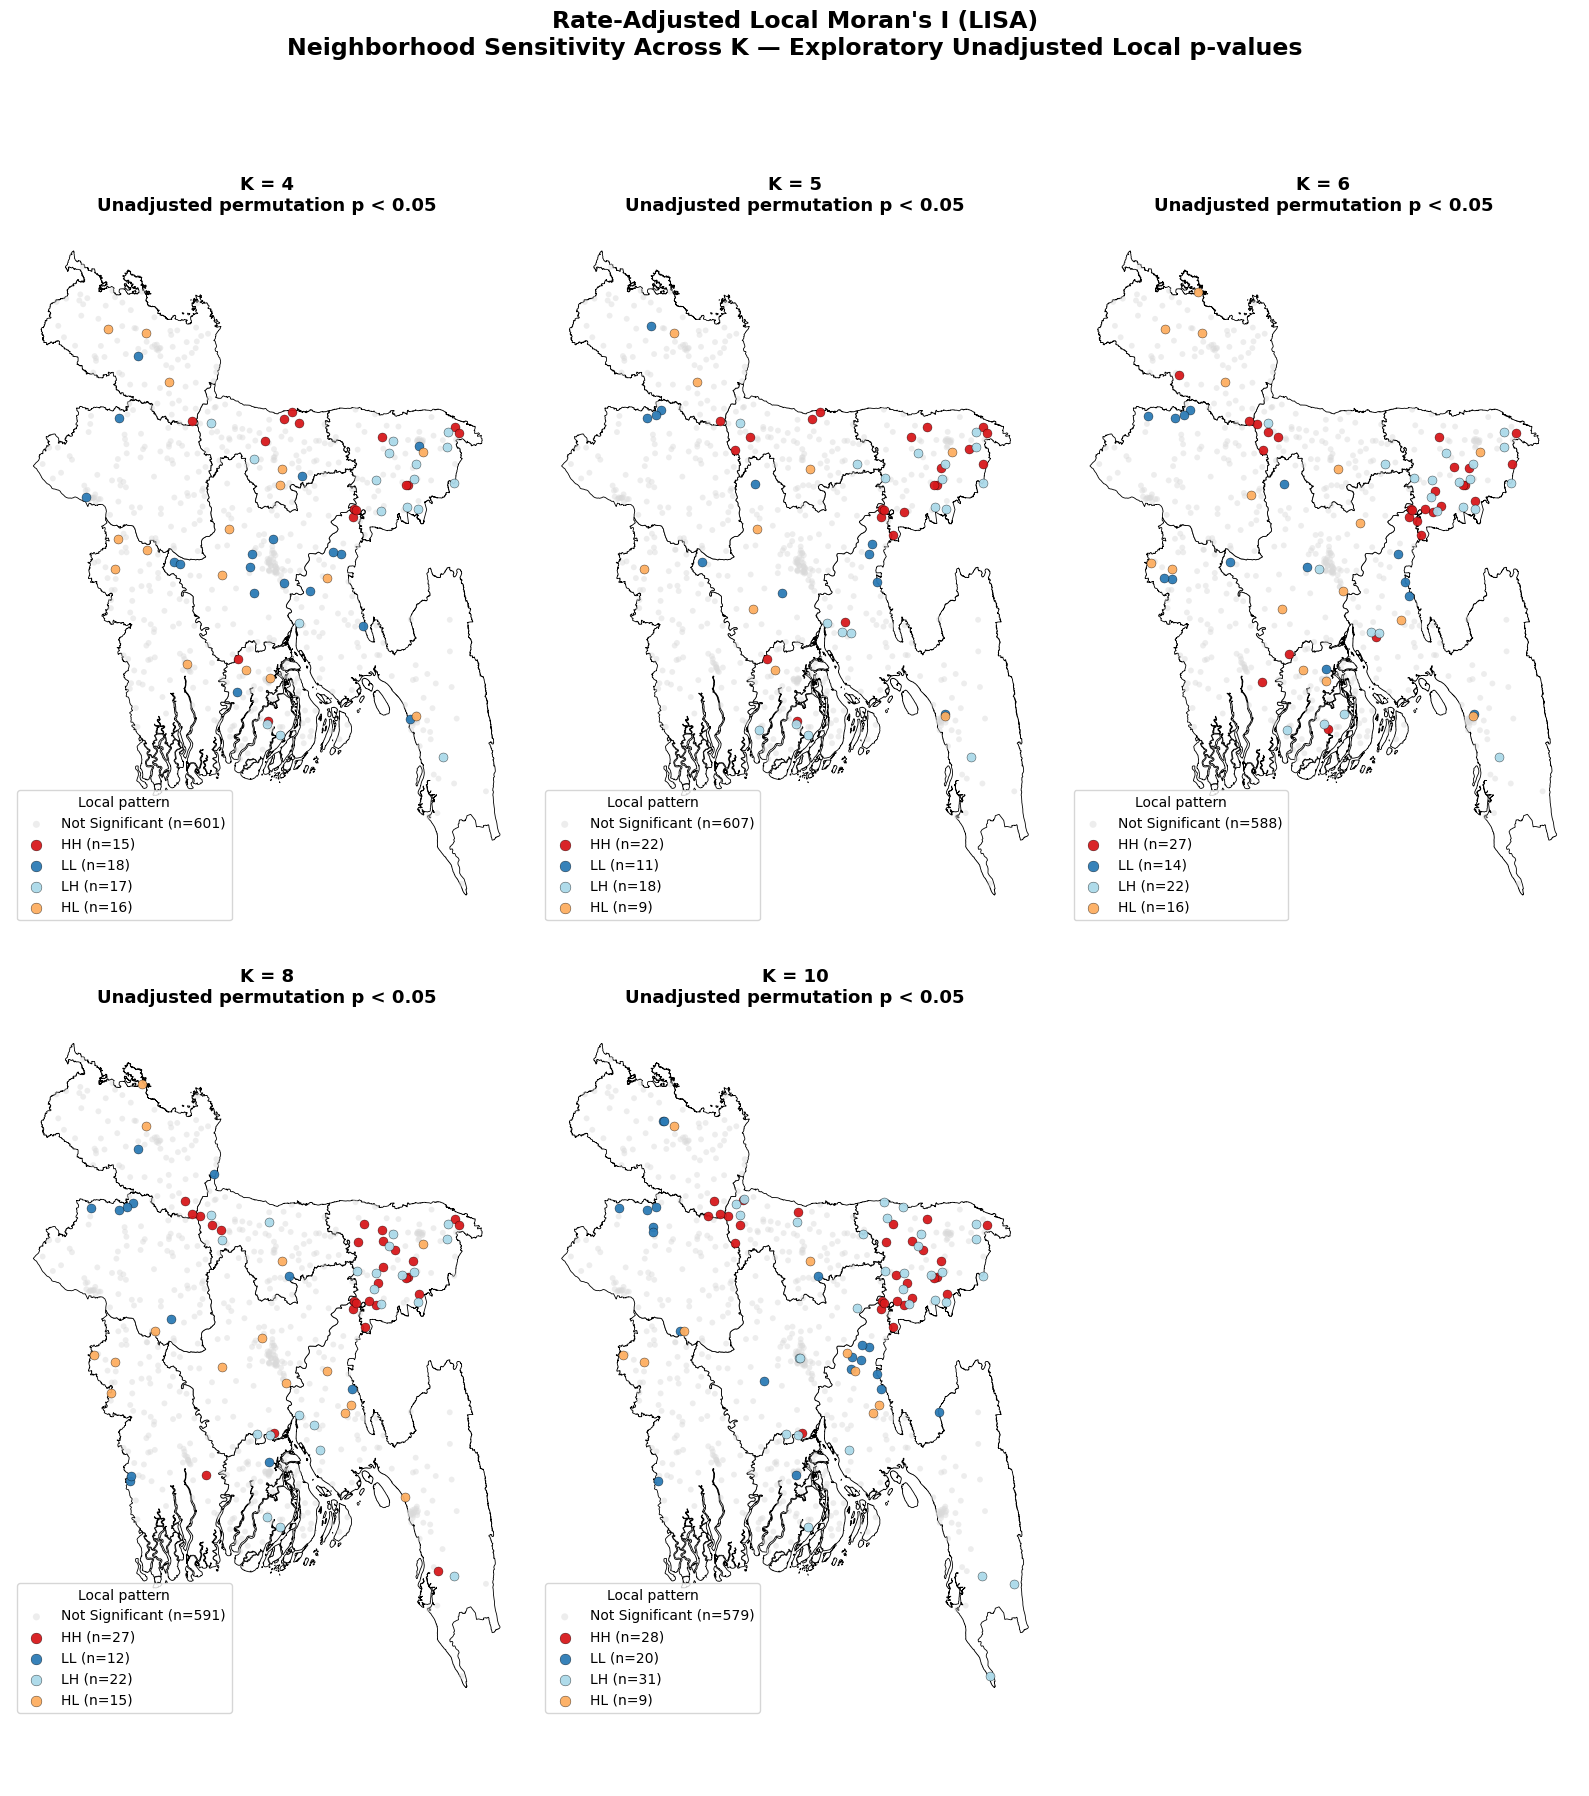

In [7]:
# ==========================================================
# STEP 7 : RATE-ADJUSTED LISA MAPS
# ALL PRESPECIFIED K VALUES
# UNADJUSTED p < 0.05 — EXPLORATORY
# REVIEWER-UPDATED FIGURE READABILITY
# ==========================================================

if not BOUNDARY_FILE.exists():

    raise FileNotFoundError(
        f"Boundary file not found:\n{BOUNDARY_FILE}"
    )


divisions = (
    gpd.read_file(
        BOUNDARY_FILE
    )
    .to_crs(
        "EPSG:4326"
    )
)


lisa_colors = {
    "HH": "#D7191C",
    "LL": "#2C7BB6",
    "LH": "#ABD9E9",
    "HL": "#FDAE61",
    "Not Significant": "#D9D9D9"
}


fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 18)
)


axes = axes.ravel()


for idx, k_try in enumerate(
    K_SENSITIVITY
):

    ax = axes[idx]


    divisions.plot(
        ax=ax,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=1
    )


    class_col = (
        f"LISA_rate_K{k_try}"
    )


    for label in [
        "Not Significant",
        "HH",
        "LL",
        "LH",
        "HL"
    ]:

        d = spatial_df[
            spatial_df[class_col]
            ==
            label
        ]


        if len(d) == 0:
            continue


        ax.scatter(
            d["lon"],
            d["lat"],

            s=(
                42
                if label != "Not Significant"
                else 18
            ),

            c=lisa_colors[label],

            alpha=(
                0.95
                if label != "Not Significant"
                else 0.45
            ),

            edgecolors=(
                "black"
                if label != "Not Significant"
                else "none"
            ),

            linewidths=0.25,

            label=(
                f"{label} (n={len(d)})"
            ),

            zorder=2
        )


    ax.set_title(
        f"K = {k_try}\n"
        "Unadjusted permutation p < 0.05",
        fontsize=13,
        fontweight="bold"
    )


    ax.axis("off")


    ax.legend(
        loc="lower left",
        fontsize=10,
        frameon=True,
        title="Local pattern",
        title_fontsize=10,
        markerscale=1.2
    )


axes[-1].axis("off")


plt.suptitle(
    "Rate-Adjusted Local Moran's I (LISA)\n"
    "Neighborhood Sensitivity Across K — "
    "Exploratory Unadjusted Local p-values",
    fontsize=17,
    fontweight="bold",
    y=0.995
)


plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)


plt.show()

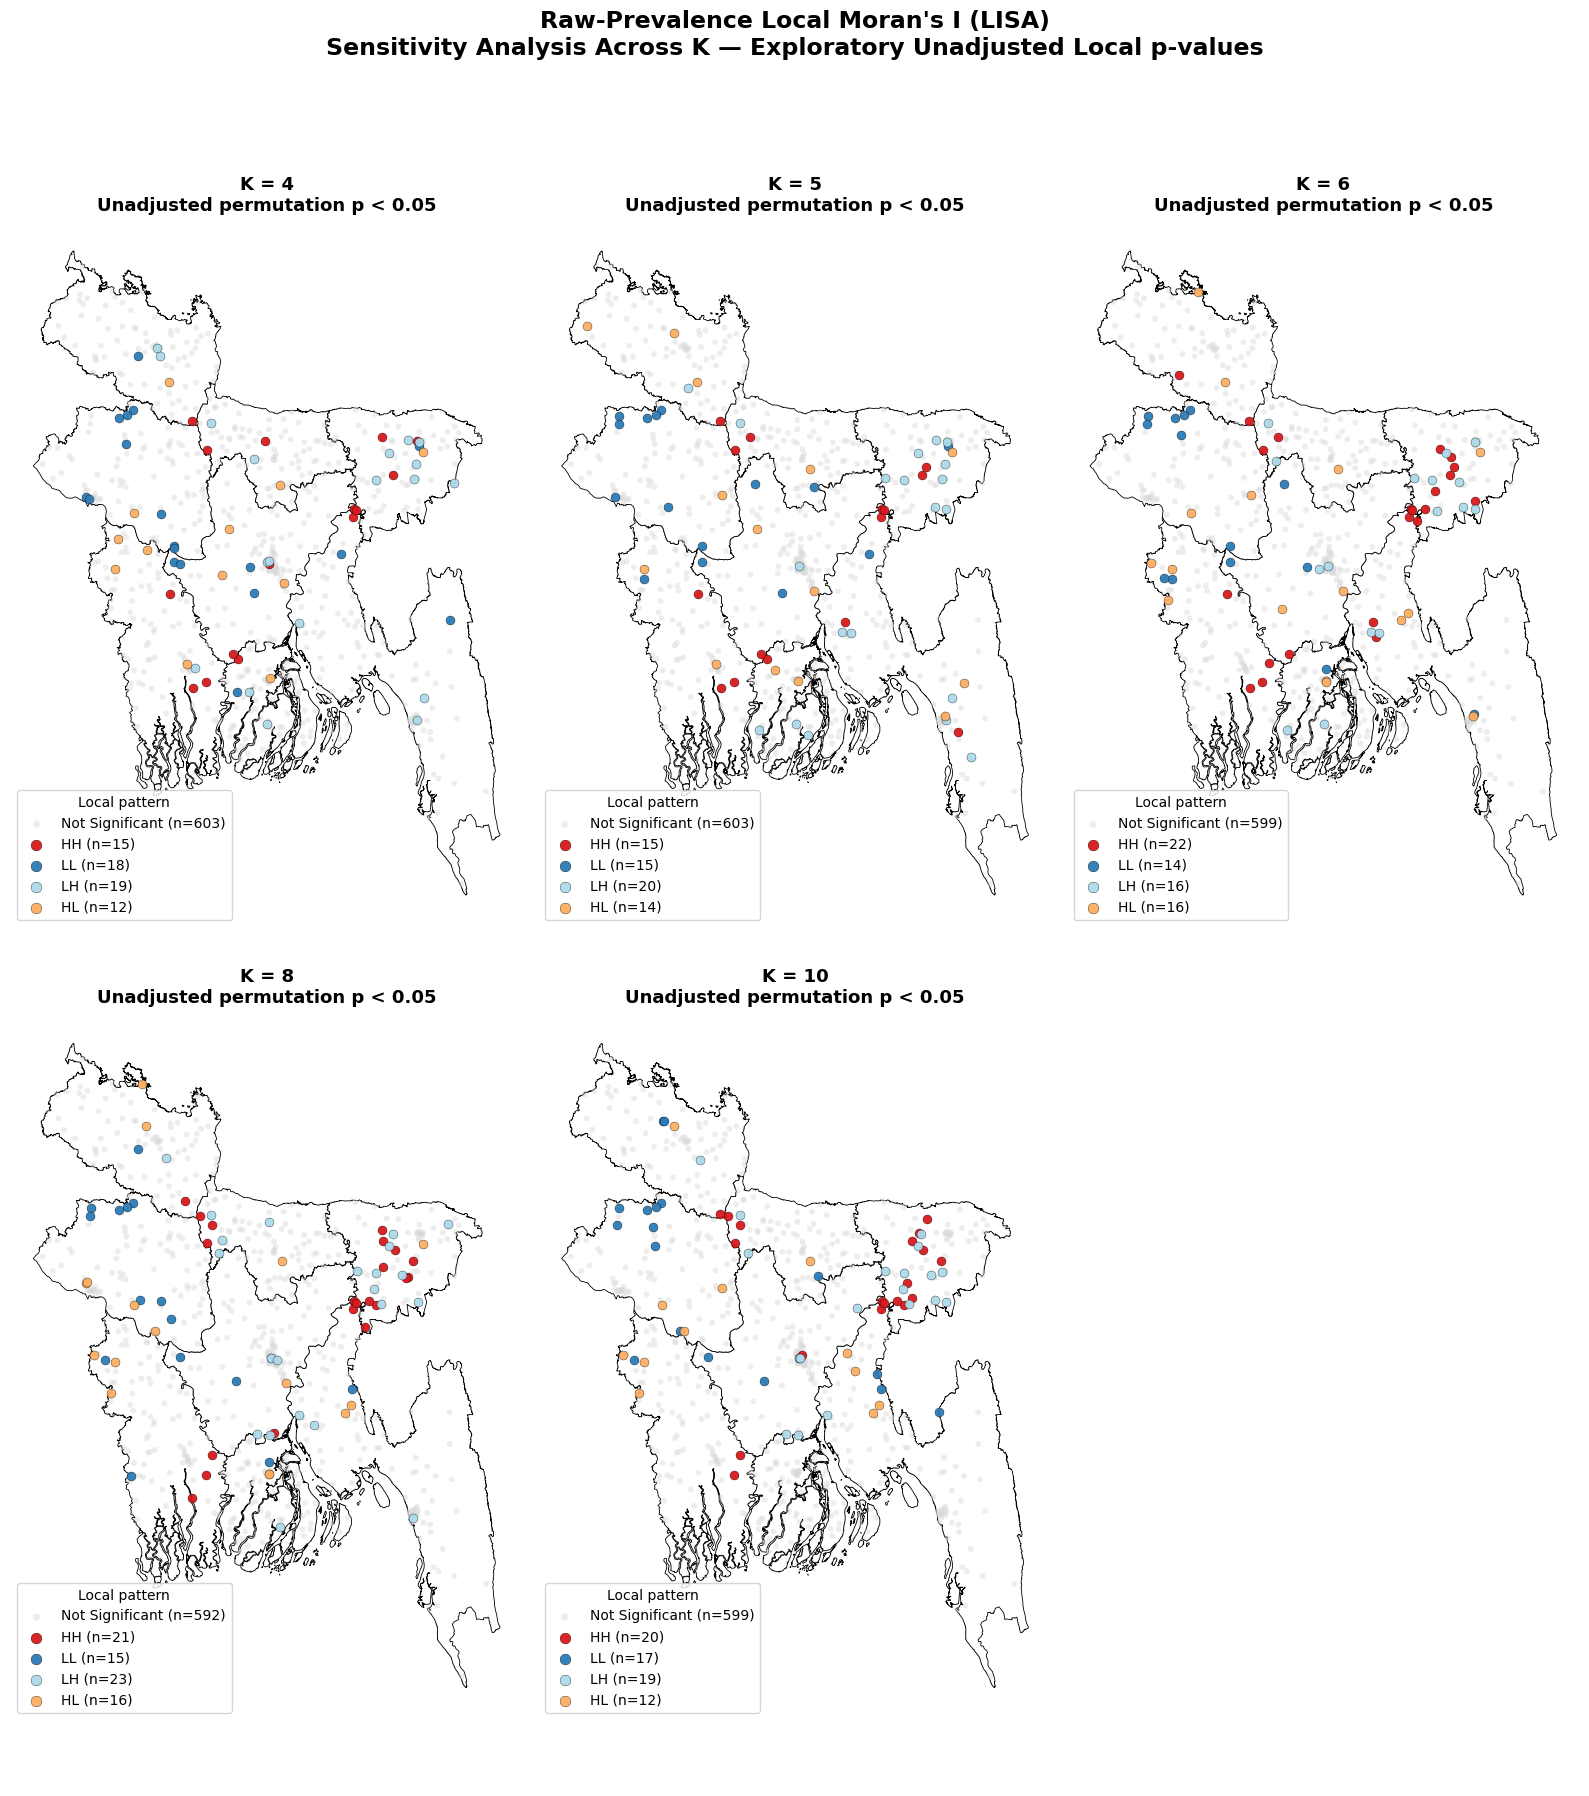

In [8]:
# ==========================================================
# STEP 8 : RAW-PREVALENCE LISA MAPS
# ALL PRESPECIFIED K VALUES
# UNADJUSTED p < 0.05 — SENSITIVITY ONLY
# REVIEWER-UPDATED FIGURE READABILITY
# ==========================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 18)
)


axes = axes.ravel()


for idx, k_try in enumerate(
    K_SENSITIVITY
):

    ax = axes[idx]


    divisions.plot(
        ax=ax,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6,
        zorder=1
    )


    class_col = (
        f"LISA_raw_K{k_try}"
    )


    for label in [
        "Not Significant",
        "HH",
        "LL",
        "LH",
        "HL"
    ]:

        d = spatial_df[
            spatial_df[class_col]
            ==
            label
        ]


        if len(d) == 0:
            continue


        ax.scatter(
            d["lon"],
            d["lat"],

            s=(
                42
                if label != "Not Significant"
                else 18
            ),

            c=lisa_colors[label],

            alpha=(
                0.95
                if label != "Not Significant"
                else 0.45
            ),

            edgecolors=(
                "black"
                if label != "Not Significant"
                else "none"
            ),

            linewidths=0.25,

            label=(
                f"{label} (n={len(d)})"
            ),

            zorder=2
        )


    ax.set_title(
        f"K = {k_try}\n"
        "Unadjusted permutation p < 0.05",
        fontsize=13,
        fontweight="bold"
    )


    ax.axis("off")


    ax.legend(
        loc="lower left",
        fontsize=10,
        frameon=True,
        title="Local pattern",
        title_fontsize=10,
        markerscale=1.2
    )


axes[-1].axis("off")


plt.suptitle(
    "Raw-Prevalence Local Moran's I (LISA)\n"
    "Sensitivity Analysis Across K — "
    "Exploratory Unadjusted Local p-values",
    fontsize=17,
    fontweight="bold",
    y=0.995
)


plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)


plt.show()

In [9]:
# ==========================================================
# STEP 9 : GETIS-ORD Gi*
# ALL K VALUES — UNADJUSTED PERMUTATION p < 0.05
# EXPLORATORY
# ==========================================================

y_eb = spatial_df[
    "stunting_eb"
].to_numpy(dtype=float)


y_raw = spatial_df[
    "stunting"
].to_numpy(dtype=float)


def _gi_class(
    z_values,
    p_values
):

    significant = (
        p_values < ALPHA
    )


    out = np.full(
        len(z_values),
        "Not Significant",
        dtype=object
    )


    out[
        significant
        &
        (z_values > 0)
    ] = "Hot Spot"


    out[
        significant
        &
        (z_values < 0)
    ] = "Cold Spot"


    return out


eb_gi_class_cols = []
raw_gi_class_cols = []

gi_sensitivity_rows = []


for k_try in K_SENSITIVITY:

    w_gi = KNN.from_array(
        coords,
        k=k_try,
        radius=RADIUS_EARTH_KM
    )


    if w_gi.n_components != 1:

        raise RuntimeError(
            f"Gi* weights disconnected at K={k_try}."
        )


    w_gi.transform = "B"


    gi_eb = G_Local(
        y_eb,
        w_gi,
        transform="B",
        permutations=PERMUTATIONS,
        star=True,
        seed=SEED
    )


    eb_z = np.asarray(
        (
            gi_eb.z_sim
            if hasattr(
                gi_eb,
                "z_sim"
            )
            else
            gi_eb.Zs
        ),
        dtype=float
    )


    eb_p = np.asarray(
        gi_eb.p_sim,
        dtype=float
    )


    eb_class = _gi_class(
        eb_z,
        eb_p
    )


    gi_raw = G_Local(
        y_raw,
        w_gi,
        transform="B",
        permutations=PERMUTATIONS,
        star=True,
        seed=SEED
    )


    raw_z = np.asarray(
        (
            gi_raw.z_sim
            if hasattr(
                gi_raw,
                "z_sim"
            )
            else
            gi_raw.Zs
        ),
        dtype=float
    )


    raw_p = np.asarray(
        gi_raw.p_sim,
        dtype=float
    )


    raw_class = _gi_class(
        raw_z,
        raw_p
    )


    eb_col = (
        f"Gi_EB_K{k_try}"
    )

    raw_col = (
        f"Gi_raw_K{k_try}"
    )


    spatial_df[eb_col] = (
        eb_class
    )

    spatial_df[raw_col] = (
        raw_class
    )


    spatial_df[
        f"Gi_EB_p_K{k_try}"
    ] = eb_p


    spatial_df[
        f"Gi_raw_p_K{k_try}"
    ] = raw_p


    eb_gi_class_cols.append(
        eb_col
    )

    raw_gi_class_cols.append(
        raw_col
    )


    for i in range(
        len(spatial_df)
    ):

        gi_sensitivity_rows.append(
            {
                "dhsclust":
                    int(
                        spatial_df.loc[
                            i,
                            "dhsclust"
                        ]
                    ),

                "K":
                    k_try,

                "EB_Gi_Class":
                    eb_class[i],

                "EB_Gi_p":
                    float(
                        eb_p[i]
                    ),

                "Raw_Gi_Class":
                    raw_class[i],

                "Raw_Gi_p":
                    float(
                        raw_p[i]
                    )
            }
        )


gi_sensitivity_long = pd.DataFrame(
    gi_sensitivity_rows
)


spatial_df[
    "Gi_EB_significant_K_count"
] = (
    spatial_df[
        eb_gi_class_cols
    ]
    .ne("Not Significant")
    .sum(axis=1)
)


spatial_df[
    "Gi_raw_significant_K_count"
] = (
    spatial_df[
        raw_gi_class_cols
    ]
    .ne("Not Significant")
    .sum(axis=1)
)


print(
    "=" * 70
)

print(
    "GETIS-ORD Gi* K-SENSITIVITY"
)

print(
    "=" * 70
)

print(
    "All local Gi* classifications use "
    "unadjusted permutation p < 0.05."
)

print(
    "These hotspot/coldspot results are "
    "exploratory rather than multiplicity-adjusted "
    "confirmatory findings."
)


for k_try in K_SENSITIVITY:

    print(
        f"\nK={k_try} — EB Gi*"
    )

    print(
        spatial_df[
            f"Gi_EB_K{k_try}"
        ].value_counts()
    )


    print(
        f"K={k_try} — Raw Gi*"
    )

    print(
        spatial_df[
            f"Gi_raw_K{k_try}"
        ].value_counts()
    )


raw_gi_sensitivity_table = spatial_df[
    [
        "dhsclust",
        "n_children",
        "stunting",
        "stunting_eb",
        *raw_gi_class_cols,
        "Gi_raw_significant_K_count"
    ]
].copy()


display(
    raw_gi_sensitivity_table.head(30)
)


print(
    "\nRaw-prevalence Gi* remains a sensitivity "
    "analysis and should be interpreted alongside "
    "rate-adjusted LISA and EB-smoothed Gi*."
)

GETIS-ORD Gi* K-SENSITIVITY
All local Gi* classifications use unadjusted permutation p < 0.05.
These hotspot/coldspot results are exploratory rather than multiplicity-adjusted confirmatory findings.

K=4 — EB Gi*
Gi_EB_K4
Not Significant    592
Hot Spot            42
Cold Spot           33
Name: count, dtype: int64
K=4 — Raw Gi*
Gi_raw_K4
Not Significant    599
Hot Spot            34
Cold Spot           34
Name: count, dtype: int64

K=5 — EB Gi*
Gi_EB_K5
Not Significant    604
Hot Spot            42
Cold Spot           21
Name: count, dtype: int64
K=5 — Raw Gi*
Gi_raw_K5
Not Significant    601
Hot Spot            36
Cold Spot           30
Name: count, dtype: int64

K=6 — EB Gi*
Gi_EB_K6
Not Significant    588
Hot Spot            51
Cold Spot           28
Name: count, dtype: int64
K=6 — Raw Gi*
Gi_raw_K6
Not Significant    597
Hot Spot            38
Cold Spot           32
Name: count, dtype: int64

K=8 — EB Gi*
Gi_EB_K8
Not Significant    587
Hot Spot            52
Cold Spot           2

,dhsclust,n_children,stunting,stunting_eb,Gi_raw_K4,Gi_raw_K5,Gi_raw_K6,Gi_raw_K8,Gi_raw_K10,Gi_raw_significant_K_count
0,1,4,0.000000,0.202753,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0
1,2,7,0.142857,0.214381,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0
2,3,4,0.000000,0.202753,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0
3,4,3,0.333333,0.243265,Not Significant,Cold Spot,Cold Spot,Cold Spot,Not Significant,3
4,5,9,0.222222,0.230387,Not Significant,Not Significant,Cold Spot,Cold Spot,Not Significant,2
5,6,6,0.166667,0.220940,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0
6,7,2,0.000000,0.216888,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0
7,8,6,0.166667,0.220940,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0
8,9,4,0.000000,0.202753,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0
9,10,3,0.333333,0.243265,Not Significant,Not Significant,Not Significant,Not Significant,Not Significant,0



Raw-prevalence Gi* remains a sensitivity analysis and should be interpreted alongside rate-adjusted LISA and EB-smoothed Gi*.


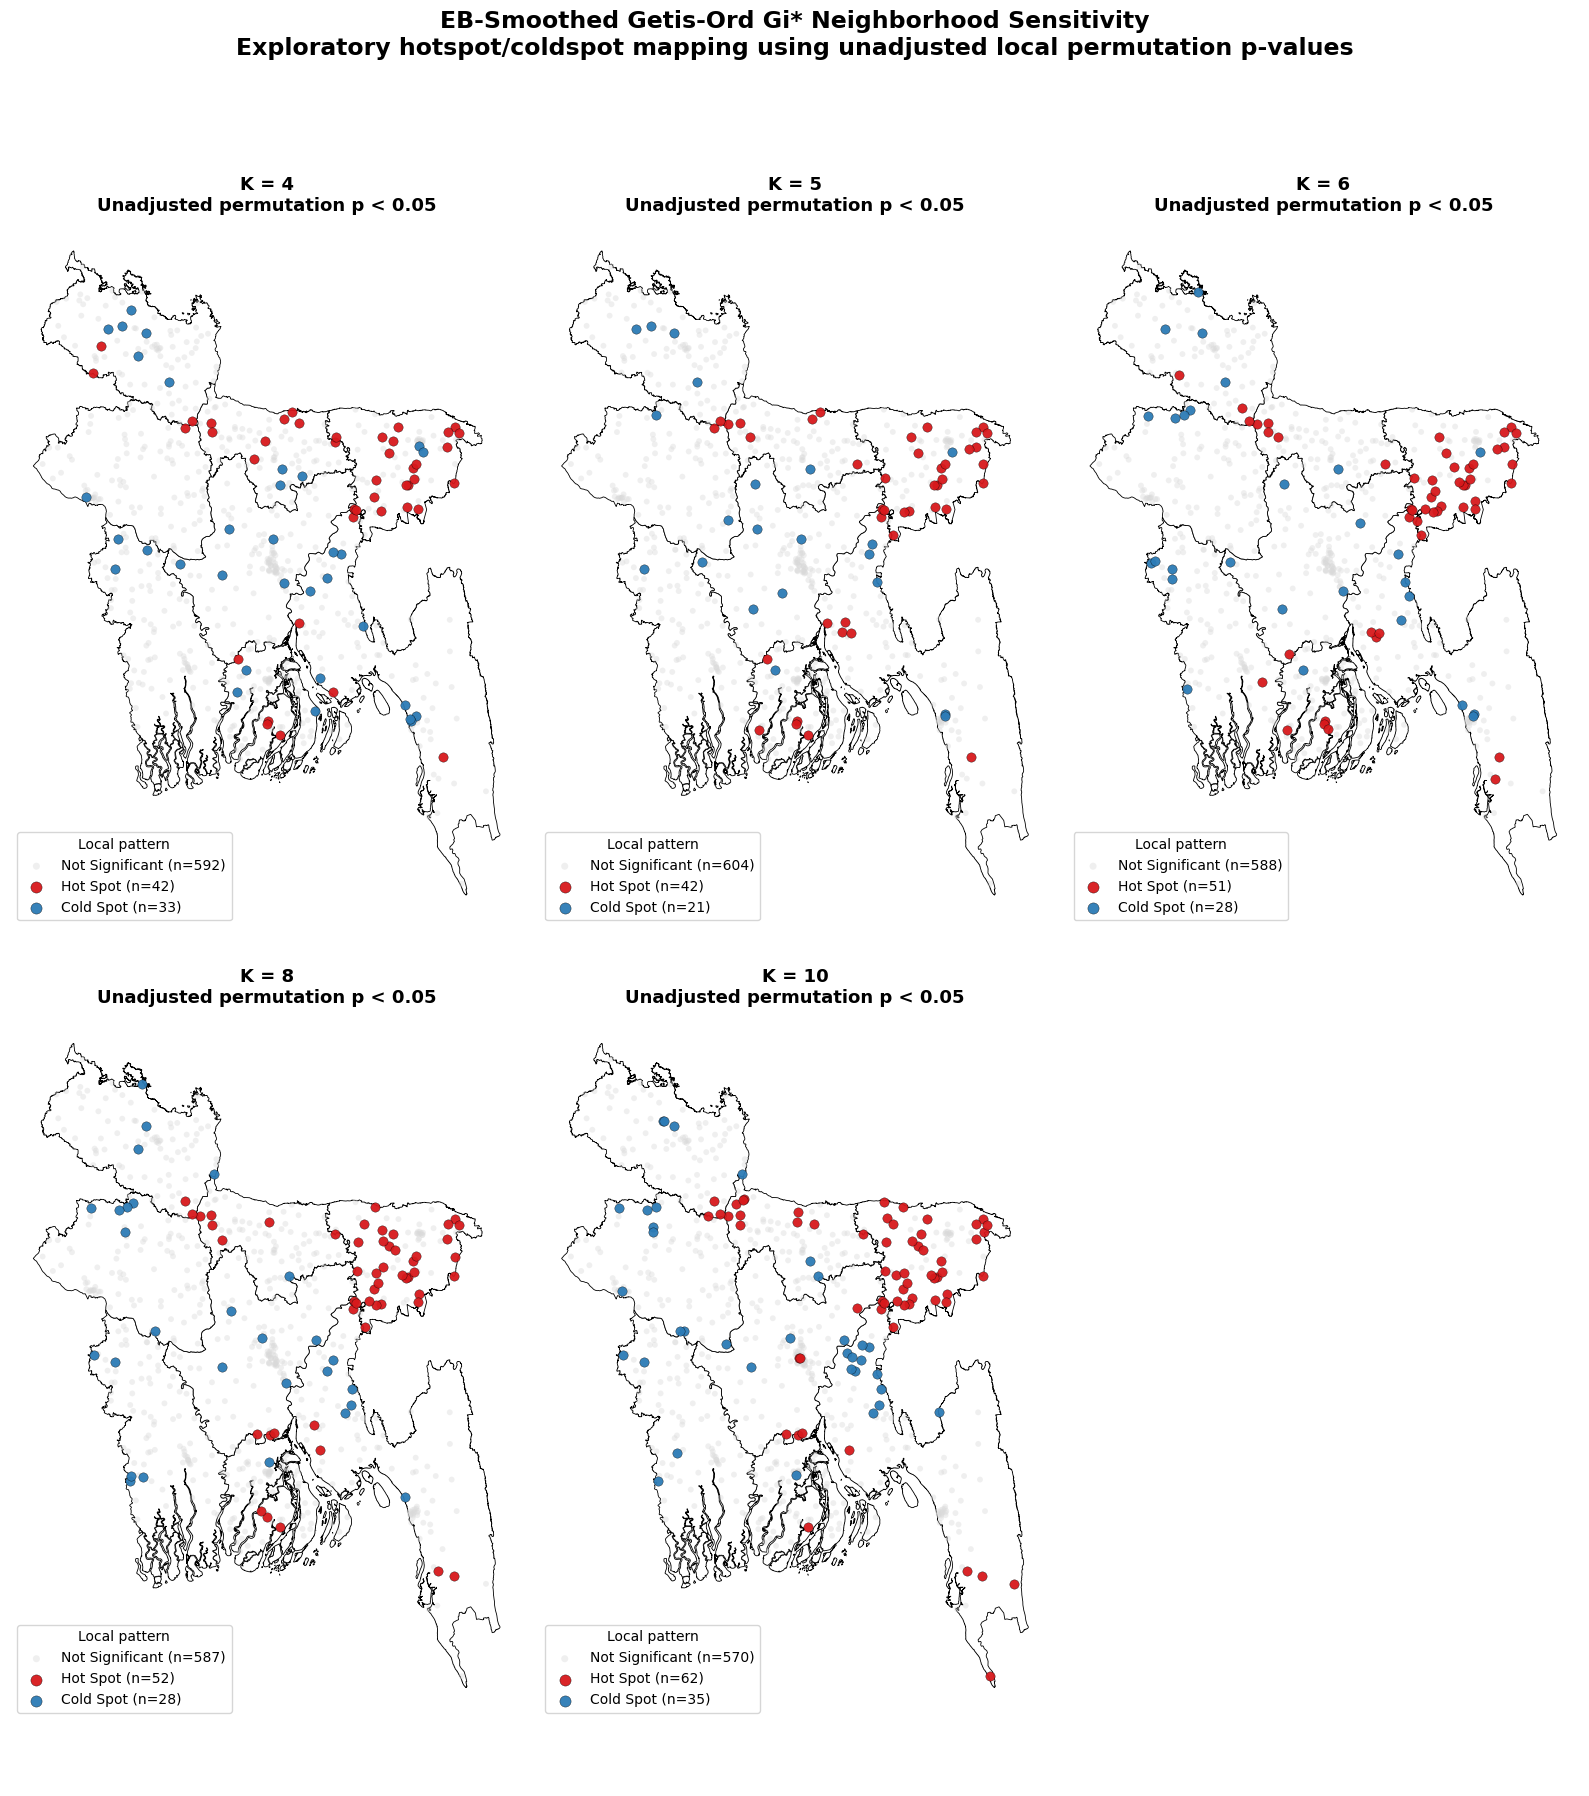

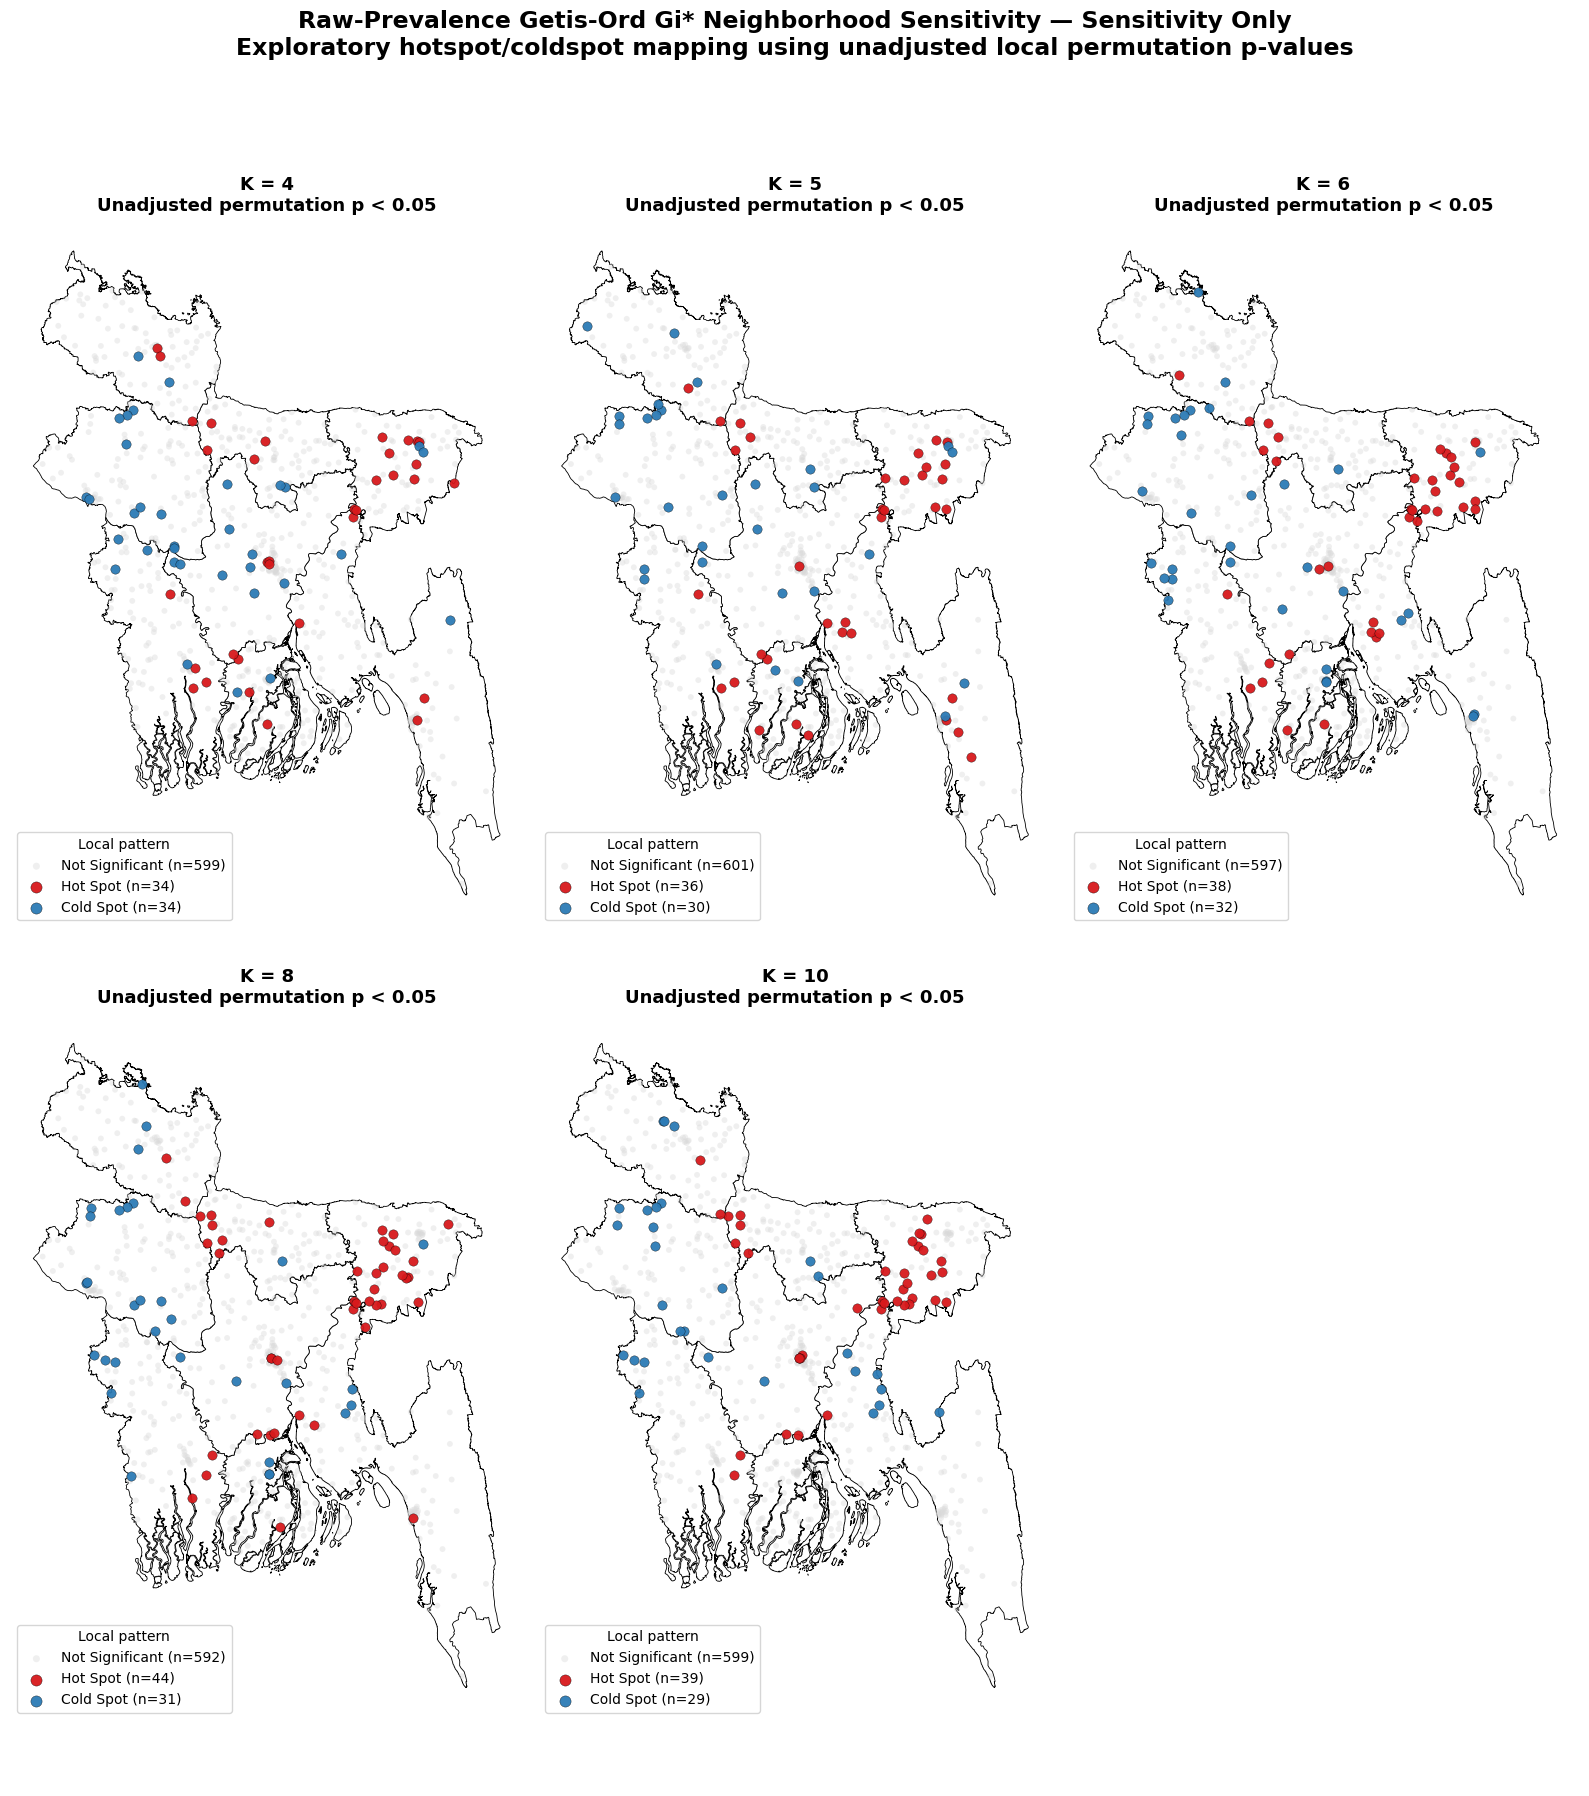

Maps display unadjusted p < 0.05 local hotspot/coldspot classifications.
They should be described as exploratory local patterns, not multiplicity-adjusted confirmatory hotspot inference.


In [10]:
# ==========================================================
# STEP 10 : GETIS-ORD Gi* MAPS
# UNADJUSTED p < 0.05 — EXPLORATORY
# REVIEWER-UPDATED FIGURE READABILITY
# ==========================================================

getis_colors = {
    "Hot Spot": "#D7191C",
    "Cold Spot": "#2C7BB6",
    "Not Significant": "#D9D9D9"
}


def plot_gi_sensitivity(
    class_prefix,
    figure_title
):

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(16, 18)
    )


    axes = axes.ravel()


    for idx, k_try in enumerate(
        K_SENSITIVITY
    ):

        ax = axes[idx]


        divisions.plot(
            ax=ax,
            facecolor="white",
            edgecolor="black",
            linewidth=0.6,
            zorder=1
        )


        class_col = (
            f"{class_prefix}{k_try}"
        )


        for label in [
            "Not Significant",
            "Hot Spot",
            "Cold Spot"
        ]:

            d = spatial_df[
                spatial_df[class_col]
                ==
                label
            ]


            if len(d) == 0:
                continue


            ax.scatter(
                d["lon"],
                d["lat"],

                s=(
                    45
                    if label != "Not Significant"
                    else 18
                ),

                c=getis_colors[label],

                alpha=(
                    0.95
                    if label != "Not Significant"
                    else 0.40
                ),

                edgecolors=(
                    "black"
                    if label != "Not Significant"
                    else "none"
                ),

                linewidths=0.25,

                label=(
                    f"{label} (n={len(d)})"
                ),

                zorder=2
            )


        ax.set_title(
            f"K = {k_try}\n"
            "Unadjusted permutation p < 0.05",
            fontsize=13,
            fontweight="bold"
        )


        ax.axis("off")


        ax.legend(
            loc="lower left",
            fontsize=10,
            frameon=True,
            title="Local pattern",
            title_fontsize=10,
            markerscale=1.2
        )


    axes[-1].axis("off")


    plt.suptitle(
        figure_title
        +
        "\nExploratory hotspot/coldspot mapping "
        "using unadjusted local permutation p-values",
        fontsize=17,
        fontweight="bold",
        y=0.995
    )


    plt.tight_layout(
        rect=[0, 0, 1, 0.96]
    )


    plt.show()


# ==========================================================
# EB-SMOOTHED Gi*
# ==========================================================

plot_gi_sensitivity(
    "Gi_EB_K",
    "EB-Smoothed Getis-Ord Gi* "
    "Neighborhood Sensitivity"
)


# ==========================================================
# RAW-PREVALENCE Gi*
# ==========================================================

plot_gi_sensitivity(
    "Gi_raw_K",
    "Raw-Prevalence Getis-Ord Gi* "
    "Neighborhood Sensitivity — Sensitivity Only"
)


print(
    "Maps display unadjusted p < 0.05 local "
    "hotspot/coldspot classifications."
)


print(
    "They should be described as exploratory "
    "local patterns, not multiplicity-adjusted "
    "confirmatory hotspot inference."
)

In [11]:
# ==========================================================
# STEP 11 : PREPARE GWR / MGWR DATA
# EXPLORATORY EB-GAUSSIAN ANALYSES
# ==========================================================

model_df = (

    model_df

    .copy()

    .reset_index(
        drop=True
    )
)


model_df[
    GWR_VARS
] = (

    model_df[
        GWR_VARS
    ]

    .replace(

        [
            np.inf,
            -np.inf
        ],

        np.nan
    )
)


model_df = (

    model_df

    .dropna(

        subset=

        GWR_VARS

        +

        [

            "stunting",

            "stunting_eb",

            "stunted_cases",

            "n_children",

            "lon",

            "lat"
        ]
    )

    .reset_index(
        drop=True
    )
)


coords_gwr = list(

    zip(

        model_df[
            "lon"
        ]
        .astype(
            float
        ),

        model_df[
            "lat"
        ]
        .astype(
            float
        )
    )
)


coords_gwr_array = (

    model_df[
        [
            "lon",
            "lat"
        ]
    ]

    .to_numpy(
        dtype=float
    )
)


y_gwr = (

    model_df[
        [
            "stunting_eb"
        ]
    ]

    .to_numpy(
        dtype=float
    )
)


y_raw_gwr = (

    model_df[
        [
            "stunting"
        ]
    ]

    .to_numpy(
        dtype=float
    )
)


X_raw = (

    model_df[
        GWR_VARS
    ]

    .to_numpy(
        dtype=float
    )
)


scaler = StandardScaler()


X_gwr = scaler.fit_transform(

    X_raw
)


if not np.isfinite(
    X_gwr
).all():

    raise ValueError(

        "X_gwr contains NaN "
        "or infinite values."
    )


if not np.isfinite(
    y_gwr
).all():

    raise ValueError(

        "y_gwr contains NaN "
        "or infinite values."
    )


if not np.isfinite(
    y_raw_gwr
).all():

    raise ValueError(

        "y_raw_gwr contains NaN "
        "or infinite values."
    )


vif_table = pd.DataFrame(

    {

        "Variable":
            GWR_VARS,

        "VIF":
            [

                variance_inflation_factor(

                    X_gwr,

                    i
                )

                for i in range(

                    X_gwr.shape[
                        1
                    ]
                )
            ]
    }
)


print(
    "GLOBAL VIF"
)


print(
    "----------"
)


display(

    vif_table.round(
        3
    )
)


w_model_moran_by_k = {}


for k_try in K_SENSITIVITY:

    w_tmp = KNN.from_array(

        coords_gwr_array,

        k=k_try,

        radius=RADIUS_EARTH_KM
    )


    if w_tmp.n_components != 1:

        raise RuntimeError(

            "GWR/MGWR residual spatial "
            "weights are disconnected at "
            f"K={k_try}."
        )


    w_tmp.transform = "R"


    w_model_moran_by_k[
        k_try
    ] = w_tmp


print(

    "\nGWR/MGWR observations:",

    len(
        model_df
    )
)


print(

    "Predictors:",

    len(
        GWR_VARS
    )
)


print(

    "Predictor list:",

    GWR_VARS
)


print(

    "\nGWR/MGWR are exploratory spatial-scale "
    "and coefficient-surface analyses conditional "
    "on the EB-smoothed cluster outcome."
)


print(

    "The EB outcome is an estimated posterior mean; "
    "its smoothing uncertainty is not propagated "
    "into Gaussian local standard errors."
)


print(

    "The unweighted grouped-binomial cluster-level "
    "ecological analysis in STEP 13 remains the "
    "denominator-aware inferential analysis for "
    "the analytical sample."
)

GLOBAL VIF
----------


,Variable,VIF
0,flood_occurrence_pct,1.032
1,Mother_secondary_plus_prop,1.276
2,Wealth_poor_prop,1.332
3,Maternal_Height,1.105
4,BMI,1.210
5,Diarrhea,1.019
6,Child_Age_Months,1.047



GWR/MGWR observations: 667
Predictors: 7
Predictor list: ['flood_occurrence_pct', 'Mother_secondary_plus_prop', 'Wealth_poor_prop', 'Maternal_Height', 'BMI', 'Diarrhea', 'Child_Age_Months']

GWR/MGWR are exploratory spatial-scale and coefficient-surface analyses conditional on the EB-smoothed cluster outcome.
The EB outcome is an estimated posterior mean; its smoothing uncertainty is not propagated into Gaussian local standard errors.
The unweighted grouped-binomial cluster-level ecological analysis in STEP 13 remains the denominator-aware inferential analysis for the analytical sample.


In [12]:
# ==========================================================
# STEP 12 : GLOBAL OLS BASELINE
# EB-SMOOTHED OUTCOME
# NO FDR
# ==========================================================

from statsmodels.stats.stattools import (
    jarque_bera
)


X_ols = sm.add_constant(
    X_gwr,
    has_constant="add"
)


ols_results = sm.OLS(
    y_gwr.ravel(),
    X_ols
).fit()


n_ols = int(
    ols_results.nobs
)

k_ols = len(
    ols_results.params
)


ols_aicc = (
    -2 * ols_results.llf
    +
    (
        2
        *
        n_ols
        *
        (k_ols + 1)
    )
    /
    (
        n_ols
        -
        k_ols
        -
        2
    )
)


print(
    "=" * 70
)

print(
    "GLOBAL OLS BASELINE — EB-SMOOTHED OUTCOME"
)

print(
    "=" * 70
)


print(
    "AIC:",
    round(
        ols_results.aic,
        4
    )
)

print(
    "AICc:",
    round(
        ols_aicc,
        4
    )
)

print(
    "R2:",
    round(
        ols_results.rsquared,
        4
    )
)

print(
    "Adjusted R2:",
    round(
        ols_results.rsquared_adj,
        4
    )
)


(
    jb_stat,
    jb_p,
    resid_skew,
    resid_kurtosis
) = jarque_bera(
    ols_results.resid
)


print(
    "\nOLS RESIDUAL NORMALITY"
)

print(
    "Jarque-Bera:",
    round(
        jb_stat,
        5
    )
)

print(
    "JB p-value:",
    round(
        jb_p,
        5
    )
)

print(
    "Skewness:",
    round(
        resid_skew,
        5
    )
)

print(
    "Kurtosis:",
    round(
        resid_kurtosis,
        5
    )
)


if jb_p < ALPHA:

    print(
        "Residual normality is rejected. "
        "EB-based OLS/GWR/MGWR are therefore "
        "treated as exploratory coefficient-surface "
        "and spatial-scale analyses."
    )


ols_resid_rows = []


for k_try in K_SENSITIVITY:

    np.random.seed(SEED)


    m = Moran(
        ols_results.resid,
        w_model_moran_by_k[k_try],
        transformation="R",
        permutations=PERMUTATIONS
    )


    ols_resid_rows.append(
        {
            "K":
                k_try,

            "Residual_Moran_I":
                m.I,

            "Residual_Moran_p":
                m.p_sim
        }
    )


ols_resid_moran_df = pd.DataFrame(
    ols_resid_rows
)


print(
    "\nOLS RESIDUAL MORAN — "
    "NEIGHBORHOOD SENSITIVITY"
)


display(
    ols_resid_moran_df.round(5)
)


print(
    ols_results.summary(
        xname=[
            "Intercept"
        ]
        +
        GWR_VARS
    )
)

GLOBAL OLS BASELINE — EB-SMOOTHED OUTCOME
AIC: -2758.3822
AICc: -2756.1082
R2: 0.1409
Adjusted R2: 0.1317

OLS RESIDUAL NORMALITY
Jarque-Bera: 157.50307
JB p-value: 0.0
Skewness: 0.83465
Kurtosis: 4.69726
Residual normality is rejected. EB-based OLS/GWR/MGWR are therefore treated as exploratory coefficient-surface and spatial-scale analyses.

OLS RESIDUAL MORAN — NEIGHBORHOOD SENSITIVITY


,K,Residual_Moran_I,Residual_Moran_p
0,4,0.02080,0.1846
1,5,0.02334,0.1352
2,6,0.02011,0.1456
3,8,0.01316,0.2019
4,10,0.00966,0.2275


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.141
Model:                            OLS   Adj. R-squared:                  0.132
Method:                 Least Squares   F-statistic:                     15.44
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           8.81e-19
Time:                        00:03:31   Log-Likelihood:                 1387.2
No. Observations:                 667   AIC:                            -2758.
Df Residuals:                     659   BIC:                            -2722.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [13]:
# ==========================================================
# STEP 13 : UNWEIGHTED CLUSTER-LEVEL ECOLOGICAL
# GROUPED-BINOMIAL MODEL
# + REVIEWER-REQUESTED ROBUSTNESS
# ==========================================================

parameter_names = [

    "Intercept"

] + GWR_VARS


def _grouped_endog(
    frame
):

    cases = (

        frame[
            "stunted_cases"
        ]

        .to_numpy(
            dtype=float
        )
    )


    n = (

        frame[
            "n_children"
        ]

        .to_numpy(
            dtype=float
        )
    )


    return np.column_stack(

        [

            cases,

            n
            -
            cases
        ]
    )


def _fit_grouped(
    frame,
    X_design
):

    return sm.GLM(

        _grouped_endog(
            frame
        ),

        X_design,

        family=
            sm.families.Binomial()

    ).fit()


def _result_table(
    result,
    names,
    prefix
):

    ci = np.asarray(

        result.conf_int()
    )


    out = pd.DataFrame(

        {

            "Variable":
                names,

            f"{prefix}Coef":
                np.asarray(
                    result.params
                ),

            f"{prefix}SE":
                np.asarray(
                    result.bse
                ),

            f"{prefix}p":
                np.asarray(
                    result.pvalues
                ),

            f"{prefix}CI_low":
                ci[
                    :,
                    0
                ],

            f"{prefix}CI_high":
                ci[
                    :,
                    1
                ]
        }
    )


    return out


# ==========================================================
# 13.1 FULL GROUPED-BINOMIAL MODEL
# ==========================================================

grouped_binomial_results = _fit_grouped(

    model_df,

    X_ols
)


grouped_binomial_table = (

    _result_table(

        grouped_binomial_results,

        parameter_names,

        ""
    )

    .rename(

        columns={

            "Coef":
                "Coef_log_odds",

            "SE":
                "SE",

            "p":
                "p_value",

            "CI_low":
                "CI_low",

            "CI_high":
                "CI_high"
        }
    )
)


grouped_binomial_table[
    "Odds_Ratio"
] = np.exp(

    grouped_binomial_table[
        "Coef_log_odds"
    ]
)


grouped_binomial_table[
    "OR_CI_low"
] = np.exp(

    grouped_binomial_table[
        "CI_low"
    ]
)


grouped_binomial_table[
    "OR_CI_high"
] = np.exp(

    grouped_binomial_table[
        "CI_high"
    ]
)


grouped_binomial_table[
    "Significant"
] = (

    grouped_binomial_table[
        "p_value"
    ]

    <
    ALPHA
)


print(
    "=" * 70
)


print(

    "UNWEIGHTED CLUSTER-LEVEL ECOLOGICAL "
    "GROUPED-BINOMIAL MODEL"
)


print(
    "=" * 70
)


print(

    "Uses stunted_cases and "
    "n_children directly."
)


print(

    "This is denominator-aware sample-level "
    "ecological inference. It is not DHS "
    "survey-design-adjusted population inference; "
    "sampling weights, strata, and complex-design "
    "uncertainty are not incorporated into these "
    "standard errors."
)


print(

    grouped_binomial_results.summary(

        xname=
            parameter_names
    )
)


display(

    grouped_binomial_table[

        [

            "Variable",

            "Coef_log_odds",

            "SE",

            "p_value",

            "Odds_Ratio",

            "OR_CI_low",

            "OR_CI_high",

            "Significant"
        ]
    ]

    .round(
        5
    )
)


# ==========================================================
# 13.2 GROUPED-BINOMIAL RESIDUAL SPATIAL DIAGNOSTIC
# NO FDR
# ==========================================================

grouped_pearson_resid = np.asarray(
    grouped_binomial_results.resid_pearson
).ravel()


grouped_deviance_resid = np.asarray(
    grouped_binomial_results.resid_deviance
).ravel()


grouped_resid_rows = []


for k_try in K_SENSITIVITY:

    w_tmp = w_model_moran_by_k[
        k_try
    ]


    np.random.seed(SEED)

    mp = Moran(
        grouped_pearson_resid,
        w_tmp,
        transformation="R",
        permutations=PERMUTATIONS
    )


    np.random.seed(SEED)

    md = Moran(
        grouped_deviance_resid,
        w_tmp,
        transformation="R",
        permutations=PERMUTATIONS
    )


    grouped_resid_rows.append(
        {
            "K":
                k_try,

            "Pearson_Moran_I":
                mp.I,

            "Pearson_p":
                mp.p_sim,

            "Deviance_Moran_I":
                md.I,

            "Deviance_p":
                md.p_sim
        }
    )


grouped_residual_moran_df = pd.DataFrame(
    grouped_resid_rows
)


print(
    "\n"
    + "=" * 70
)

print(
    "GROUPED-BINOMIAL RESIDUAL "
    "SPATIAL AUTOCORRELATION"
)

print(
    "=" * 70
)


display(
    grouped_residual_moran_df.round(5)
)


if (
    (
        grouped_residual_moran_df[
            "Pearson_p"
        ]
        <
        ALPHA
    ).any()

    or

    (
        grouped_residual_moran_df[
            "Deviance_p"
        ]
        <
        ALPHA
    ).any()
):

    print(
        "Residual spatial dependence is detected "
        "at unadjusted permutation p < 0.05 under "
        "at least one prespecified neighborhood "
        "definition."
    )

else:

    print(
        "No residual spatial dependence was detected "
        "at unadjusted permutation p < 0.05 across "
        "the prespecified neighborhood definitions."
    )

# ==========================================================
# 13.3 RAW OLS / WLS SENSITIVITY
# ==========================================================

raw_ols_results = sm.OLS(

    y_raw_gwr.ravel(),

    X_ols

).fit()


cluster_precision_weight = (

    model_df[
        "n_children"
    ]

    .to_numpy(
        dtype=float
    )
)


wls_results = sm.WLS(

    y_raw_gwr.ravel(),

    X_ols,

    weights=
        cluster_precision_weight

).fit()


raw_ols_tab = _result_table(

    raw_ols_results,

    parameter_names,

    "Raw_OLS_"
)


wls_tab = _result_table(

    wls_results,

    parameter_names,

    "WLS_"
)


ols_wls_comparison = (

    raw_ols_tab

    .merge(

        wls_tab,

        on="Variable",

        validate="one_to_one"
    )
)


ols_wls_comparison[
    "Absolute_standardized_coef_change_WLS_vs_OLS"
] = (

    ols_wls_comparison[
        "WLS_Coef"
    ]

    -

    ols_wls_comparison[
        "Raw_OLS_Coef"
    ]

).abs()


print(
    "\n"
    +
    "=" * 70
)


print(
    "RAW-PREVALENCE OLS / WLS SENSITIVITY"
)


print(
    "=" * 70
)


print(

    "WLS uses n_children only as an "
    "approximate precision weight."
)


display(

    ols_wls_comparison.round(
        5
    )
)


# ==========================================================
# 13.4 n>=5 / n>=10 GROUPED-BINOMIAL SENSITIVITY
# ==========================================================

mask_n5 = (

    model_df[
        "n_children"
    ]

    .to_numpy(
        dtype=float
    )

    >=
    5
)


mask_n10 = (

    model_df[
        "n_children"
    ]

    .to_numpy(
        dtype=float
    )

    >=
    10
)


def _fit_mask(
    mask
):

    mask = np.asarray(

        mask,

        dtype=bool
    )


    if mask.sum() <= len(
        parameter_names
    ):

        raise ValueError(

            "Too few clusters for "
            "grouped-binomial sensitivity model."
        )


    return _fit_grouped(

        model_df.loc[
            mask
        ]
        .reset_index(
            drop=True
        ),

        X_ols[
            mask,
            :
        ]
    )


grouped_binomial_n5 = _fit_mask(

    mask_n5
)


grouped_binomial_n10 = _fit_mask(

    mask_n10
)


full_tab = _result_table(

    grouped_binomial_results,

    parameter_names,

    "Full_"
)


n5_tab = _result_table(

    grouped_binomial_n5,

    parameter_names,

    "N5_"
)


n10_tab = _result_table(

    grouped_binomial_n10,

    parameter_names,

    "N10_"
)


small_n_sensitivity = (

    full_tab

    .merge(

        n5_tab,

        on="Variable",

        validate="one_to_one"
    )

    .merge(

        n10_tab,

        on="Variable",

        validate="one_to_one"
    )
)


full_abs = (

    small_n_sensitivity[
        "Full_Coef"
    ]

    .abs()

    .replace(
        0,
        np.nan
    )
)


small_n_sensitivity[
    "Absolute_standardized_coef_change_N5_vs_full"
] = (

    small_n_sensitivity[
        "N5_Coef"
    ]

    -

    small_n_sensitivity[
        "Full_Coef"
    ]

).abs()


small_n_sensitivity[
    "Absolute_standardized_coef_change_N10_vs_full"
] = (

    small_n_sensitivity[
        "N10_Coef"
    ]

    -

    small_n_sensitivity[
        "Full_Coef"
    ]

).abs()


small_n_sensitivity[
    "Relative_coef_change_N5_vs_full"
] = (

    small_n_sensitivity[
        "Absolute_standardized_coef_change_N5_vs_full"
    ]

    /

    full_abs
)


small_n_sensitivity[
    "Relative_coef_change_N10_vs_full"
] = (

    small_n_sensitivity[
        "Absolute_standardized_coef_change_N10_vs_full"
    ]

    /

    full_abs
)


print(
    "\n"
    +
    "=" * 70
)


print(
    "GROUPED-BINOMIAL "
    "SMALL-DENOMINATOR SENSITIVITY"
)


print(
    "=" * 70
)


print(

    "Clusters in full model:",

    len(
        model_df
    )
)


print(

    "Clusters with n >= 5:",

    int(
        mask_n5.sum()
    )
)


print(

    "Clusters with n >= 10:",

    int(
        mask_n10.sum()
    )
)


print(

    "The n>=5 and n>=10 models are "
    "sensitivity analyses. Their coefficient "
    "uncertainty is reported with SEs and "
    "95% confidence intervals; sign agreement "
    "alone is not treated as strong confirmation."
)


display(

    small_n_sensitivity.round(
        5
    )
)


# ==========================================================
# 13.5 BOOTSTRAP / RESAMPLING STABILITY
# ==========================================================

rng = np.random.default_rng(

    SEED
)


boot_params = []

boot_failures = 0


n_model = len(

    model_df
)


for _ in range(
    BOOTSTRAP_REPS
):

    idx = rng.integers(

        0,

        n_model,

        size=n_model
    )


    boot_frame = (

        model_df.iloc[
            idx
        ]

        .reset_index(
            drop=True
        )
    )


    boot_X = X_ols[

        idx,

        :
    ]


    try:

        fit_b = _fit_grouped(

            boot_frame,

            boot_X
        )


        params_b = np.asarray(

            fit_b.params,

            dtype=float
        )


        if np.isfinite(
            params_b
        ).all():

            boot_params.append(
                params_b
            )


        else:

            boot_failures += 1


    except Exception:

        boot_failures += 1


if len(
    boot_params
) == 0:

    raise RuntimeError(

        "All grouped-binomial "
        "bootstrap fits failed."
    )


boot_params = np.vstack(

    boot_params
)


full_params = np.asarray(

    grouped_binomial_results.params,

    dtype=float
)


full_sign = np.sign(

    full_params
)


bootstrap_stability_table = pd.DataFrame(

    {

        "Variable":
            parameter_names,

        "Bootstrap_successful_fits":
            boot_params.shape[
                0
            ],

        "Bootstrap_failures":
            boot_failures,

        "Bootstrap_median_coef":
            np.median(

                boot_params,

                axis=0
            ),

        "Bootstrap_CI_2.5":
            np.percentile(

                boot_params,

                2.5,

                axis=0
            ),

        "Bootstrap_CI_97.5":
            np.percentile(

                boot_params,

                97.5,

                axis=0
            ),

        "Bootstrap_sign_agreement_with_full":
            np.mean(

                np.sign(
                    boot_params
                )

                ==

                full_sign,

                axis=0
            )
    }
)


print(
    "\n"
    +
    "=" * 70
)


print(
    "GROUPED-BINOMIAL BOOTSTRAP STABILITY"
)


print(
    "=" * 70
)


print(

    "Requested bootstrap repetitions:",

    BOOTSTRAP_REPS
)


print(

    "Successful fits:",

    boot_params.shape[
        0
    ]
)


print(

    "Failed fits:",

    boot_failures
)


display(

    bootstrap_stability_table.round(
        5
    )
)


# ==========================================================
# 13.6 FULL DIRECTION TABLE
# ==========================================================

coefficient_direction_comparison = pd.DataFrame(

    {

        "Variable":
            parameter_names,

        "EB_OLS_coef":
            ols_results.params,

        "Raw_OLS_coef":
            raw_ols_results.params,

        "WLS_coef":
            wls_results.params,

        "Grouped_binomial_coef":
            grouped_binomial_results.params,

        "Grouped_binomial_n_ge_5_coef":
            grouped_binomial_n5.params,

        "Grouped_binomial_n_ge_10_coef":
            grouped_binomial_n10.params
    }
)


coef_cols = [

    "EB_OLS_coef",

    "Raw_OLS_coef",

    "WLS_coef",

    "Grouped_binomial_coef",

    "Grouped_binomial_n_ge_5_coef",

    "Grouped_binomial_n_ge_10_coef"
]


for col in coef_cols:

    coefficient_direction_comparison[

        col.replace(
            "_coef",
            "_sign"
        )

    ] = np.sign(

        coefficient_direction_comparison[
            col
        ]
    )


# ==========================================================
# 13.7 PREDICTOR-ONLY ROBUSTNESS
# ==========================================================

predictor_direction_comparison = (

    coefficient_direction_comparison.loc[

        coefficient_direction_comparison[
            "Variable"
        ]

        !=
        "Intercept"
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


primary_sensitivity_sign_cols = [

    "Raw_OLS_sign",

    "WLS_sign",

    "Grouped_binomial_sign",

    "Grouped_binomial_n_ge_5_sign",

    "Grouped_binomial_n_ge_10_sign"
]


predictor_direction_comparison[
    "Direction_consistent_raw_and_denominator_aware"
] = (

    predictor_direction_comparison[
        primary_sensitivity_sign_cols
    ]

    .nunique(
        axis=1
    )

    .eq(
        1
    )
)


predictor_direction_comparison[
    "Primary_direction"
] = (

    predictor_direction_comparison[
        "Grouped_binomial_sign"
    ]
)


predictor_direction_comparison[
    "EB_agrees_with_primary_direction"
] = (

    predictor_direction_comparison[
        "Direction_consistent_raw_and_denominator_aware"
    ]

    &

    (

        predictor_direction_comparison[
            "EB_OLS_sign"
        ]

        ==

        predictor_direction_comparison[
            "Primary_direction"
        ]
    )
)


predictor_direction_comparison = (

    predictor_direction_comparison

    .merge(

        small_n_sensitivity[

            [

                "Variable",

                "Full_SE",

                "Full_CI_low",

                "Full_CI_high",

                "N5_SE",

                "N5_CI_low",

                "N5_CI_high",

                "N10_SE",

                "N10_CI_low",

                "N10_CI_high",

                "Absolute_standardized_coef_change_N5_vs_full",

                "Absolute_standardized_coef_change_N10_vs_full",

                "Relative_coef_change_N5_vs_full",

                "Relative_coef_change_N10_vs_full"
            ]
        ],

        on="Variable",

        how="left",

        validate="one_to_one"
    )

    .merge(

        bootstrap_stability_table[

            [

                "Variable",

                "Bootstrap_CI_2.5",

                "Bootstrap_CI_97.5",

                "Bootstrap_sign_agreement_with_full"
            ]
        ],

        on="Variable",

        how="left",

        validate="one_to_one"
    )
)


print(
    "\n"
    +
    "=" * 70
)


print(
    "PREDICTOR ROBUSTNESS AUDIT"
)


print(
    "=" * 70
)


print(

    "Direction consistency is reported only "
    "as one component of robustness; confidence "
    "intervals, standardized coefficient changes, "
    "and bootstrap stability are reported alongside it."
)


display(

    predictor_direction_comparison.round(
        5
    )
)


print(
    "\nINTERPRETATION LIMITS"
)


print(

    "1. Results are sample-level ecological "
    "cluster associations, not individual-level "
    "risk-factor effects."
)


print(

    "2. The grouped-binomial model does not "
    "incorporate DHS sampling weights/strata "
    "into its standard errors and is not "
    "nationally representative design-based inference."
)


print(

    "3. Cluster-level predictor proportions/means "
    "are estimated from small within-cluster samples, "
    "and their measurement uncertainty is not modeled."
)


print(

    "4. EB-OLS/GWR/MGWR remain exploratory "
    "analyses conditional on the EB-smoothed outcome."
)

UNWEIGHTED CLUSTER-LEVEL ECOLOGICAL GROUPED-BINOMIAL MODEL
Uses stunted_cases and n_children directly.
This is denominator-aware sample-level ecological inference. It is not DHS survey-design-adjusted population inference; sampling weights, strata, and complex-design uncertainty are not incorporated into these standard errors.
                 Generalized Linear Model Regression Results                  
Dep. Variable:           ['y1', 'y2']   No. Observations:                  667
Model:                            GLM   Df Residuals:                      659
Model Family:                Binomial   Df Model:                            7
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -823.60
Date:                Thu, 08 Oct 2026   Deviance:                       752.60
Time:                        00:03:32   Pearson chi2:                     650.
No. Iterations:                     5  

,Variable,Coef_log_odds,SE,p_value,Odds_Ratio,OR_CI_low,OR_CI_high,Significant
0,Intercept,-1.28607,0.04213,0.00000,0.27636,0.25445,0.30014,True
1,flood_occurrence_pct,0.02229,0.04013,0.57859,1.02254,0.94519,1.10622,False
2,Mother_secondary_plus_prop,-0.21849,0.04581,0.00000,0.80373,0.73471,0.87923,True
3,Wealth_poor_prop,0.10162,0.04828,0.03530,1.10696,1.00702,1.21682,True
4,Maternal_Height,-0.18868,0.04850,0.00010,0.82805,0.75295,0.91063,True
5,BMI,-0.22502,0.04958,0.00001,0.79850,0.72455,0.88000,True
6,Diarrhea,-0.11634,0.04878,0.01709,0.89017,0.80900,0.97949,True
7,Child_Age_Months,0.03025,0.04800,0.52856,1.03071,0.93817,1.13238,False



GROUPED-BINOMIAL RESIDUAL SPATIAL AUTOCORRELATION


,K,Pearson_Moran_I,Pearson_p,Deviance_Moran_I,Deviance_p
0,4,0.02231,0.1689,0.01957,0.1983
1,5,0.01830,0.1899,0.01549,0.2272
2,6,0.01634,0.1906,0.01506,0.2094
3,8,0.00606,0.3232,0.00484,0.3474
4,10,0.00377,0.3481,0.00200,0.3957


No residual spatial dependence was detected at unadjusted permutation p < 0.05 across the prespecified neighborhood definitions.

RAW-PREVALENCE OLS / WLS SENSITIVITY
WLS uses n_children only as an approximate precision weight.


...


GROUPED-BINOMIAL BOOTSTRAP STABILITY
Requested bootstrap repetitions: 1000
Successful fits: 1000
Failed fits: 0


,Variable,Bootstrap_successful_fits,Bootstrap_failures,Bootstrap_median_coef,Bootstrap_CI_2.5,Bootstrap_CI_97.5,Bootstrap_sign_agreement_with_full
0,Intercept,1000,0,-1.28982,-1.37825,-1.21064,1.000
1,flood_occurrence_pct,1000,0,0.02448,-0.05494,0.09532,0.713
2,Mother_secondary_plus_prop,1000,0,-0.21881,-0.31419,-0.12862,1.000
3,Wealth_poor_prop,1000,0,0.10279,0.00246,0.20282,0.975
4,Maternal_Height,1000,0,-0.18919,-0.29497,-0.09412,1.000
5,BMI,1000,0,-0.22570,-0.32982,-0.12969,1.000
6,Diarrhea,1000,0,-0.11594,-0.20777,-0.02700,0.992
7,Child_Age_Months,1000,0,0.03053,-0.06449,0.12170,0.735



PREDICTOR ROBUSTNESS AUDIT
Direction consistency is reported only as one component of robustness; confidence intervals, standardized coefficient changes, and bootstrap stability are reported alongside it.


,Variable,EB_OLS_coef,Raw_OLS_coef,WLS_coef,Grouped_binomial_coef,Grouped_binomial_n_ge_5_coef,Grouped_binomial_n_ge_10_coef,EB_OLS_sign,Raw_OLS_sign,WLS_sign,...,N10_SE,N10_CI_low,N10_CI_high,Absolute_standardized_coef_change_N5_vs_full,Absolute_standardized_coef_change_N10_vs_full,Relative_coef_change_N5_vs_full,Relative_coef_change_N10_vs_full,Bootstrap_CI_2.5,Bootstrap_CI_97.5,Bootstrap_sign_agreement_with_full
0,flood_occurrence_pct,0.00028,0.00291,0.00317,0.02229,0.00597,0.06956,1.0,1.0,1.0,...,0.09056,-0.10794,0.24705,0.01632,0.04727,0.73212,2.12035,-0.05494,0.09532,0.713
1,Mother_secondary_plus_prop,-0.00618,-0.04617,-0.04050,-0.21849,-0.19072,-0.30556,-1.0,-1.0,-1.0,...,0.11617,-0.53324,-0.07788,0.02777,0.08706,0.12711,0.39847,-0.31419,-0.12862,1.000
2,Wealth_poor_prop,0.00313,0.00691,0.01833,0.10162,0.15426,0.16330,1.0,1.0,1.0,...,0.12466,-0.08104,0.40764,0.05264,0.06168,0.51802,0.60701,0.00246,0.20282,0.975
3,Maternal_Height,-0.00385,-0.03546,-0.03124,-0.18868,-0.14227,-0.06782,-1.0,-1.0,-1.0,...,0.13794,-0.33818,0.20254,0.04641,0.12086,0.24597,0.64056,-0.29497,-0.09412,1.000
4,BMI,-0.00532,-0.03245,-0.03657,-0.22502,-0.21909,-0.45158,-1.0,-1.0,-1.0,...,0.14861,-0.74284,-0.16032,0.00593,0.22656,0.02636,1.00687,-0.32982,-0.12969,1.000
5,Diarrhea,-0.00189,-0.01396,-0.01817,-0.11634,-0.13572,-0.27299,-1.0,-1.0,-1.0,...,0.15787,-0.58240,0.03643,0.01938,0.15664,0.16657,1.34636,-0.20777,-0.02700,0.992
6,Child_Age_Months,0.00076,0.00252,0.00553,0.03025,0.05829,0.05515,1.0,1.0,1.0,...,0.15863,-0.25577,0.36607,0.02804,0.02490,0.92692,0.82327,-0.06449,0.12170,0.735



INTERPRETATION LIMITS
1. Results are sample-level ecological cluster associations, not individual-level risk-factor effects.
2. The grouped-binomial model does not incorporate DHS sampling weights/strata into its standard errors and is not nationally representative design-based inference.
3. Cluster-level predictor proportions/means are estimated from small within-cluster samples, and their measurement uncertainty is not modeled.
4. EB-OLS/GWR/MGWR remain exploratory analyses conditional on the EB-smoothed outcome.


In [14]:
# ==========================================================
# STEP 14 : GWR
# ==========================================================

selector_gwr = Sel_BW(

    coords_gwr,

    y_gwr,

    X_gwr,

    kernel="bisquare",

    fixed=False,

    spherical=True
)


bw_gwr = selector_gwr.search(

    criterion="AICc"
)


gwr_model = GWR(

    coords_gwr,

    y_gwr,

    X_gwr,

    bw=bw_gwr,

    kernel="bisquare",

    fixed=False,

    spherical=True,

    name_x=GWR_VARS
)


gwr_results = (
    gwr_model.fit()
)


print(
    "GWR bandwidth:",
    bw_gwr
)


gwr_results.summary()

GWR bandwidth: 616.0
Model type                                                         Gaussian
Number of observations:                                                 667
Number of covariates:                                                     8

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                              0.610
Log-likelihood:                                                    1387.191
AIC:                                                              -2758.382
AICc:                                                             -2756.108
BIC:                                                              -4284.729
R2:                                                                   0.141
Adj. R2:                                                              0.132

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- -------

In [15]:
# ==========================================================
# STEP 15 : GWR DIAGNOSTICS
# EXPLORATORY EB-GAUSSIAN MODEL
# NO FDR
# ==========================================================

(
    gwr_local_corr,
    gwr_local_vif,
    gwr_local_cn,
    gwr_vdp
) = gwr_results.local_collinearity()


model_df[
    "GWR_local_condition_number"
] = np.asarray(
    gwr_local_cn
).ravel()


print(
    "GWR LOCAL CONDITION NUMBER"
)

print(
    "--------------------------"
)


display(
    model_df[
        "GWR_local_condition_number"
    ]
    .describe()
    .to_frame(
        name="Condition_Number"
    )
    .round(3)
)


print(
    "\nLocations with condition number > 30:",
    int(
        (
            model_df[
                "GWR_local_condition_number"
            ]
            >
            30
        ).sum()
    )
)


gwr_local_vif_df = pd.DataFrame(
    gwr_local_vif,
    columns=GWR_VARS
)


print(
    "\nGWR LOCAL VIF SUMMARY"
)

print(
    "---------------------"
)


display(
    gwr_local_vif_df
    .describe()
    .T
    .round(3)
)


gwr_residuals = np.asarray(
    gwr_results.resid_response
).ravel()


gwr_resid_rows = []


for k_try in K_SENSITIVITY:

    np.random.seed(SEED)


    m = Moran(
        gwr_residuals,
        w_model_moran_by_k[k_try],
        transformation="R",
        permutations=PERMUTATIONS
    )


    gwr_resid_rows.append(
        {
            "K":
                k_try,

            "Residual_Moran_I":
                m.I,

            "Residual_Moran_p":
                m.p_sim
        }
    )


gwr_resid_moran_df = pd.DataFrame(
    gwr_resid_rows
)


print(
    "\nGWR RESIDUAL MORAN — "
    "NEIGHBORHOOD SENSITIVITY"
)


display(
    gwr_resid_moran_df.round(5)
)

GWR LOCAL CONDITION NUMBER
--------------------------


,Condition_Number
count,667.000
mean,2.022
std,0.161
min,1.821
25%,1.872
50%,1.969
75%,2.161
max,2.398



Locations with condition number > 30: 0

GWR LOCAL VIF SUMMARY
---------------------


,count,mean,std,min,25%,50%,75%,max
flood_occurrence_pct,667.0,1.041,0.018,1.015,1.024,1.044,1.059,1.066
Mother_secondary_plus_prop,667.0,1.298,0.035,1.244,1.258,1.309,1.330,1.342
Wealth_poor_prop,667.0,1.357,0.042,1.291,1.326,1.357,1.388,1.438
Maternal_Height,667.0,1.111,0.012,1.079,1.104,1.113,1.119,1.129
BMI,667.0,1.217,0.033,1.148,1.190,1.219,1.244,1.273
Diarrhea,667.0,1.021,0.004,1.014,1.016,1.021,1.025,1.029
Child_Age_Months,667.0,1.053,0.014,1.036,1.043,1.047,1.061,1.089



GWR RESIDUAL MORAN — NEIGHBORHOOD SENSITIVITY


,K,Residual_Moran_I,Residual_Moran_p
0,4,0.01403,0.2653
1,5,0.01415,0.2407
2,6,0.01019,0.2776
3,8,0.00372,0.3708
4,10,0.00150,0.4069


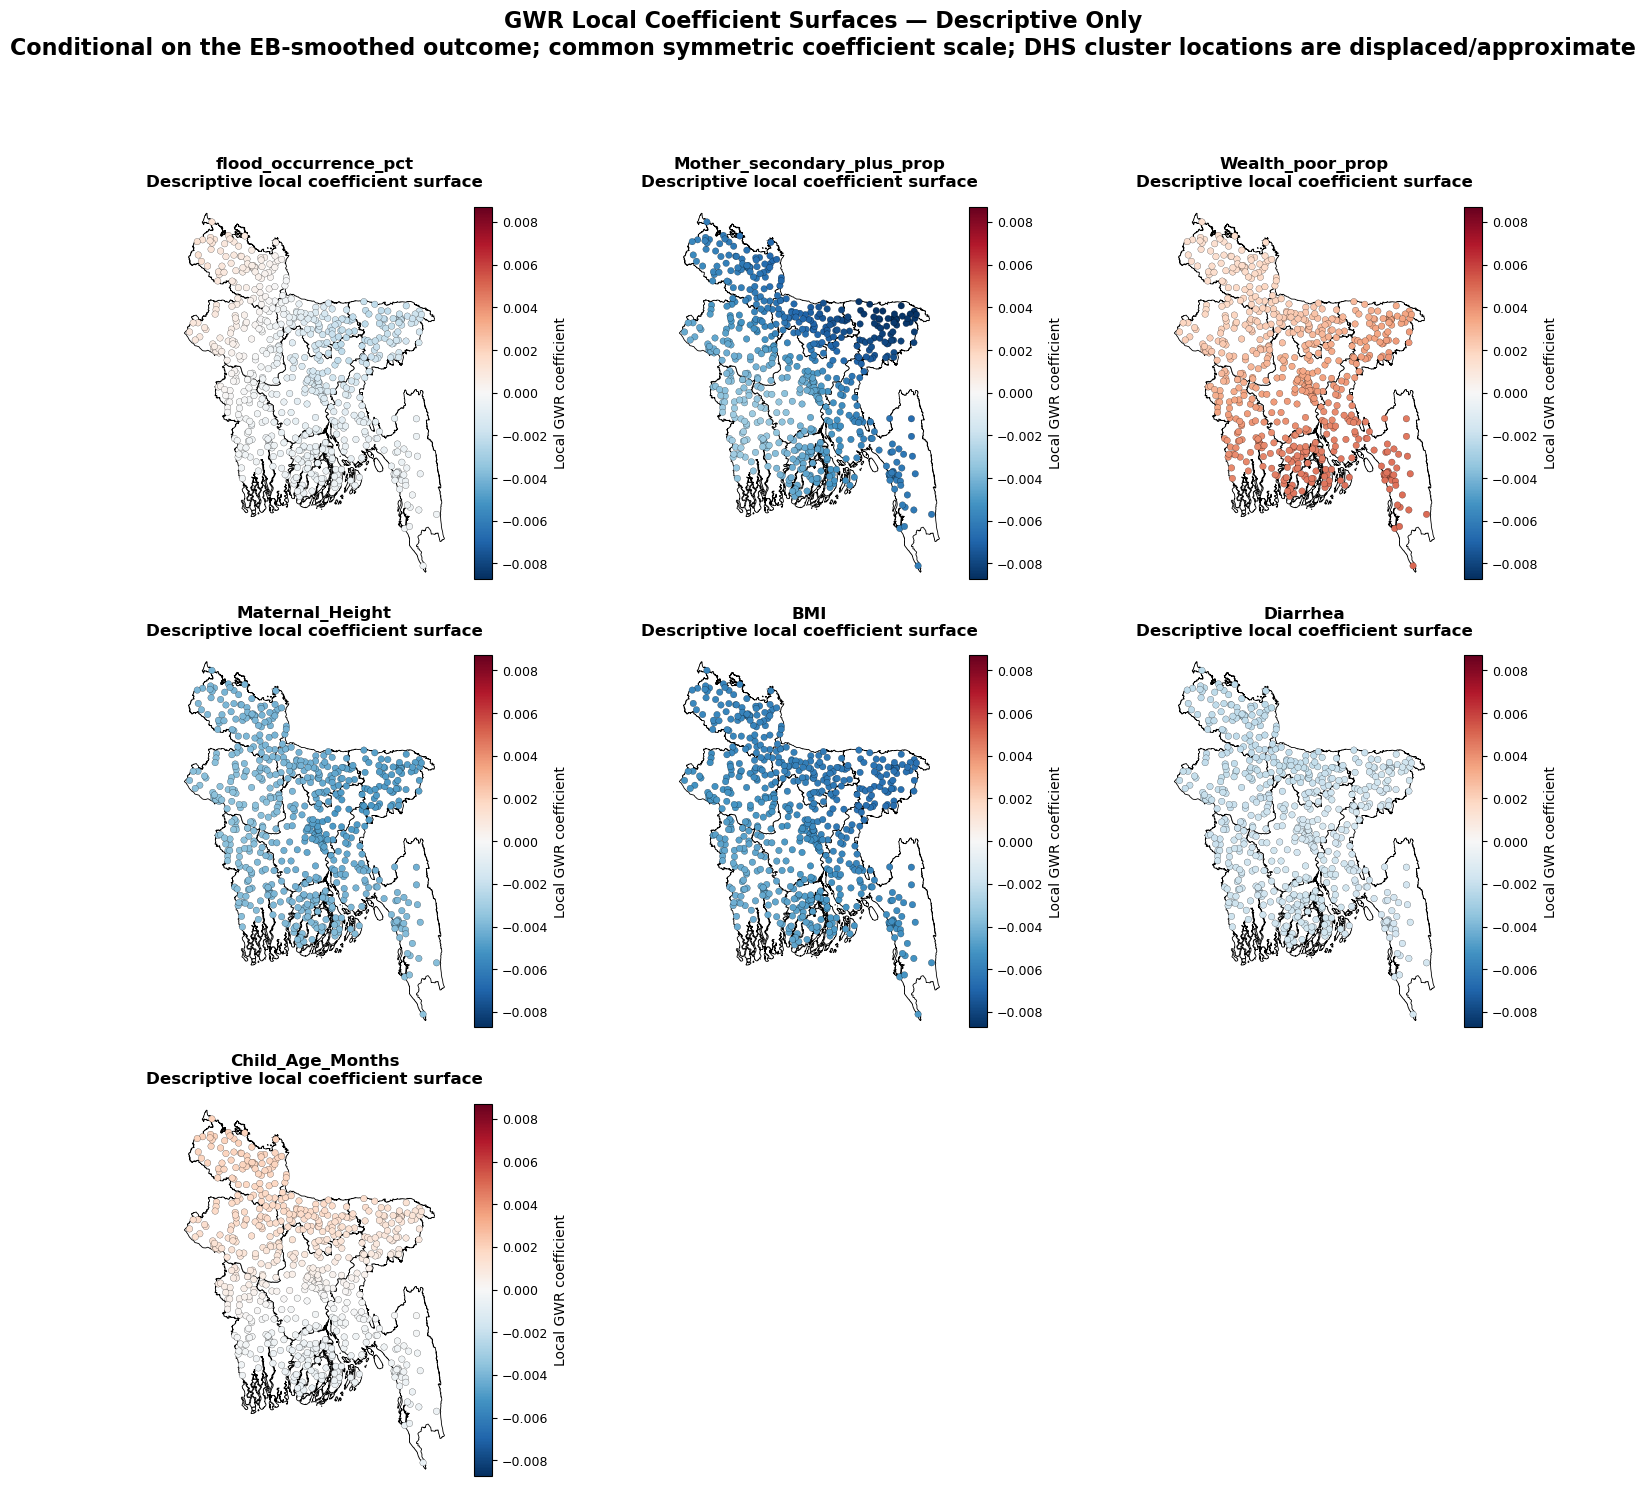

Local GWR coefficient surfaces are presented descriptively.
A common symmetric coefficient scale is used across panels to support direct visual comparison.
No locations are labelled as 'Adjusted-significant'.


In [16]:
# ==========================================================
# STEP 16 : GWR LOCAL COEFFICIENT SURFACES
# DESCRIPTIVE ONLY — CONDITIONAL ON EB OUTCOME
# REVIEWER-UPDATED FIGURE READABILITY
# ==========================================================

n_vars = len(
    GWR_VARS
)


ncols = 3


nrows = int(
    np.ceil(
        n_vars
        /
        ncols
    )
)


# ==========================================================
# COMMON SYMMETRIC COLOR SCALE ACROSS ALL GWR PANELS
# ==========================================================

all_local_coefs = (
    gwr_results.params[
        :,
        1:
        1 + n_vars
    ]
)


global_abs_max = float(
    np.nanmax(
        np.abs(
            all_local_coefs
        )
    )
)


if (
    not np.isfinite(
        global_abs_max
    )
    or
    global_abs_max == 0
):

    global_abs_max = 1.0


# ==========================================================
# FIGURE
# ==========================================================

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(
        15,
        5 * nrows
    )
)


axes = np.atleast_1d(
    axes
).ravel()


for j, var in enumerate(
    GWR_VARS
):

    ax = axes[j]


    coef = (
        gwr_results.params[
            :,
            j + 1
        ]
    )


    divisions.plot(
        ax=ax,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6
    )


    sc = ax.scatter(
        model_df["lon"],
        model_df["lat"],

        c=coef,

        cmap="RdBu_r",

        vmin=-global_abs_max,
        vmax=global_abs_max,

        s=22,

        edgecolors="black",
        linewidths=0.15
    )


    colorbar = fig.colorbar(
        sc,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )


    colorbar.set_label(
        "Local GWR coefficient",
        fontsize=10
    )


    colorbar.ax.tick_params(
        labelsize=9
    )


    ax.set_title(
        f"{var}\n"
        "Descriptive local coefficient surface",
        fontsize=12,
        fontweight="bold"
    )


    ax.axis("off")


for ax in axes[
    n_vars:
]:

    ax.axis("off")


plt.suptitle(
    "GWR Local Coefficient Surfaces — "
    "Descriptive Only\n"
    "Conditional on the EB-smoothed outcome; "
    "common symmetric coefficient scale; "
    "DHS cluster locations are displaced/approximate",
    fontsize=16,
    fontweight="bold",
    y=0.995
)


plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)


plt.show()


print(
    "Local GWR coefficient surfaces are "
    "presented descriptively."
)


print(
    "A common symmetric coefficient scale is used "
    "across panels to support direct visual comparison."
)


print(
    "No locations are labelled as "
    "'Adjusted-significant'."
)

In [23]:
# ==========================================================
# STEP 17 : MGWR
# ==========================================================

selector_mgwr = Sel_BW(

    coords_gwr,

    y_gwr,

    X_gwr,

    multi=True,

    kernel="bisquare",

    fixed=False,

    spherical=True
)


bw_mgwr = selector_mgwr.search(

    criterion="AICc"
)


mgwr_model = MGWR(

    coords_gwr,

    y_gwr,

    X_gwr,

    selector_mgwr,

    kernel="bisquare",

    fixed=False,

    spherical=True,

    name_x=GWR_VARS
)


mgwr_results = (
    mgwr_model.fit()
)


print(
    "MGWR bandwidths:"
)

print(
    bw_mgwr
)


mgwr_results.summary()

Backfitting:   0%|          | 0/200 [00:00<?, ?it/s]

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

MGWR bandwidths:
[661. 614. 190. 666. 666. 666. 666. 666.]
Model type                                                         Gaussian
Number of observations:                                                 667
Number of covariates:                                                     8

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                              0.610
Log-likelihood:                                                    1387.191
AIC:                                                              -2758.382
AICc:                                                             -2756.108
BIC:                                                              -4284.729
R2:                                                                   0.141
Adj. R2:                                                              0.132

Variable                              Est.         SE  t(Est/SE)    p-value
-

In [24]:
# ==========================================================
# STEP 18 : MGWR DIAGNOSTICS
# NO MONTE CARLO SPATIAL-VARIABILITY TEST
# DESCRIPTIVE SPATIAL-SCALE INTERPRETATION ONLY
# ==========================================================

parameter_names = [
    "Intercept"
] + GWR_VARS


# ==========================================================
# 18.1 MGWR BANDWIDTHS
# ==========================================================

mgwr_bandwidths = np.asarray(
    bw_mgwr
).ravel()


mgwr_bandwidth_table = pd.DataFrame(
    {
        "Parameter":
            parameter_names,

        "Bandwidth":
            mgwr_bandwidths,

        "Bandwidth_fraction_of_clusters":
            (
                mgwr_bandwidths
                /
                len(model_df)
            )
    }
)


print(
    "=" * 70
)

print(
    "MGWR BANDWIDTHS"
)

print(
    "=" * 70
)


display(
    mgwr_bandwidth_table.round(3)
)


smallest_bw_index = int(
    np.argmin(
        mgwr_bandwidths
    )
)


print(
    "\nSmallest estimated bandwidth:"
)


print(
    parameter_names[
        smallest_bw_index
    ],
    "=",
    mgwr_bandwidths[
        smallest_bw_index
    ]
)


print(
    "\nBandwidths are interpreted descriptively "
    "as estimated spatial scales."
)

print(
    "No formal Monte Carlo coefficient spatial-"
    "variability test is performed."
)

print(
    "Therefore bandwidth differences alone are "
    "not treated as statistical evidence of "
    "coefficient nonstationarity."
)


# ==========================================================
# 18.2 LOCAL COLLINEARITY
# ==========================================================

(
    mgwr_local_cn,
    mgwr_vdp
) = mgwr_results.local_collinearity()


model_df[
    "MGWR_local_condition_number"
] = np.asarray(
    mgwr_local_cn
).ravel()


print(
    "\nMGWR LOCAL CONDITION NUMBER"
)

print(
    "---------------------------"
)


display(
    model_df[
        "MGWR_local_condition_number"
    ]
    .describe()
    .to_frame(
        name="Condition_Number"
    )
    .round(3)
)


print(
    "\nLocations with condition number > 30:",
    int(
        (
            model_df[
                "MGWR_local_condition_number"
            ]
            >
            30
        ).sum()
    )
)


# ==========================================================
# 18.3 MGWR RESIDUAL MORAN
# NO FDR
# ==========================================================

mgwr_residuals = np.asarray(
    mgwr_results.resid_response
).ravel()


mgwr_resid_rows = []


for k_try in K_SENSITIVITY:

    np.random.seed(SEED)


    m = Moran(
        mgwr_residuals,
        w_model_moran_by_k[k_try],
        transformation="R",
        permutations=PERMUTATIONS
    )


    mgwr_resid_rows.append(
        {
            "K":
                k_try,

            "Residual_Moran_I":
                m.I,

            "Residual_Moran_p":
                m.p_sim
        }
    )


mgwr_resid_moran_df = pd.DataFrame(
    mgwr_resid_rows
)


print(
    "\nMGWR RESIDUAL MORAN — "
    "NEIGHBORHOOD SENSITIVITY"
)


display(
    mgwr_resid_moran_df.round(5)
)

MGWR BANDWIDTHS


,Parameter,Bandwidth,Bandwidth_fraction_of_clusters
0,Intercept,661.0,0.991
1,flood_occurrence_pct,614.0,0.921
2,Mother_secondary_plus_prop,190.0,0.285
3,Wealth_poor_prop,666.0,0.999
4,Maternal_Height,666.0,0.999
5,BMI,666.0,0.999
6,Diarrhea,666.0,0.999
7,Child_Age_Months,666.0,0.999



Smallest estimated bandwidth:
Mother_secondary_plus_prop = 190.0

Bandwidths are interpreted descriptively as estimated spatial scales.
No formal Monte Carlo coefficient spatial-variability test is performed.
Therefore bandwidth differences alone are not treated as statistical evidence of coefficient nonstationarity.

MGWR LOCAL CONDITION NUMBER
---------------------------


,Condition_Number
count,667.000
mean,1.809
std,0.147
min,1.628
25%,1.692
50%,1.739
75%,1.937
max,2.151



Locations with condition number > 30: 0

MGWR RESIDUAL MORAN — NEIGHBORHOOD SENSITIVITY


,K,Residual_Moran_I,Residual_Moran_p
0,4,0.00568,0.3818
1,5,0.00472,0.3853
2,6,0.00009,0.4566
3,8,-0.00520,0.4340
4,10,-0.00611,0.4052


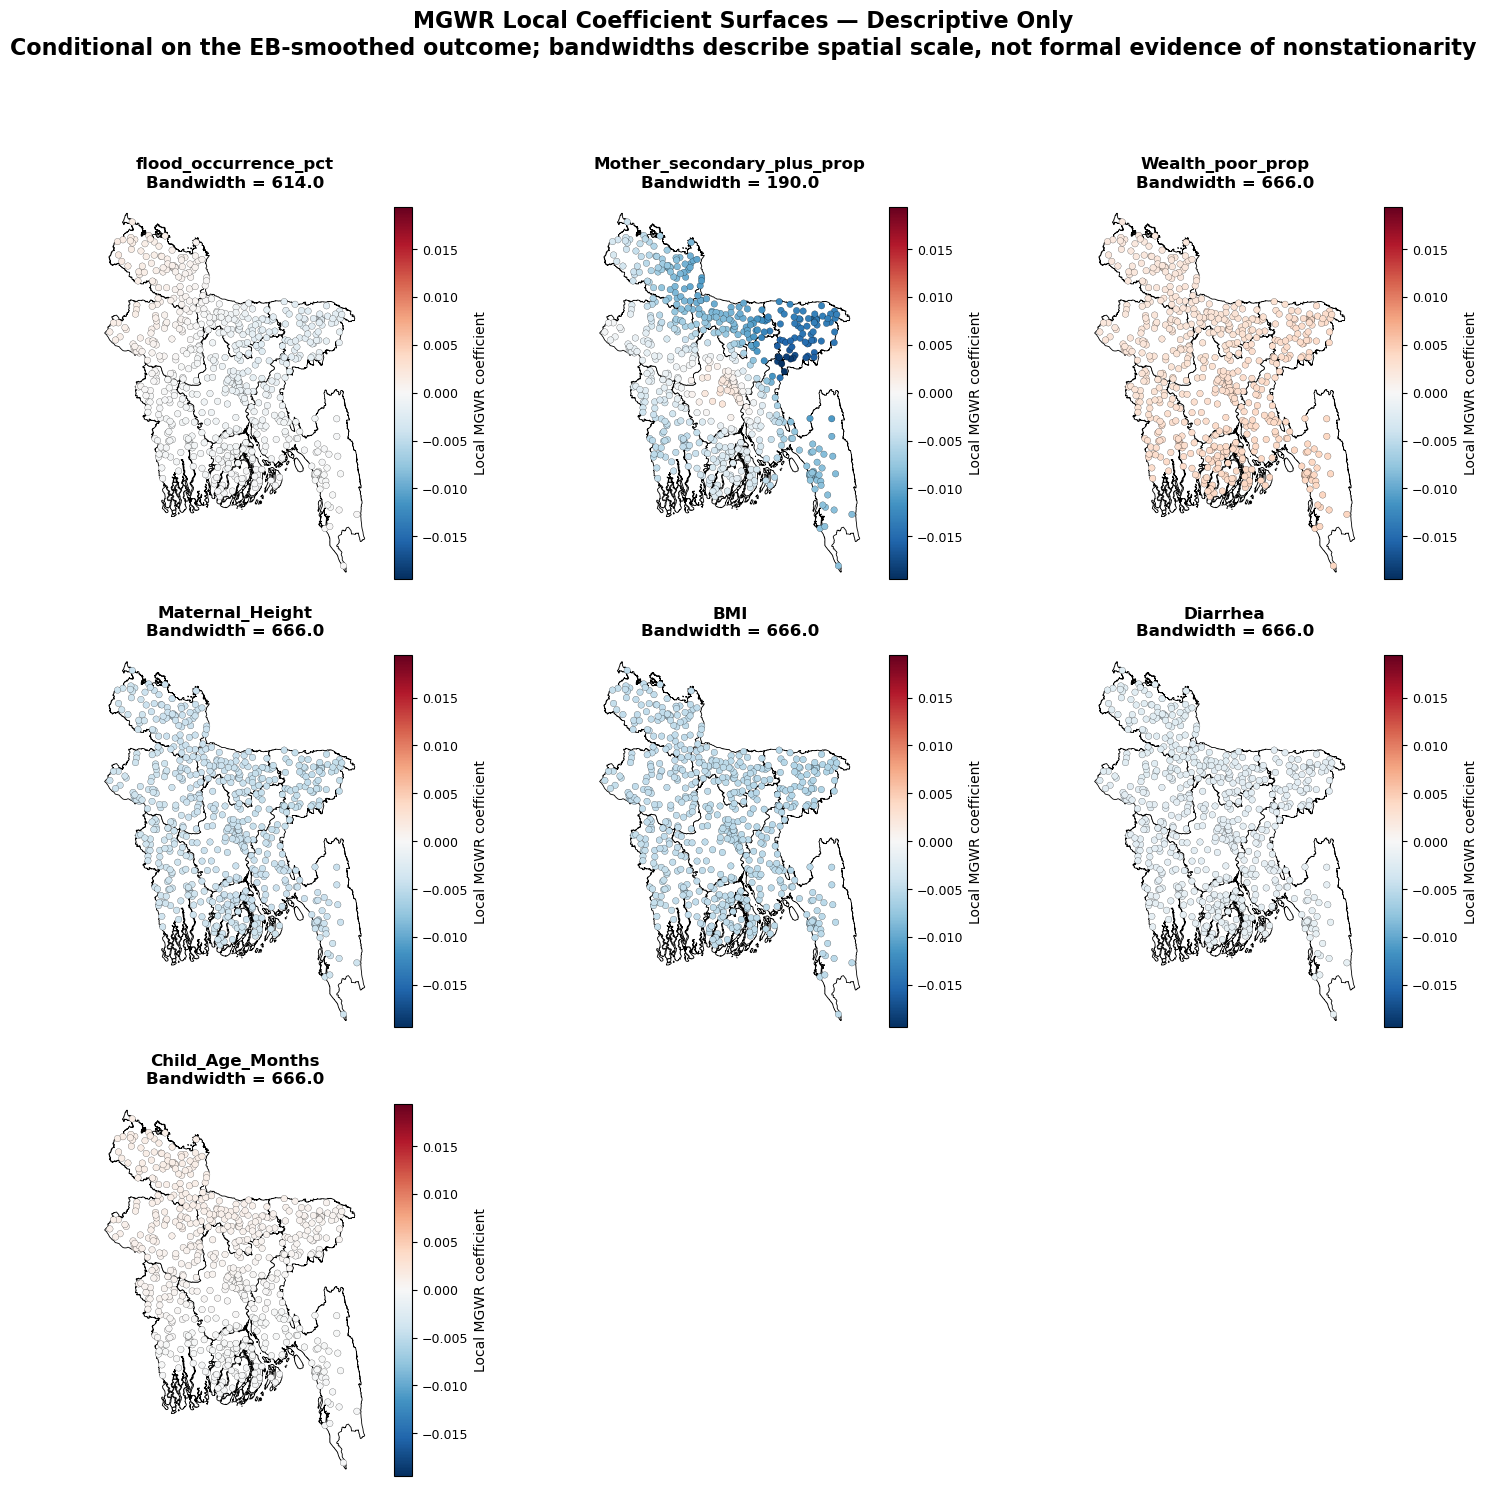

MGWR coefficient surfaces are presented descriptively.
A common symmetric coefficient scale is used across panels to support direct visual comparison.
No local adjusted-significance labels are used.
No formal claim of statistically significant coefficient nonstationarity is made because a Monte Carlo spatial-variability test was not performed.


In [25]:
# ==========================================================
# STEP 19 : MGWR LOCAL COEFFICIENT SURFACES
# DESCRIPTIVE ONLY
# NO LOCAL SIGNIFICANCE CLAIM
# REVIEWER-UPDATED FIGURE READABILITY
# ==========================================================

n_vars = len(
    GWR_VARS
)


ncols = 3


nrows = int(
    np.ceil(
        n_vars
        /
        ncols
    )
)


# ==========================================================
# COMMON SYMMETRIC COLOR SCALE ACROSS ALL MGWR PANELS
# ==========================================================

all_local_coefs = (
    mgwr_results.params[
        :,
        1:
        1 + n_vars
    ]
)


global_abs_max = float(
    np.nanmax(
        np.abs(
            all_local_coefs
        )
    )
)


if (
    not np.isfinite(
        global_abs_max
    )
    or
    global_abs_max == 0
):

    global_abs_max = 1.0


# ==========================================================
# FIGURE
# ==========================================================

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(
        15,
        5 * nrows
    )
)


axes = np.atleast_1d(
    axes
).ravel()


for j, var in enumerate(
    GWR_VARS
):

    ax = axes[j]


    coef = (
        mgwr_results.params[
            :,
            j + 1
        ]
    )


    divisions.plot(
        ax=ax,
        facecolor="white",
        edgecolor="black",
        linewidth=0.6
    )


    sc = ax.scatter(
        model_df["lon"],
        model_df["lat"],

        c=coef,

        cmap="RdBu_r",

        vmin=-global_abs_max,
        vmax=global_abs_max,

        s=22,

        edgecolors="black",
        linewidths=0.15
    )


    colorbar = fig.colorbar(
        sc,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )


    colorbar.set_label(
        "Local MGWR coefficient",
        fontsize=10
    )


    colorbar.ax.tick_params(
        labelsize=9
    )


    bandwidth_value = (
        mgwr_bandwidths[
            j + 1
        ]
    )


    ax.set_title(
        f"{var}\n"
        f"Bandwidth = {bandwidth_value:.1f}",
        fontsize=12,
        fontweight="bold"
    )


    ax.axis("off")


for ax in axes[
    n_vars:
]:

    ax.axis("off")


plt.suptitle(
    "MGWR Local Coefficient Surfaces — "
    "Descriptive Only\n"
    "Conditional on the EB-smoothed outcome; "
    "bandwidths describe spatial scale, "
    "not formal evidence of nonstationarity",
    fontsize=16,
    fontweight="bold",
    y=0.995
)


plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)


plt.show()


print(
    "MGWR coefficient surfaces are presented "
    "descriptively."
)


print(
    "A common symmetric coefficient scale is used "
    "across panels to support direct visual comparison."
)


print(
    "No local adjusted-significance labels are used."
)


print(
    "No formal claim of statistically significant "
    "coefficient nonstationarity is made because "
    "a Monte Carlo spatial-variability test was "
    "not performed."
)

In [26]:
# ==========================================================
# STEP 20 : FINAL MODEL SUMMARY
# NO MONTE CARLO / NO FDR VERSION
# ==========================================================


# ==========================================================
# 20.1 DENOMINATOR-AWARE ECOLOGICAL MODEL
# ==========================================================

print(
    "=" * 70
)

print(
    "DENOMINATOR-AWARE "
    "CLUSTER-LEVEL ECOLOGICAL MODEL"
)

print(
    "=" * 70
)


print(
    "Grouped-binomial GLM using "
    "stunted_cases and n_children."
)


print(
    "This is an unweighted cluster-level "
    "ecological analysis of the analytical sample."
)


print(
    "It is denominator-aware but is not "
    "DHS survey-design-adjusted population inference."
)


# ==========================================================
# 20.2 GROUPED-BINOMIAL RESIDUAL DIAGNOSTIC
# ==========================================================

print(
    "\n"
    + "=" * 70
)

print(
    "GROUPED-BINOMIAL RESIDUAL "
    "SPATIAL DIAGNOSTIC"
)

print(
    "=" * 70
)


display(
    grouped_residual_moran_df.round(5)
)


print(
    "Residual Moran p-values shown above are "
    "unadjusted permutation p-values."
)


# ==========================================================
# 20.3 EXPLORATORY EB-GAUSSIAN MODEL COMPARISON
# ==========================================================

comparison = pd.DataFrame(
    {
        "Model":
            [
                "Global OLS",
                "GWR",
                "MGWR"
            ],

        "AICc":
            [
                ols_aicc,
                gwr_results.aicc,
                mgwr_results.aicc
            ],

        "R2":
            [
                ols_results.rsquared,
                gwr_results.R2,
                mgwr_results.R2
            ],

        "Adjusted_R2":
            [
                ols_results.rsquared_adj,
                gwr_results.adj_R2,
                mgwr_results.adj_R2
            ]
    }
)


comparison[
    "Delta_AICc_within_EB_Gaussian_family"
] = (
    comparison["AICc"]
    -
    comparison["AICc"].min()
)


comparison = (
    comparison
    .sort_values("AICc")
    .reset_index(drop=True)
)


print(
    "\n"
    + "=" * 70
)

print(
    "EXPLORATORY EB-GAUSSIAN "
    "MODEL COMPARISON"
)

print(
    "=" * 70
)


display(
    comparison.round(5)
)


print(
    "AICc comparisons are restricted to "
    "the EB-Gaussian OLS/GWR/MGWR family."
)


print(
    "They are not directly compared with "
    "the grouped-binomial likelihood and are "
    "not used to make a general best-model claim."
)


# ==========================================================
# 20.4 GLOBAL / LOCAL NEIGHBORHOOD SENSITIVITY
# ==========================================================

print(
    "\n"
    + "=" * 70
)

print(
    "GLOBAL MORAN SENSITIVITY"
)

print(
    "=" * 70
)


display(
    knn_sensitivity_df.round(5)
)


print(
    "\nRate-adjusted LISA classifications:"
)


for k_try in K_SENSITIVITY:

    print(
        f"\nK={k_try}"
    )

    print(
        spatial_df[
            f"LISA_rate_K{k_try}"
        ].value_counts()
    )


print(
    "\nEB-smoothed Gi* classifications:"
)


for k_try in K_SENSITIVITY:

    print(
        f"\nK={k_try}"
    )

    print(
        spatial_df[
            f"Gi_EB_K{k_try}"
        ].value_counts()
    )


print(
    "\nAll local classifications above use "
    "unadjusted permutation p < 0.05 "
    "and are interpreted as exploratory "
    "neighborhood-sensitivity results."
)


# ==========================================================
# 20.5 RESIDUAL SPATIAL DIAGNOSTICS
# ==========================================================

print(
    "\n"
    + "=" * 70
)

print(
    "RESIDUAL SPATIAL DIAGNOSTICS"
)

print(
    "=" * 70
)


print(
    "\nOLS:"
)

display(
    ols_resid_moran_df.round(5)
)


print(
    "\nGWR:"
)

display(
    gwr_resid_moran_df.round(5)
)


print(
    "\nMGWR:"
)

display(
    mgwr_resid_moran_df.round(5)
)


# ==========================================================
# 20.6 MGWR SPATIAL SCALE SUMMARY
# ==========================================================

print(
    "\n"
    + "=" * 70
)

print(
    "MGWR SPATIAL-SCALE SUMMARY"
)

print(
    "=" * 70
)


display(
    mgwr_bandwidth_table.round(3)
)


print(
    "MGWR bandwidths are interpreted "
    "descriptively as estimated spatial scales."
)


print(
    "No Monte Carlo spatial-variability test "
    "was performed."
)


print(
    "Therefore no formal statistical claim "
    "of coefficient nonstationarity is made."
)


# ==========================================================
# 20.7 PREDICTOR ROBUSTNESS
# ==========================================================

robustness_summary = (
    predictor_direction_comparison[
        [
            "Variable",

            "Direction_consistent_raw_and_denominator_aware",

            "EB_agrees_with_primary_direction",

            "Full_SE",
            "Full_CI_low",
            "Full_CI_high",

            "N5_SE",
            "N5_CI_low",
            "N5_CI_high",

            "N10_SE",
            "N10_CI_low",
            "N10_CI_high",

            "Absolute_standardized_coef_change_N5_vs_full",

            "Absolute_standardized_coef_change_N10_vs_full",

            "Relative_coef_change_N5_vs_full",

            "Relative_coef_change_N10_vs_full",

            "Bootstrap_CI_2.5",

            "Bootstrap_CI_97.5",

            "Bootstrap_sign_agreement_with_full"
        ]
    ]
    .copy()
)


print(
    "\n"
    + "=" * 70
)

print(
    "FINAL PREDICTOR ROBUSTNESS SUMMARY"
)

print(
    "=" * 70
)


display(
    robustness_summary.round(5)
)


# ==========================================================
# 20.8 FINAL INTERPRETATION LIMITS
# ==========================================================

print(
    "\n"
    + "=" * 70
)

print(
    "FINAL INTERPRETATION"
)

print(
    "=" * 70
)


print(
    "1. Grouped-binomial results are "
    "sample-level cluster ecological associations."
)


print(
    "2. The grouped-binomial model is not "
    "DHS survey-design-adjusted population inference."
)


print(
    "3. EB-OLS/GWR/MGWR are exploratory analyses "
    "conditional on the EB-smoothed outcome."
)


print(
    "4. LISA and Gi* maps use unadjusted local "
    "permutation p < 0.05 and are therefore "
    "reported as exploratory spatial patterns."
)


print(
    "5. Neighborhood sensitivity is shown "
    "explicitly across K=4,5,6,8,10."
)


print(
    "6. MGWR local coefficient surfaces are "
    "descriptive only."
)


print(
    "7. No formal statistical claim of MGWR "
    "coefficient nonstationarity is made because "
    "the Monte Carlo spatial-variability test "
    "was not performed."
)


print(
    "8. DHS GPS displacement remains a limitation "
    "for local spatial and environmental analyses."
)


print(
    "9. Cluster-level associations are not "
    "interpreted as individual-level effects."
)

DENOMINATOR-AWARE CLUSTER-LEVEL ECOLOGICAL MODEL
Grouped-binomial GLM using stunted_cases and n_children.
This is an unweighted cluster-level ecological analysis of the analytical sample.
It is denominator-aware but is not DHS survey-design-adjusted population inference.

GROUPED-BINOMIAL RESIDUAL SPATIAL DIAGNOSTIC


,K,Pearson_Moran_I,Pearson_p,Deviance_Moran_I,Deviance_p
0,4,0.02231,0.1689,0.01957,0.1983
1,5,0.01830,0.1899,0.01549,0.2272
2,6,0.01634,0.1906,0.01506,0.2094
3,8,0.00606,0.3232,0.00484,0.3474
4,10,0.00377,0.3481,0.00200,0.3957


Residual Moran p-values shown above are unadjusted permutation p-values.

EXPLORATORY EB-GAUSSIAN MODEL COMPARISON


,Model,AICc,R2,Adjusted_R2,Delta_AICc_within_EB_Gaussian_family
0,MGWR,-2766.91562,0.18844,0.16208,0.00000
1,GWR,-2756.44577,0.16610,0.14378,10.46984
2,Global OLS,-2756.10821,0.14086,0.13173,10.80741


AICc comparisons are restricted to the EB-Gaussian OLS/GWR/MGWR family.
They are not directly compared with the grouped-binomial likelihood and are not used to make a general best-model claim.

GLOBAL MORAN SENSITIVITY


...


MGWR SPATIAL-SCALE SUMMARY


,Parameter,Bandwidth,Bandwidth_fraction_of_clusters
0,Intercept,661.0,0.991
1,flood_occurrence_pct,614.0,0.921
2,Mother_secondary_plus_prop,190.0,0.285
3,Wealth_poor_prop,666.0,0.999
4,Maternal_Height,666.0,0.999
5,BMI,666.0,0.999
6,Diarrhea,666.0,0.999
7,Child_Age_Months,666.0,0.999


MGWR bandwidths are interpreted descriptively as estimated spatial scales.
No Monte Carlo spatial-variability test was performed.
Therefore no formal statistical claim of coefficient nonstationarity is made.

FINAL PREDICTOR ROBUSTNESS SUMMARY


,Variable,Direction_consistent_raw_and_denominator_aware,EB_agrees_with_primary_direction,Full_SE,Full_CI_low,Full_CI_high,N5_SE,N5_CI_low,N5_CI_high,N10_SE,N10_CI_low,N10_CI_high,Absolute_standardized_coef_change_N5_vs_full,Absolute_standardized_coef_change_N10_vs_full,Relative_coef_change_N5_vs_full,Relative_coef_change_N10_vs_full,Bootstrap_CI_2.5,Bootstrap_CI_97.5,Bootstrap_sign_agreement_with_full
0,flood_occurrence_pct,True,True,0.04013,-0.05637,0.10095,0.04573,-0.08365,0.09559,0.09056,-0.10794,0.24705,0.01632,0.04727,0.73212,2.12035,-0.05494,0.09532,0.713
1,Mother_secondary_plus_prop,True,True,0.04581,-0.30828,-0.12871,0.05409,-0.29674,-0.08471,0.11617,-0.53324,-0.07788,0.02777,0.08706,0.12711,0.39847,-0.31419,-0.12862,1.000
2,Wealth_poor_prop,True,True,0.04828,0.00700,0.19624,0.05764,0.04129,0.26722,0.12466,-0.08104,0.40764,0.05264,0.06168,0.51802,0.60701,0.00246,0.20282,0.975
3,Maternal_Height,True,True,0.04850,-0.28375,-0.09362,0.06117,-0.26216,-0.02239,0.13794,-0.33818,0.20254,0.04641,0.12086,0.24597,0.64056,-0.29497,-0.09412,1.000
4,BMI,True,True,0.04958,-0.32220,-0.12784,0.06045,-0.33756,-0.10061,0.14861,-0.74284,-0.16032,0.00593,0.22656,0.02636,1.00687,-0.32982,-0.12969,1.000
5,Diarrhea,True,True,0.04878,-0.21196,-0.02073,0.05853,-0.25044,-0.02101,0.15787,-0.58240,0.03643,0.01938,0.15664,0.16657,1.34636,-0.20777,-0.02700,0.992
6,Child_Age_Months,True,True,0.04800,-0.06383,0.12432,0.06009,-0.05950,0.17607,0.15863,-0.25577,0.36607,0.02804,0.02490,0.92692,0.82327,-0.06449,0.12170,0.735



FINAL INTERPRETATION
1. Grouped-binomial results are sample-level cluster ecological associations.
2. The grouped-binomial model is not DHS survey-design-adjusted population inference.
3. EB-OLS/GWR/MGWR are exploratory analyses conditional on the EB-smoothed outcome.
4. LISA and Gi* maps use unadjusted local permutation p < 0.05 and are therefore reported as exploratory spatial patterns.
5. Neighborhood sensitivity is shown explicitly across K=4,5,6,8,10.
6. MGWR local coefficient surfaces are descriptive only.
7. No formal statistical claim of MGWR coefficient nonstationarity is made because the Monte Carlo spatial-variability test was not performed.
8. DHS GPS displacement remains a limitation for local spatial and environmental analyses.
9. Cluster-level associations are not interpreted as individual-level effects.


In [27]:
# ==========================================================
# STEP 21 : FINAL REPRODUCIBILITY / PROVENANCE RECORD
# NO MONTE CARLO / NO FDR VERSION
# ==========================================================

import sys
import json
import hashlib

from pathlib import Path

from datetime import (
    datetime,
    timezone
)

from importlib.metadata import (
    version,
    PackageNotFoundError
)


# ==========================================================
# 21.1 SOFTWARE ENVIRONMENT
# ==========================================================

packages = [

    "numpy",

    "pandas",

    "geopandas",

    "pyreadstat",

    "libpysal",

    "esda",

    "scikit-learn",

    "statsmodels",

    "mgwr",

    "matplotlib",

    "scipy"
]


environment_rows = [

    {
        "Package":
            "Python",

        "Version":
            sys.version.split()[0]
    }
]


requirements_lines = []


for package in packages:

    try:

        package_version = version(
            package
        )

    except PackageNotFoundError:

        package_version = (
            "NOT INSTALLED"
        )


    environment_rows.append(

        {
            "Package":
                package,

            "Version":
                package_version
        }
    )


    if package_version != "NOT INSTALLED":

        requirements_lines.append(

            f"{package}=={package_version}"
        )


environment_table = pd.DataFrame(
    environment_rows
)


print(
    "=" * 70
)

print(
    "REPRODUCIBILITY ENVIRONMENT"
)

print(
    "=" * 70
)


display(
    environment_table
)


# ==========================================================
# 21.2 SHA-256 FUNCTION
# ==========================================================

def sha256_file(
    path,
    chunk_size=1024 * 1024
):

    path = Path(
        path
    )


    h = hashlib.sha256()


    with open(
        path,
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )


            if not chunk:

                break


            h.update(
                chunk
            )


    return h.hexdigest()


# ==========================================================
# 21.3 FILE METADATA FUNCTION
# ==========================================================

def file_record(
    path,
    logical_input
):

    path = Path(
        path
    ).resolve()


    if not path.exists():

        raise FileNotFoundError(

            f"Required provenance file "
            f"not found: {path}"
        )


    stat = path.stat()


    return {

        "logical_input":
            logical_input,

        "path":
            str(
                path
            ),

        "size_bytes":
            int(
                stat.st_size
            ),

        "modified_utc":
            datetime.fromtimestamp(

                stat.st_mtime,

                tz=timezone.utc

            ).isoformat(),

        "sha256":
            sha256_file(
                path
            )
    }


# ==========================================================
# 21.4 SHAPEFILE COMPONENT METADATA
# ==========================================================

def shapefile_component_records(
    shp_path,
    logical_input
):

    shp_path = Path(
        shp_path
    ).resolve()


    if not shp_path.exists():

        raise FileNotFoundError(

            f"Shapefile not found: "
            f"{shp_path}"
        )


    components = sorted(

        shp_path.parent.glob(

            shp_path.stem
            +
            ".*"
        )
    )


    records = []


    for component in components:

        if component.is_file():

            records.append(

                file_record(

                    component,

                    logical_input
                )
            )


    return records


# ==========================================================
# 21.5 INPUT DATASET HASHES / METADATA
# ==========================================================

input_file_records = [

    file_record(

        ORIGINAL_BDHS_FILE,

        "Original BDHS KR file"
    ),

    file_record(

        BDHS_FILE,

        "Final analytical BDHS SAV"
    ),

    file_record(

        ENV_FILE,

        "Environmental exposure CSV"
    )
]


input_file_records.extend(

    shapefile_component_records(

        GPS_FILE,

        "DHS GPS shapefile dataset"
    )
)


input_file_records.extend(

    shapefile_component_records(

        BOUNDARY_FILE,

        "Bangladesh administrative boundary dataset"
    )
)


input_hash_table = pd.DataFrame(

    input_file_records
)


print(
    "\n"
    + "=" * 70
)

print(
    "INPUT FILE PROVENANCE / SHA-256 HASHES"
)

print(
    "=" * 70
)


display(
    input_hash_table
)


# ==========================================================
# 21.6 SOFTWARE VERSION DICTIONARY
# ==========================================================

software_versions = {

    row["Package"]:
        row["Version"]

    for row
    in environment_rows
}


# ==========================================================
# 21.7 CRS RECORD
# ==========================================================

gps_source_crs = (

    str(
        gps.crs
    )

    if gps.crs is not None

    else

    "Unknown"
)


boundary_check = gpd.read_file(

    BOUNDARY_FILE
)


boundary_source_crs = (

    str(
        boundary_check.crs
    )

    if boundary_check.crs is not None

    else

    "Unknown"
)


# ==========================================================
# 21.8 JSON-SAFE CONVERSION
# ==========================================================

def json_safe_value(
    value
):

    if isinstance(
        value,
        np.generic
    ):

        value = value.item()


    if isinstance(
        value,
        Path
    ):

        return str(
            value
        )


    if isinstance(
        value,
        set
    ):

        return sorted(
            list(
                value
            )
        )


    if isinstance(
        value,
        float
    ):

        if np.isnan(
            value
        ):

            return None


        if np.isinf(
            value
        ):

            return None


    return value


def clean_for_json(
    obj
):

    if isinstance(
        obj,
        dict
    ):

        return {

            str(k):
                clean_for_json(
                    v
                )

            for k, v
            in obj.items()
        }


    if isinstance(
        obj,
        list
    ):

        return [

            clean_for_json(
                v
            )

            for v
            in obj
        ]


    if isinstance(
        obj,
        tuple
    ):

        return [

            clean_for_json(
                v
            )

            for v
            in obj
        ]


    return json_safe_value(
        obj
    )


# ==========================================================
# 21.9 STRATA AUDIT RECORD
# ==========================================================

strata_manifest = {

    "reviewer_expected_official_number_of_strata":
        int(
            EXPECTED_DHS_STRATA
        ),

    "original_V022_unique_strata":
        int(
            len(
                raw_v022_codes
            )
        ),

    "original_V023_unique_strata":
        int(
            len(
                raw_v023_codes
            )
        ),

    "final_strata_v022_unique_strata":
        int(
            len(
                final_v022_codes
            )
        ),

    "final_strata_v023_unique_strata":
        int(
            len(
                final_v023_codes
            )
        ),

    "final_V022_codes_subset_of_original":
        bool(
            final_v022_subset_raw
        ),

    "final_V023_codes_subset_of_original":
        bool(
            final_v023_subset_raw
        ),

    "strata_variable_retained_for_provenance":
        STRATA_VARIABLE_FOR_PROVENANCE,

    "note":
        (
            "Observed strata coding is retained "
            "and reported exactly as found in the "
            "supplied original and analytical files. "
            "No artificial strata were created."
        )
}


# ==========================================================
# 21.10 SAMPLE COUNT RECORD
# ==========================================================

sample_count_manifest = {

    "original_bdhs_records":
        int(
            len(
                raw_df
            )
        ),

    "current_analytical_sav_records":
        int(
            len(
                df
            )
        ),

    "final_child_level_analytical_sample":
        int(
            len(
                child
            )
        ),

    "clusters_for_spatial_analysis":
        int(
            len(
                spatial_df
            )
        ),

    "clusters_for_gwr_mgwr":
        int(
            len(
                model_df
            )
        ),

    "children_in_spatial_analysis":
        int(

            spatial_df[
                "n_children"
            ].sum()
        ),

    "clusters_with_n_children_lt_5":
        int(

            (
                spatial_df[
                    "n_children"
                ]
                <
                5
            ).sum()
        ),

    "clusters_with_n_children_lt_10":
        int(

            (
                spatial_df[
                    "n_children"
                ]
                <
                10
            ).sum()
        )
}


# ==========================================================
# 21.11 LOCAL SPATIAL INFERENCE RECORD
# ==========================================================

local_spatial_inference_manifest = {

    "multiple_testing_correction":
        "Not applied",

    "local_alpha":
        float(
            ALPHA
        ),

    "local_classification_rule":
        (
            "Unadjusted permutation p < 0.05"
        ),

    "LISA_interpretation":
        (
            "Exploratory neighborhood-sensitivity "
            "analysis across the prespecified "
            "K values."
        ),

    "Getis_Ord_Gi_interpretation":
        (
            "Exploratory hotspot/coldspot "
            "analysis using unadjusted local "
            "permutation p-values."
        ),

    "confirmatory_hotspot_claim":
        False
}


# ==========================================================
# 21.12 MGWR INFERENCE RECORD
# ==========================================================

mgwr_inference_manifest = {

    "formal_spatial_variability_test":
        "Not performed",

    "monte_carlo_spatial_variability_test":
        False,

    "coefficient_nonstationarity_claim":
        False,

    "bandwidth_interpretation":
        (
            "MGWR bandwidths are interpreted "
            "descriptively as estimated spatial scales."
        ),

    "local_coefficient_surface_interpretation":
        (
            "MGWR local coefficient surfaces "
            "are descriptive and conditional on "
            "the EB-smoothed outcome."
        ),

    "local_adjusted_significance_labels_used":
        False
}


# ==========================================================
# 21.13 PRIMARY MODEL INTERPRETATION RECORD
# ==========================================================

primary_model_manifest = {

    "model":
        (
            "Grouped-binomial GLM"
        ),

    "analysis_unit":
        (
            "Cluster-level ecological"
        ),

    "outcome_input":
        (
            "stunted_cases and n_children"
        ),

    "denominator_aware":
        True,

    "DHS_complex_survey_design_adjusted":
        False,

    "sampling_weight_used_in_primary_model":
        False,

    "interpretation":
        (
            "Unweighted denominator-aware "
            "cluster-level ecological inference "
            "for the analytical sample."
        ),

    "nationally_representative_population_inference":
        False,

    "individual_level_effect_interpretation":
        False
}


# ==========================================================
# 21.14 EB / GWR / MGWR RECORD
# ==========================================================

eb_spatial_manifest = {

    "EB_outcome":
        (
            "Beta-binomial empirical-Bayes "
            "posterior mean of cluster stunting prevalence"
        ),

    "EB_analysis_role":
        (
            "Sample-based exploratory spatial analysis"
        ),

    "GWR_role":
        (
            "Exploratory coefficient-surface analysis "
            "conditional on the EB-smoothed outcome"
        ),

    "MGWR_role":
        (
            "Exploratory spatial-scale and "
            "coefficient-surface analysis conditional "
            "on the EB-smoothed outcome"
        ),

    "EB_uncertainty_propagated_into_GWR_MGWR":
        False
}


# ==========================================================
# 21.15 GPS / ENVIRONMENTAL PROVENANCE RECORD
# ==========================================================

spatial_provenance_manifest = {

    "dhs_gps_coordinates_displaced":
        True,

    "environmental_extraction_buffer_m":
        5000,

    "environmental_exposure_provenance":
        ENVIRONMENT_PROVENANCE,

    "gps_displacement_interpretation":
        (
            "Environmental variables were extracted "
            "using a 5 km buffer around displaced DHS "
            "cluster centroids. Local neighborhood "
            "relationships, LISA/Gi*, and GWR/MGWR "
            "results remain potentially sensitive "
            "to DHS GPS displacement."
        )
}


# ==========================================================
# 21.16 ANALYSIS CONFIGURATION
# ==========================================================

analysis_configuration = {

    "seed":
        int(
            SEED
        ),

    "alpha":
        float(
            ALPHA
        ),

    "K_sensitivity":
        [
            int(k)

            for k
            in K_SENSITIVITY
        ],

    "permutations":
        int(
            PERMUTATIONS
        ),

    "model_variables":
        list(
            GWR_VARS
        ),

    "bootstrap_repetitions":
        int(
            BOOTSTRAP_REPS
        ),

    "local_multiple_testing_correction":
        "None",

    "MGWR_Monte_Carlo_spatial_variability_test":
        "Not performed"
}


# ==========================================================
# 21.17 FULL ANALYSIS MANIFEST
# ==========================================================

analysis_manifest = {

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "notebook_completed_through_step_21":
        True,

    "project_root":
        str(
            PROJECT_ROOT
        ),

    "analysis_configuration":
        analysis_configuration,

    "survey_weight_provenance":
        DHS_WEIGHT_PROVENANCE,

    "weight_transformation_verified":
        bool(
            WEIGHT_TRANSFORMATION_VERIFIED
        ),

    "anthropometry_subsample_weight_appropriateness_verified":
        bool(
            WEIGHT_APPROPRIATENESS_VERIFIED
        ),

    "strata_audit":
        strata_manifest,

    "sample_counts":
        sample_count_manifest,

    "primary_model":
        primary_model_manifest,

    "EB_GWR_MGWR":
        eb_spatial_manifest,

    "local_spatial_inference":
        local_spatial_inference_manifest,

    "MGWR_inference":
        mgwr_inference_manifest,

    "spatial_environmental_provenance":
        spatial_provenance_manifest,

    "CRS":
        {

            "GPS_source_CRS":
                gps_source_crs,

            "boundary_source_CRS":
                boundary_source_crs,

            "map_display_CRS":
                "EPSG:4326",

            "GWR_MGWR_coordinates":
                (
                    "Longitude/latitude coordinates "
                    "with spherical=True"
                )
        },

    "software_versions":
        software_versions,

    "input_files":
        input_file_records,

    "sample_flow":
        sample_flow_df.to_dict(
            orient="records"
        )
}


analysis_manifest = clean_for_json(
    analysis_manifest
)


# ==========================================================
# 21.18 OUTPUT DIRECTORY
# ==========================================================

reproducibility_dir = (

    PROJECT_ROOT

    /

    "reproducibility"
)


reproducibility_dir.mkdir(

    parents=True,

    exist_ok=True
)


# ==========================================================
# 21.19 SAVE requirements.txt
# ==========================================================

requirements_path = (

    reproducibility_dir

    /

    "requirements.txt"
)


requirements_path.write_text(

    "\n".join(
        requirements_lines
    )

    +

    "\n",

    encoding="utf-8"
)


# ==========================================================
# 21.20 SAVE analysis_manifest.json
# ==========================================================

manifest_path = (

    reproducibility_dir

    /

    "analysis_manifest.json"
)


manifest_path.write_text(

    json.dumps(

        analysis_manifest,

        indent=2,

        ensure_ascii=False,

        allow_nan=False
    ),

    encoding="utf-8"
)


# ==========================================================
# 21.21 SAVE INPUT HASH TABLE
# ==========================================================

hash_table_path = (

    reproducibility_dir

    /

    "input_hashes.csv"
)


input_hash_table.to_csv(

    hash_table_path,

    index=False
)


# ==========================================================
# 21.22 SAVE SAMPLE FLOW
# ==========================================================

sample_flow_path = (

    reproducibility_dir

    /

    "sample_flow.csv"
)


sample_flow_df.to_csv(

    sample_flow_path,

    index=False
)


# ==========================================================
# 21.23 SAVE STRATA AUDIT
# ==========================================================

strata_audit_path = (

    reproducibility_dir

    /

    "strata_audit.csv"
)


strata_audit.to_csv(

    strata_audit_path,

    index=False
)


# ==========================================================
# 21.24 SAVE MODEL VARIABLE LIST
# ==========================================================

model_variables_path = (

    reproducibility_dir

    /

    "model_variables.txt"
)


model_variables_path.write_text(

    "\n".join(
        GWR_VARS
    )

    +

    "\n",

    encoding="utf-8"
)


# ==========================================================
# 21.25 SAVE SPATIAL SENSITIVITY TABLES
# ==========================================================

global_moran_path = (

    reproducibility_dir

    /

    "global_moran_k_sensitivity.csv"
)


knn_sensitivity_df.to_csv(

    global_moran_path,

    index=False
)


raw_lisa_path = (

    reproducibility_dir

    /

    "raw_lisa_k_sensitivity.csv"
)


raw_lisa_long.to_csv(

    raw_lisa_path,

    index=False
)


rate_lisa_path = (

    reproducibility_dir

    /

    "rate_adjusted_lisa_k_sensitivity.csv"
)


rate_lisa_long.to_csv(

    rate_lisa_path,

    index=False
)


gi_path = (

    reproducibility_dir

    /

    "getis_ord_gi_k_sensitivity.csv"
)


gi_sensitivity_long.to_csv(

    gi_path,

    index=False
)


# ==========================================================
# 21.26 SAVE RESIDUAL SPATIAL DIAGNOSTICS
# ==========================================================

grouped_resid_path = (

    reproducibility_dir

    /

    "grouped_binomial_residual_moran.csv"
)


grouped_residual_moran_df.to_csv(

    grouped_resid_path,

    index=False
)


ols_resid_path = (

    reproducibility_dir

    /

    "ols_residual_moran.csv"
)


ols_resid_moran_df.to_csv(

    ols_resid_path,

    index=False
)


gwr_resid_path = (

    reproducibility_dir

    /

    "gwr_residual_moran.csv"
)


gwr_resid_moran_df.to_csv(

    gwr_resid_path,

    index=False
)


mgwr_resid_path = (

    reproducibility_dir

    /

    "mgwr_residual_moran.csv"
)


mgwr_resid_moran_df.to_csv(

    mgwr_resid_path,

    index=False
)


# ==========================================================
# 21.27 SAVE MGWR BANDWIDTH TABLE
# ==========================================================

mgwr_bandwidth_path = (

    reproducibility_dir

    /

    "mgwr_bandwidths.csv"
)


mgwr_bandwidth_table.to_csv(

    mgwr_bandwidth_path,

    index=False
)


# ==========================================================
# 21.28 SAVE ROBUSTNESS TABLES
# ==========================================================

predictor_robustness_path = (

    reproducibility_dir

    /

    "predictor_robustness.csv"
)


predictor_direction_comparison.to_csv(

    predictor_robustness_path,

    index=False
)


bootstrap_path = (

    reproducibility_dir

    /

    "grouped_binomial_bootstrap_stability.csv"
)


bootstrap_stability_table.to_csv(

    bootstrap_path,

    index=False
)


small_denominator_path = (

    reproducibility_dir

    /

    "small_denominator_sensitivity.csv"
)


small_n_sensitivity.to_csv(

    small_denominator_path,

    index=False
)


# ==========================================================
# 21.29 FINAL OUTPUT SUMMARY
# ==========================================================

print(
    "\n"
    + "=" * 70
)

print(
    "REPRODUCIBILITY FILES SAVED"
)

print(
    "=" * 70
)


print(
    "Directory:"
)

print(
    reproducibility_dir
)


print(
    "\nrequirements.txt:"
)

print(
    requirements_path
)


print(
    "\nanalysis_manifest.json:"
)

print(
    manifest_path
)


print(
    "\ninput_hashes.csv:"
)

print(
    hash_table_path
)


print(
    "\nsample_flow.csv:"
)

print(
    sample_flow_path
)


print(
    "\nstrata_audit.csv:"
)

print(
    strata_audit_path
)


print(
    "\nmodel_variables.txt:"
)

print(
    model_variables_path
)


print(
    "\nglobal_moran_k_sensitivity.csv:"
)

print(
    global_moran_path
)


print(
    "\nraw_lisa_k_sensitivity.csv:"
)

print(
    raw_lisa_path
)


print(
    "\nrate_adjusted_lisa_k_sensitivity.csv:"
)

print(
    rate_lisa_path
)


print(
    "\ngetis_ord_gi_k_sensitivity.csv:"
)

print(
    gi_path
)


print(
    "\ngrouped_binomial_residual_moran.csv:"
)

print(
    grouped_resid_path
)


print(
    "\nols_residual_moran.csv:"
)

print(
    ols_resid_path
)


print(
    "\ngwr_residual_moran.csv:"
)

print(
    gwr_resid_path
)


print(
    "\nmgwr_residual_moran.csv:"
)

print(
    mgwr_resid_path
)


print(
    "\nmgwr_bandwidths.csv:"
)

print(
    mgwr_bandwidth_path
)


print(
    "\npredictor_robustness.csv:"
)

print(
    predictor_robustness_path
)


print(
    "\ngrouped_binomial_bootstrap_stability.csv:"
)

print(
    bootstrap_path
)


print(
    "\nsmall_denominator_sensitivity.csv:"
)

print(
    small_denominator_path
)


print(
    "\n"
    + "=" * 70
)

print(
    "FINAL REPRODUCIBILITY RECORD COMPLETE"
)

print(
    "=" * 70
)


print(
    "\nMonte Carlo MGWR spatial-variability test:"
)

print(
    "NOT PERFORMED"
)


print(
    "\nLocal FDR correction:"
)

print(
    "NOT APPLIED"
)


print(
    "\nLISA / Gi* interpretation:"
)

print(
    "Exploratory local spatial patterns using "
    "unadjusted permutation p < 0.05."
)


print(
    "\nMGWR interpretation:"
)

print(
    "Descriptive spatial-scale and local "
    "coefficient-surface analysis; no formal "
    "coefficient nonstationarity claim."
)

REPRODUCIBILITY ENVIRONMENT


,Package,Version
0,Python,3.13.9
1,numpy,2.3.5
2,pandas,2.3.3
3,geopandas,1.1.3
4,pyreadstat,1.3.4
5,libpysal,4.14.1
6,esda,2.8.2
7,scikit-learn,1.7.2
8,statsmodels,0.14.5
9,mgwr,2.2.1



INPUT FILE PROVENANCE / SHA-256 HASHES


,logical_input,path,size_bytes,modified_utc,sha256
0,Original BDHS KR file,F:\Thesis\BDKR81FL.SAV,13704394,2026-03-28T04:02:28+00:00,449e96efeeccd0eae220e0e969c32ed4fd820ea9c63292...
1,Final analytical BDHS SAV,F:\Thesis\Stunting_Final .SAV,1109458,2026-09-22T15:30:15+00:00,f6991f03a7f0d45720d541964ec4870061ff9273370644...
2,Environmental exposure CSV,F:\Thesis\GPS DATA\bdhs_env_2022.csv,109171,2026-05-06T09:03:33.650501+00:00,48d8a2fccfd1fa74b78d0e85697f6897a6060b2d4b4566...
3,DHS GPS shapefile dataset,F:\Thesis\GPS DATA\Division\BDGE81FL.cpg,5,2023-10-03T20:40:12+00:00,3ad3031f5503a4404af825262ee8232cc04d4ea6683d42...
4,DHS GPS shapefile dataset,F:\Thesis\GPS DATA\Division\BDGE81FL.dbf,2158148,2023-10-03T20:40:12+00:00,d1fcf10a379636bd1e2de65518050dfbb77a908b93b69e...
5,DHS GPS shapefile dataset,F:\Thesis\GPS DATA\Division\BDGE81FL.prj,145,2023-10-02T17:43:40+00:00,a02a27b1d1982c8516d83398e85a3c8b1aef1713c13ef4...
6,DHS GPS shapefile dataset,F:\Thesis\GPS DATA\Division\BDGE81FL.sbn,6972,2023-10-02T17:43:40+00:00,0be54455cdb302080c0dc3adfb345bb4bc87d95374ecf2...
7,DHS GPS shapefile dataset,F:\Thesis\GPS DATA\Division\BDGE81FL.sbx,612,2023-10-02T17:43:40+00:00,7e4b3f95a5169cadc9dd2193b7ab6276d704afeed26aec...
8,DHS GPS shapefile dataset,F:\Thesis\GPS DATA\Division\BDGE81FL.shp,18972,2023-10-02T17:43:40+00:00,926b157aa75c83ce39274f0253a785239f6f79a7f38209...
9,DHS GPS shapefile dataset,F:\Thesis\GPS DATA\Division\BDGE81FL.shp.xml,37405,2023-10-05T22:17:20+00:00,3162243dde224fffa56f8c5db2d67424795e8493a8221b...



REPRODUCIBILITY FILES SAVED
Directory:
F:\Thesis\reproducibility

requirements.txt:
F:\Thesis\reproducibility\requirements.txt

analysis_manifest.json:
F:\Thesis\reproducibility\analysis_manifest.json

input_hashes.csv:
F:\Thesis\reproducibility\input_hashes.csv

sample_flow.csv:
F:\Thesis\reproducibility\sample_flow.csv

strata_audit.csv:
F:\Thesis\reproducibility\strata_audit.csv

model_variables.txt:
F:\Thesis\reproducibility\model_variables.txt

global_moran_k_sensitivity.csv:
F:\Thesis\reproducibility\global_moran_k_sensitivity.csv

raw_lisa_k_sensitivity.csv:
F:\Thesis\reproducibility\raw_lisa_k_sensitivity.csv

rate_adjusted_lisa_k_sensitivity.csv:
F:\Thesis\reproducibility\rate_adjusted_lisa_k_sensitivity.csv

getis_ord_gi_k_sensitivity.csv:
F:\Thesis\reproducibility\getis_ord_gi_k_sensitivity.csv

grouped_binomial_residual_moran.csv:
F:\Thesis\reproducibility\grouped_binomial_residual_moran.csv

ols_residual_moran.csv:
F:\Thesis\reproducibility\ols_residual_moran.csv

gwr_res

In [33]:
# ==========================================================
# STEP 22 : FINAL REVIEWER-ALIGNED SPATIAL UPDATE
#
# Reviewer comments addressed:
# 5  - MGWR in-sample R2 interpretation
# 6  - ecological / non-causal interpretation
# 8  - environmental temporal mismatch
# 9  - DHS GPS displacement / 5-km buffer limitation
# 14 - denominator-aware grouped-binomial sensitivity rationale
# 15 - unequal cluster-size limitation
# 18 - exploratory hotspot terminology
# 19 - diarrhea inverse association interpretation
#
# IMPORTANT:
# This step does NOT refit or alter any model.
# It consolidates reviewer-safe interpretation
# and exports a reproducible reviewer summary.
# ==========================================================

from pathlib import Path
import numpy as np
import pandas as pd


print("=" * 80)
print("STEP 22 — FINAL REVIEWER-ALIGNED SPATIAL UPDATE")
print("=" * 80)


# ==========================================================
# 22.1 OUTPUT DIRECTORY
# ==========================================================

REVIEWER_SPATIAL_DIR = (
    PROJECT_ROOT
    /
    "Reviewer_Final_Outputs"
    /
    "Spatial_Reviewer_Update"
)

REVIEWER_SPATIAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ==========================================================
# 22.2 COMMENT 5
# MGWR / GWR / OLS — IN-SAMPLE MODEL FIT ONLY
# ==========================================================

reviewer_model_comparison = pd.DataFrame(
    {
        "Model": [
            "Global OLS",
            "GWR",
            "MGWR"
        ],

        "AICc": [
            float(ols_aicc),
            float(gwr_results.aicc),
            float(mgwr_results.aicc)
        ],

        "R2": [
            float(ols_results.rsquared),
            float(gwr_results.R2),
            float(mgwr_results.R2)
        ],

        "Adjusted_R2": [
            float(ols_results.rsquared_adj),
            float(gwr_results.adj_R2),
            float(mgwr_results.adj_R2)
        ],

        "Performance_Type": [
            "In-sample",
            "In-sample",
            "In-sample"
        ],

        "Interpretation": [
            "Global EB-Gaussian model fit",
            "Exploratory local EB-Gaussian model fit",
            "Exploratory multiscale EB-Gaussian model fit"
        ]
    }
)


reviewer_model_comparison[
    "Delta_AICc_within_EB_Gaussian_family"
] = (
    reviewer_model_comparison["AICc"]
    -
    reviewer_model_comparison["AICc"].min()
)


print("\n" + "=" * 80)
print("COMMENT 5 — IN-SAMPLE EB-GAUSSIAN MODEL FIT")
print("=" * 80)

display(
    reviewer_model_comparison.round(4)
)


best_r2_row = (
    reviewer_model_comparison
    .sort_values(
        "R2",
        ascending=False
    )
    .iloc[0]
)


print(
    "\nReviewer-safe interpretation:"
)

print(
    f"{best_r2_row['Model']} achieved the highest "
    f"in-sample R² ({best_r2_row['R2']:.4f}) "
    f"and adjusted R² ({best_r2_row['Adjusted_R2']:.4f}) "
    "among the fitted EB-Gaussian spatial specifications."
)

print(
    "These are in-sample goodness-of-fit measures and "
    "must not be interpreted as evidence that this model "
    "has demonstrably superior out-of-sample predictive performance."
)

print(
    "No spatial cross-validation of OLS/GWR/MGWR was used "
    "for model selection; therefore the comparison is descriptive."
)


# ==========================================================
# 22.3 COMMENT 6
# ECOLOGICAL INTERPRETATION
# ==========================================================

print("\n" + "=" * 80)
print("COMMENT 6 — ECOLOGICAL INTERPRETATION")
print("=" * 80)


print(
    "OLS, GWR, MGWR, and grouped-binomial analyses operate "
    "at the DHS-cluster level."
)

print(
    "Maternal height, BMI, maternal education, morbidity, "
    "and socioeconomic measures are cluster-level aggregated "
    "means or proportions."
)

print(
    "Accordingly, estimated coefficients represent ecological "
    "cluster-level associations and must not be interpreted "
    "as individual-level associations or causal effects."
)


# ==========================================================
# 22.4 COMMENT 8
# TEMPORAL MISMATCH OF ENVIRONMENTAL DATA
# ==========================================================

print("\n" + "=" * 80)
print("COMMENT 8 — ENVIRONMENTAL TEMPORAL MISMATCH")
print("=" * 80)


environment_temporal_summary = pd.DataFrame(
    [
        {
            "Environmental_indicator":
                "Flood occurrence percentage",

            "Source":
                ENVIRONMENT_PROVENANCE[
                    "source_dataset"
                ],

            "Temporal_definition":
                ENVIRONMENT_PROVENANCE[
                    "documented_temporal_definition"
                ],

            "Interpretation":
                (
                    "Contextual/background environmental indicator; "
                    "not assumed to represent a temporally aligned "
                    "individual exposure at the time of child measurement."
                )
        }
    ]
)


display(
    environment_temporal_summary
)


print(
    "\nEnvironmental and geospatial covariates originate "
    "from source products covering temporal windows that do not "
    "necessarily coincide with the timing of individual child measurements."
)

print(
    "They are therefore interpreted as contextual or background "
    "environmental indicators rather than temporally aligned "
    "individual-level exposures."
)

print(
    "Causal exposure interpretations are not made."
)


# ==========================================================
# 22.5 COMMENT 9
# 5-KM BUFFER / DHS GPS DISPLACEMENT
# ==========================================================

print("\n" + "=" * 80)
print("COMMENT 9 — DHS GPS DISPLACEMENT")
print("=" * 80)


print(
    "Environmental covariates were summarized within a "
    "5-km buffer around each DHS cluster coordinate."
)

print(
    "The buffer was intended to REDUCE sensitivity to "
    "DHS coordinate displacement; it does NOT eliminate "
    "location uncertainty."
)

print(
    "Residual GPS displacement may therefore introduce "
    "exposure misclassification and uncertainty in "
    "neighborhood definitions, LISA/Gi*, GWR, and MGWR analyses."
)


# ==========================================================
# 22.6 COMMENT 14
# GROUPED-BINOMIAL DENOMINATOR-AWARE SENSITIVITY
# ==========================================================

print("\n" + "=" * 80)
print("COMMENT 14 — GROUPED-BINOMIAL SENSITIVITY PURPOSE")
print("=" * 80)


print(
    "The grouped-binomial model was used as a "
    "denominator-aware sensitivity analysis."
)

print(
    "Unlike EB-smoothed prevalence, this model directly "
    "models the number of stunted children relative to the "
    "number of observed children in each DHS cluster."
)

print(
    "Its purpose is to assess whether the principal "
    "cluster-level ecological patterns remain evident when "
    "using observed stunted case counts and cluster denominators "
    "rather than relying only on EB-smoothed prevalence."
)

print(
    "This model remains an unweighted cluster-level ecological "
    "analysis and is not DHS survey-design-adjusted "
    "population-level inference."
)


# ==========================================================
# 22.7 COMMENT 15
# UNEQUAL CLUSTER SIZES
# ==========================================================

print("\n" + "=" * 80)
print("COMMENT 15 — UNEQUAL CLUSTER SIZE LIMITATION")
print("=" * 80)


cluster_size_summary = pd.DataFrame(
    {
        "Statistic": [
            "Number of clusters",
            "Minimum children per cluster",
            "Median children per cluster",
            "Mean children per cluster",
            "Maximum children per cluster",
            "Clusters with n < 5",
            "Clusters with n < 10"
        ],

        "Value": [
            int(len(spatial_df)),

            int(
                spatial_df[
                    "n_children"
                ].min()
            ),

            float(
                spatial_df[
                    "n_children"
                ].median()
            ),

            float(
                spatial_df[
                    "n_children"
                ].mean()
            ),

            int(
                spatial_df[
                    "n_children"
                ].max()
            ),

            int(
                (
                    spatial_df[
                        "n_children"
                    ]
                    < 5
                ).sum()
            ),

            int(
                (
                    spatial_df[
                        "n_children"
                    ]
                    < 10
                ).sum()
            )
        ]
    }
)


display(
    cluster_size_summary.round(3)
)


print(
    "\nDHS cluster sample sizes vary."
)

print(
    "The OLS/GWR/MGWR analyses treat clusters as spatial "
    "observations and do not necessarily give larger clusters "
    "proportionally greater influence."
)

print(
    "These models are therefore interpreted as exploratory "
    "cluster-level spatial analyses rather than "
    "individual-level population regression models."
)

print(
    "The grouped-binomial sensitivity analysis partially "
    "addresses denominator variation by explicitly modeling "
    "stunted case counts relative to cluster denominators."
)


# ==========================================================
# 22.8 COMMENT 18
# MODERATE HOTSPOT TERMINOLOGY
# ==========================================================

print("\n" + "=" * 80)
print("COMMENT 18 — EXPLORATORY SPATIAL PATTERNS")
print("=" * 80)


print(
    "Global Moran's I and local LISA/Gi* results are "
    "interpreted as neighborhood-sensitive exploratory "
    "spatial patterns."
)

print(
    "Because results vary across prespecified K-neighborhoods "
    "and local permutation p-values are unadjusted, "
    "the analysis does not claim stable or definitive "
    "national hotspot regions."
)

print(
    "Preferred terminology:"
)

print(
    "  • exploratory local concentration patterns"
)

print(
    "  • neighborhood-sensitive spatial patterns"
)


# ==========================================================
# 22.9 COMMENT 19
# DIARRHEA ASSOCIATION
# ==========================================================

print("\n" + "=" * 80)
print("COMMENT 19 — DIARRHEA ECOLOGICAL ASSOCIATION")
print("=" * 80)


# Try to extract grouped-binomial diarrhea result if available
diarrhea_result = None


if (
    "grouped_binomial_table"
    in globals()
):

    gb_table_tmp = grouped_binomial_table.copy()

    possible_name_cols = [
        "Variable",
        "Term",
        "Predictor"
    ]

    name_col = next(
        (
            c
            for c in possible_name_cols
            if c in gb_table_tmp.columns
        ),
        None
    )

    if name_col is not None:

        match = (
            gb_table_tmp[
                name_col
            ]
            .astype(str)
            .str.contains(
                "Diarrhea",
                case=False,
                na=False
            )
        )

        if match.any():

            diarrhea_result = (
                gb_table_tmp
                .loc[match]
                .copy()
            )


if diarrhea_result is not None:

    print(
        "\nGrouped-binomial diarrhea result:"
    )

    display(
        diarrhea_result
    )


print(
    "\nThe inverse cluster-level association involving "
    "diarrhea must NOT be interpreted as a protective effect."
)

print(
    "Possible explanations include ecological aggregation, "
    "residual confounding, temporal mismatch, measurement "
    "differences, reverse temporal ordering, and other "
    "cluster-level mechanisms."
)

print(
    "The finding is descriptive/ecological and does not "
    "establish an individual-level protective association."
)


# ==========================================================
# 22.10 REVIEWER-SAFE SUMMARY TABLE
# ==========================================================

reviewer_spatial_summary = pd.DataFrame(
    [
        {
            "Reviewer_Comment": 5,
            "Issue": "MGWR fit",
            "Reviewer_aligned_interpretation":
                (
                    "MGWR R² and adjusted R² are explicitly "
                    "reported as in-sample goodness-of-fit measures; "
                    "no superior predictive-performance claim."
                )
        },

        {
            "Reviewer_Comment": 6,
            "Issue": "Ecological interpretation",
            "Reviewer_aligned_interpretation":
                (
                    "OLS/GWR/MGWR and grouped-binomial estimates "
                    "are cluster-level ecological associations, "
                    "not individual or causal effects."
                )
        },

        {
            "Reviewer_Comment": 8,
            "Issue": "Environmental temporal mismatch",
            "Reviewer_aligned_interpretation":
                (
                    "Environmental covariates are contextual/background "
                    "indicators and are not assumed to be temporally "
                    "aligned individual exposures."
                )
        },

        {
            "Reviewer_Comment": 9,
            "Issue": "GPS displacement",
            "Reviewer_aligned_interpretation":
                (
                    "5-km buffering reduces but does not eliminate "
                    "sensitivity to DHS GPS displacement."
                )
        },

        {
            "Reviewer_Comment": 14,
            "Issue": "Grouped-binomial sensitivity",
            "Reviewer_aligned_interpretation":
                (
                    "Used to test robustness of ecological patterns "
                    "when modeling stunted counts relative to "
                    "cluster denominators."
                )
        },

        {
            "Reviewer_Comment": 15,
            "Issue": "Unequal cluster sizes",
            "Reviewer_aligned_interpretation":
                (
                    "Spatial models treat clusters as observations "
                    "and do not necessarily weight larger clusters "
                    "proportionally more."
                )
        },

        {
            "Reviewer_Comment": 18,
            "Issue": "Hotspot terminology",
            "Reviewer_aligned_interpretation":
                (
                    "Results described as exploratory local "
                    "concentration / neighborhood-sensitive patterns."
                )
        },

        {
            "Reviewer_Comment": 19,
            "Issue": "Diarrhea association",
            "Reviewer_aligned_interpretation":
                (
                    "Inverse ecological association is not interpreted "
                    "as a protective effect."
                )
        }
    ]
)


print("\n" + "=" * 80)
print("FINAL REVIEWER SPATIAL SUMMARY")
print("=" * 80)

display(
    reviewer_spatial_summary
)


# ==========================================================
# 22.11 SAVE OUTPUTS
# ==========================================================

reviewer_model_comparison.to_csv(
    REVIEWER_SPATIAL_DIR
    /
    "Comment5_in_sample_OLS_GWR_MGWR_comparison.csv",
    index=False
)


environment_temporal_summary.to_csv(
    REVIEWER_SPATIAL_DIR
    /
    "Comment8_environmental_temporal_context.csv",
    index=False
)


cluster_size_summary.to_csv(
    REVIEWER_SPATIAL_DIR
    /
    "Comment15_cluster_size_summary.csv",
    index=False
)


reviewer_spatial_summary.to_csv(
    REVIEWER_SPATIAL_DIR
    /
    "Reviewer_spatial_interpretation_summary.csv",
    index=False
)


print("\n" + "=" * 80)
print("STEP 22 COMPLETE")
print("=" * 80)


print(
    "✓ Comment 5 — in-sample MGWR interpretation added."
)

print(
    "✓ Comment 6 — ecological/non-causal interpretation added."
)

print(
    "✓ Comment 8 — environmental temporal mismatch added."
)

print(
    "✓ Comment 9 — 5-km buffer limitation clarified."
)

print(
    "✓ Comment 14 — grouped-binomial rationale clarified."
)

print(
    "✓ Comment 15 — unequal cluster-size limitation added."
)

print(
    "✓ Comment 18 — exploratory hotspot terminology added."
)

print(
    "✓ Comment 19 — diarrhea protective-effect interpretation rejected."
)

print(
    "\nNo spatial model was refitted or changed."
)

STEP 22 — FINAL REVIEWER-ALIGNED SPATIAL UPDATE

COMMENT 5 — IN-SAMPLE EB-GAUSSIAN MODEL FIT


,Model,AICc,R2,Adjusted_R2,Performance_Type,Interpretation,Delta_AICc_within_EB_Gaussian_family
0,Global OLS,-2756.1082,0.1409,0.1317,In-sample,Global EB-Gaussian model fit,10.8074
1,GWR,-2756.4458,0.1661,0.1438,In-sample,Exploratory local EB-Gaussian model fit,10.4698
2,MGWR,-2766.9156,0.1884,0.1621,In-sample,Exploratory multiscale EB-Gaussian model fit,0.0000



Reviewer-safe interpretation:
MGWR achieved the highest in-sample R² (0.1884) and adjusted R² (0.1621) among the fitted EB-Gaussian spatial specifications.
These are in-sample goodness-of-fit measures and must not be interpreted as evidence that this model has demonstrably superior out-of-sample predictive performance.
No spatial cross-validation of OLS/GWR/MGWR was used for model selection; therefore the comparison is descriptive.

COMMENT 6 — ECOLOGICAL INTERPRETATION
OLS, GWR, MGWR, and grouped-binomial analyses operate at the DHS-cluster level.
Maternal height, BMI, maternal education, morbidity, and socioeconomic measures are cluster-level aggregated means or proportions.
Accordingly, estimated coefficients represent ecological cluster-level associations and must not be interpreted as individual-level associations or causal effects.

COMMENT 8 — ENVIRONMENTAL TEMPORAL MISMATCH


,Environmental_indicator,Source,Temporal_definition,Interpretation
0,Flood occurrence percentage,JRC Global Surface Water — Monthly History v1.4,2000-2022 historical flood occurrence,Contextual/background environmental indicator;...



Environmental and geospatial covariates originate from source products covering temporal windows that do not necessarily coincide with the timing of individual child measurements.
They are therefore interpreted as contextual or background environmental indicators rather than temporally aligned individual-level exposures.
Causal exposure interpretations are not made.

COMMENT 9 — DHS GPS DISPLACEMENT
Environmental covariates were summarized within a 5-km buffer around each DHS cluster coordinate.
The buffer was intended to REDUCE sensitivity to DHS coordinate displacement; it does NOT eliminate location uncertainty.
Residual GPS displacement may therefore introduce exposure misclassification and uncertainty in neighborhood definitions, LISA/Gi*, GWR, and MGWR analyses.

COMMENT 14 — GROUPED-BINOMIAL SENSITIVITY PURPOSE
The grouped-binomial model was used as a denominator-aware sensitivity analysis.
Unlike EB-smoothed prevalence, this model directly models the number of stunted children

...


DHS cluster sample sizes vary.
The OLS/GWR/MGWR analyses treat clusters as spatial observations and do not necessarily give larger clusters proportionally greater influence.
These models are therefore interpreted as exploratory cluster-level spatial analyses rather than individual-level population regression models.
The grouped-binomial sensitivity analysis partially addresses denominator variation by explicitly modeling stunted case counts relative to cluster denominators.

COMMENT 18 — EXPLORATORY SPATIAL PATTERNS
Global Moran's I and local LISA/Gi* results are interpreted as neighborhood-sensitive exploratory spatial patterns.
Because results vary across prespecified K-neighborhoods and local permutation p-values are unadjusted, the analysis does not claim stable or definitive national hotspot regions.
Preferred terminology:
  • exploratory local concentration patterns
  • neighborhood-sensitive spatial patterns

COMMENT 19 — DIARRHEA ECOLOGICAL ASSOCIATION

Grouped-binomial diarrh

,Variable,Coef_log_odds,SE,p_value,CI_low,CI_high,Odds_Ratio,OR_CI_low,OR_CI_high,Significant
6,Diarrhea,-0.116344,0.048785,0.017086,-0.211961,-0.020728,0.890169,0.808997,0.979485,True



The inverse cluster-level association involving diarrhea must NOT be interpreted as a protective effect.
Possible explanations include ecological aggregation, residual confounding, temporal mismatch, measurement differences, reverse temporal ordering, and other cluster-level mechanisms.
The finding is descriptive/ecological and does not establish an individual-level protective association.

FINAL REVIEWER SPATIAL SUMMARY


,Reviewer_Comment,Issue,Reviewer_aligned_interpretation
0,5,MGWR fit,MGWR R² and adjusted R² are explicitly reporte...
1,6,Ecological interpretation,OLS/GWR/MGWR and grouped-binomial estimates ar...
2,8,Environmental temporal mismatch,Environmental covariates are contextual/backgr...
3,9,GPS displacement,5-km buffering reduces but does not eliminate ...
4,14,Grouped-binomial sensitivity,Used to test robustness of ecological patterns...
5,15,Unequal cluster sizes,Spatial models treat clusters as observations ...
6,18,Hotspot terminology,Results described as exploratory local concent...
7,19,Diarrhea association,Inverse ecological association is not interpre...



STEP 22 COMPLETE
✓ Comment 5 — in-sample MGWR interpretation added.
✓ Comment 6 — ecological/non-causal interpretation added.
✓ Comment 8 — environmental temporal mismatch added.
✓ Comment 9 — 5-km buffer limitation clarified.
✓ Comment 14 — grouped-binomial rationale clarified.
✓ Comment 15 — unequal cluster-size limitation added.
✓ Comment 18 — exploratory hotspot terminology added.
✓ Comment 19 — diarrhea protective-effect interpretation rejected.

No spatial model was refitted or changed.


In [34]:

from pathlib import Path
import shutil

# Existing reviewer analysis folder
SOURCE = Path(r"F:\Thesis\Reviewer_Additional_Analyses")

# Final manuscript supplementary folder
DESTINATION = Path(r"F:\Thesis\Suplementary files")
DESTINATION.mkdir(parents=True, exist_ok=True)

# ONLY confirmed supplementary submission files
SUPPLEMENTARY_FILES = [
    "Supplementary_Table_S1_Final.xlsx",
]

copied = []
missing = []

for filename in SUPPLEMENTARY_FILES:
    src = SOURCE / filename
    dst = DESTINATION / filename

    if src.is_file():
        shutil.copy2(src, dst)
        copied.append(filename)
        print(f"COPIED: {filename}")
    else:
        missing.append(filename)
        print(f"NOT FOUND: {filename}")

print("\n--- Supplementary File Summary ---")
print("Copied:", len(copied))
print("Missing:", len(missing))
print("Location:", DESTINATION)

if missing:
    print("\nFiles requiring attention:")
    for filename in missing:
        print("-", filename)


COPIED: Supplementary_Table_S1_Final.xlsx

--- Supplementary File Summary ---
Copied: 1
Missing: 0
Location: F:\Thesis\Suplementary files


In [41]:

import json
import base64
from pathlib import Path

# Correct notebook location
NOTEBOOK = Path(r"C:\Users\Tc\Spatial Final(Stunting).ipynb")

# Your requested output folder
SAVE_DIR = Path(r"F:\Thesis\Suplementary files")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Load notebook
with NOTEBOOK.open("r", encoding="utf-8") as f:
    nb = json.load(f)

# Extract saved PNG figures
count = 0

for cell_idx, cell in enumerate(nb["cells"]):
    if cell.get("cell_type") != "code":
        continue

    for output_idx, output in enumerate(cell.get("outputs", [])):
        image_data = output.get("data", {}).get("image/png")

        if image_data is None:
            continue

        if isinstance(image_data, list):
            image_data = "".join(image_data)

        count += 1
        filename = (
            f"Spatial_Inspect_{count:02d}_"
            f"Cell_{cell_idx}.png"
        )

        path = SAVE_DIR / filename
        path.write_bytes(base64.b64decode(image_data))

        print("SAVED:", filename)

print("\nTotal images exported:", count)
print("Location:", SAVE_DIR)


SAVED: Spatial_Inspect_01_Cell_6.png
SAVED: Spatial_Inspect_02_Cell_7.png
SAVED: Spatial_Inspect_03_Cell_10.png
SAVED: Spatial_Inspect_04_Cell_10.png
SAVED: Spatial_Inspect_05_Cell_16.png
SAVED: Spatial_Inspect_06_Cell_19.png

Total images exported: 6
Location: F:\Thesis\Suplementary files
